In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Import the data
* Import statistics data that describe countries in one point

In [2]:
clusters_df = pd.read_parquet('../data/clusters/clusters_kmean_plusplus.parquet')

In [3]:
clusters_df.head()

,Country,ISO_A3,cluster,Continent
0,Australia,AUS,2,Oceania
1,Austria,AUT,1,Europe
2,Belgium,BEL,1,Europe
3,Brazil,BRA,2,America
4,Bulgaria,BGR,1,Europe


In [4]:
hpi_winsorized = pd.read_parquet('../data/hpi_index_winsorized.parquet')

In [5]:
hpi_winsorized.head()

,Year,Australia,Austria,Belgium,Brazil,Bulgaria,Canada,Chile,Colombia,Croatia,...,Slovenia,South Africa,South Korea,Spain,Sweden,Switzerland,Thailand,Turkey,USA,United Kingdom
0,2010,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,...,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00
1,2011,97.84,104.22,103.58,110.52,94.49,105.75,110.52,107.89,100.16,...,102.72,103.59,105.23,94.49,102.58,107.51,104.26,108.80,97.24,98.54
2,2012,97.53,117.13,106.02,124.02,92.69,110.62,124.02,118.79,98.62,...,95.63,108.41,108.25,88.37,103.86,113.72,107.63,120.68,101.82,98.92
3,2013,103.99,122.59,107.59,136.52,90.65,112.76,136.52,130.06,94.70,...,90.62,115.41,107.80,85.58,109.22,118.30,115.99,134.46,111.83,101.46
4,2014,113.41,126.79,107.22,151.67,91.95,118.86,151.67,140.75,93.19,...,84.64,123.99,109.43,84.64,119.52,121.46,127.07,151.25,118.88,109.60


### Search outliers
* Look for outliers
* Plot the boxplot for feature with more outliers

In [6]:
hpi_winsorized.shape

(15, 53)

In [7]:
clusters_df.shape

(53, 4)

In [8]:
def plot_hpi_boxplots_by_year(df_hpi, year_column='Year', figsize=(14, 6)):
    """
    Plots box plots of HPI values for each year to visualize outliers.

    Parameters:
    - df_hpi: DataFrame with 'Year' column and HPI values per country
    - year_column: Name of the column containing years (default: 'Year')
    - figsize: Size of the plot (default: (14, 6))
    """

    # Step 1: Melt the DataFrame to long format
    df_long = df_hpi.melt(id_vars=year_column, var_name='Country', value_name='HPI')

    # Step 2: Create boxplot grouped by year
    plt.figure(figsize=figsize)
    df_long.boxplot(column='HPI', by=year_column, grid=False, showfliers=True)

    # Step 3: Customize plot
    plt.title("Box Plot of HPI Values by Year")
    plt.suptitle("")  # Remove default title
    plt.xlabel("Year")
    plt.ylabel("House Price Index (HPI)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

<Figure size 1400x600 with 0 Axes>

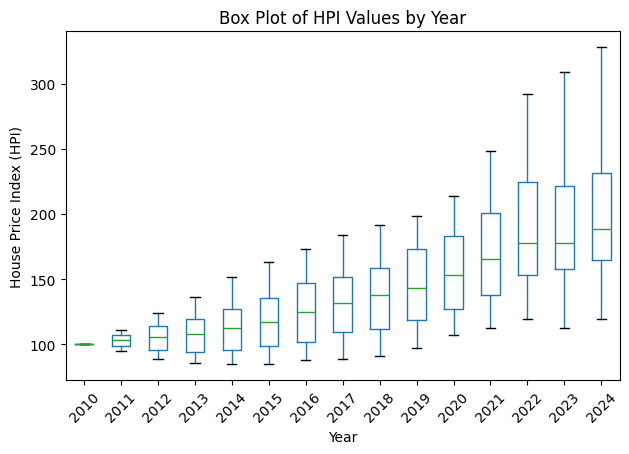

In [9]:
plot_hpi_boxplots_by_year(hpi_winsorized)

In [10]:
def print_cluster_groups(df_clusters):
    """
    Groups countries by their cluster and prints each group with country name and continent.

    Parameters:
    - df_clusters: DataFrame containing 'Country', 'cluster', and 'Continent' columns
    """

    # Ensure required columns exist
    required_cols = {'Country', 'cluster', 'Continent'}
    if not required_cols.issubset(df_clusters.columns):
        print("Missing required columns in the DataFrame.")
        return

    # Group countries by cluster
    grouped = df_clusters.groupby('cluster')

    # Print each cluster group
    for cluster_id, group in grouped:
        print(f"\n🌍 Cluster {cluster_id} ({len(group)} countries):")
        for _, row in group.iterrows():
            country = row['Country']
            continent = row['Continent']
            print(f" - {country} ({continent})")

In [11]:
print_cluster_groups(clusters_df)


🌍 Cluster 0 (8 countries):
 - Chile (America)
 - Colombia (America)
 - Hungary (Europe)
 - India (Asia)
 - Japan (Asia)
 - Paraguay (America)
 - Russia (Europe)
 - South Korea (Asia)

🌍 Cluster 1 (17 countries):
 - Austria (Europe)
 - Belgium (Europe)
 - Bulgaria (Europe)
 - Croatia (Europe)
 - Cyprus (Asia)
 - Estonia (Europe)
 - Finland (Europe)
 - Greece (Europe)
 - Ireland (Europe)
 - Latvia (Europe)
 - Lithuania (Europe)
 - Luxembourg (Europe)
 - Malta (Europe)
 - New Zealand (Oceania)
 - Portugal (Europe)
 - Slovakia (Europe)
 - Slovenia (Europe)

🌍 Cluster 2 (28 countries):
 - Australia (Oceania)
 - Brazil (America)
 - Canada (America)
 - Czech Republic (Europe)
 - Denmark (Europe)
 - France (Europe)
 - Germany (Europe)
 - Iceland (Europe)
 - Israel (Asia)
 - Italy (Europe)
 - Malaysia (Asia)
 - Mexico (America)
 - Netherlands (Europe)
 - Norway (Europe)
 - Peru (America)
 - Philippines (Asia)
 - Poland (Europe)
 - Romania (Europe)
 - Serbia (Europe)
 - Singapore (Asia)
 - Sout

### Leverage The Law of Large Numbers
* Run the sampling process for each cluster, exclude one country of that cluster to compare

In [12]:
import random

In [13]:
def estimate_hpi_by_cluster_sampling(df_hpi, df_clusters, cluster_id,
                                     cluster_column='cluster', country_column='Country',
                                     year_column='Year', sample_size=30, n_samples=1000,
                                     plot=True, seed=None):
    """
    Estimates synthetic HPI values for a randomly excluded country from a selected cluster.

    Parameters:
    - df_hpi: DataFrame with HPI values (columns = countries, rows = years, plus 'Year' column)
    - df_clusters: DataFrame with country names and cluster assignments
    - cluster_id: Cluster number to use for sampling
    - cluster_column: Column name in df_clusters with cluster labels
    - country_column: Column name in df_clusters with country names
    - year_column: Column name in df_hpi with year values
    - sample_size: Size of each sample (default: 30)
    - n_samples: Number of samples to generate (default: 1000)
    - plot: Whether to show histograms for each year (default: True)
    - seed: Optional random seed for reproducibility

    Returns:
    - synthetic_hpi: dict with estimated HPI values per year
    - excluded_country: name of the country left out
    - actual_values: dict with real HPI values of the excluded country
    """

    if seed is not None:
        random.seed(seed)
        np.random.seed(seed)

    # Step 1: Get countries in the selected cluster that are present in the HPI DataFrame
    all_cluster_countries = df_clusters[df_clusters[cluster_column] == cluster_id][country_column].tolist()
    cluster_countries = [c for c in all_cluster_countries if c in df_hpi.columns]
    
    if len(cluster_countries) < 2:
        raise ValueError("Cluster must contain at least two countries present in HPI data to perform exclusion and sampling.")
    
    # Step 2: Randomly exclude one country from those present in HPI
    excluded_country = random.choice(cluster_countries)
    sampling_countries = [c for c in cluster_countries if c != excluded_country]

    print(f"🔍 Cluster {cluster_id} selected. Excluding country: {excluded_country}")
    print(f"📊 Sampling from countries: {sampling_countries}")

    # Step 3: Prepare output containers
    synthetic_hpi = {}
    actual_values = {}

    # Step 4: Iterate over each year
    for _, row in df_hpi.iterrows():
        year = row[year_column]

        # Get HPI values for sampling countries
        values = row[sampling_countries].dropna().values

        # Get actual value of excluded country
        actual_value = row.get(excluded_country, np.nan)
        actual_values[year] = actual_value

        if len(values) == 0:
            print(f"⚠️ No HPI data available for cluster peers in year {year}")
            synthetic_hpi[year] = np.nan
            continue

        # Print available HPI values for sampling
        print(f"\n📅 Year {year} - Available HPI values for sampling:")
        print(values)

        # Generate sampling distribution
        sample_means = []
        cumulative_means = []
        for i in range(n_samples):
            sample = np.random.choice(values, size=sample_size, replace=True)
            mean = np.mean(sample)
            sample_means.append(mean)
            cumulative_means.append(np.mean(sample_means))  # track convergence

        # Compute 95% confidence interval
        lower_bound = np.percentile(sample_means, 2.5)
        upper_bound = np.percentile(sample_means, 97.5)

        # Plot side-by-side: histogram + convergence
        fig, axes = plt.subplots(1, 2, figsize=(14, 4))

        # Histogram with confidence interval
        axes[0].hist(sample_means, bins=30, color='lightgreen', edgecolor='black')
        axes[0].axvline(actual_value, color='red', linestyle='--', label=f"Actual: {excluded_country}")
        axes[0].axvline(lower_bound, color='blue', linestyle=':', label='95% CI Lower')
        axes[0].axvline(upper_bound, color='blue', linestyle=':', label='95% CI Upper')
        axes[0].set_title(f"HPI Sampling Distribution - Year {year}")
        axes[0].set_xlabel("Sample Mean HPI")
        axes[0].set_ylabel("Frequency")
        axes[0].legend()
        axes[0].grid(True)

        # Convergence plot
        axes[1].plot(cumulative_means, color='purple')
        axes[1].axhline(np.mean(sample_means), color='gray', linestyle='--', label='Final Mean')
        axes[1].set_title("Mean Convergence Over Iterations")
        axes[1].set_xlabel("Iteration")
        axes[1].set_ylabel("Cumulative Mean")
        axes[1].legend()
        axes[1].grid(True)

        plt.tight_layout()
        plt.show()
        # Store synthetic HPI value
        synthetic_hpi[year] = np.mean(sample_means)

    return synthetic_hpi, excluded_country, actual_values

### Experiment with seed 32

🔍 Cluster 0 selected. Excluding country: Chile
📊 Sampling from countries: ['Colombia', 'Hungary', 'India', 'Japan', 'Russia', 'South Korea']

📅 Year 2010.0 - Available HPI values for sampling:
[100. 100. 100. 100. 100. 100.]


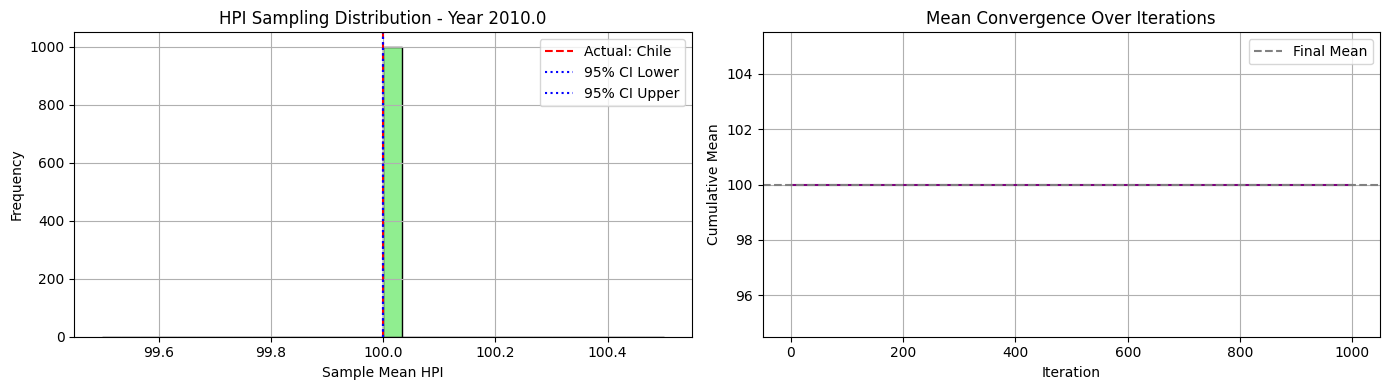


📅 Year 2011.0 - Available HPI values for sampling:
[107.89  96.56 110.52 100.07  94.49 105.23]


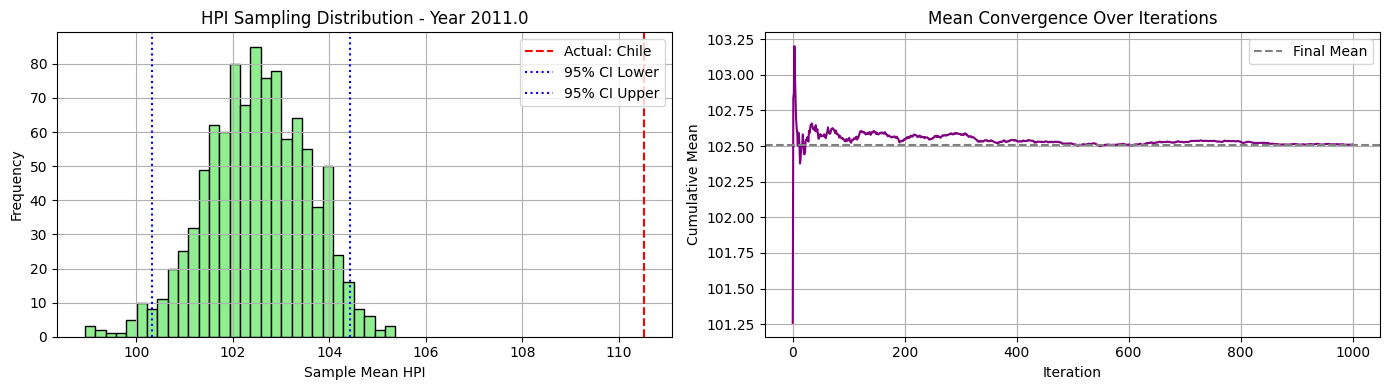


📅 Year 2012.0 - Available HPI values for sampling:
[118.79  92.98 124.02  99.19  91.1  108.25]


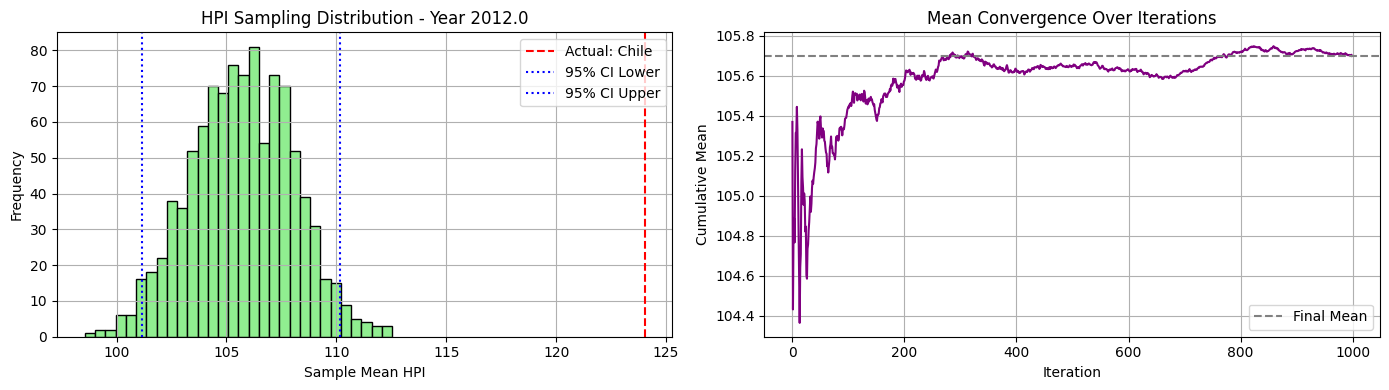


📅 Year 2013.0 - Available HPI values for sampling:
[130.06  90.58 136.52 100.81  94.32 107.8 ]


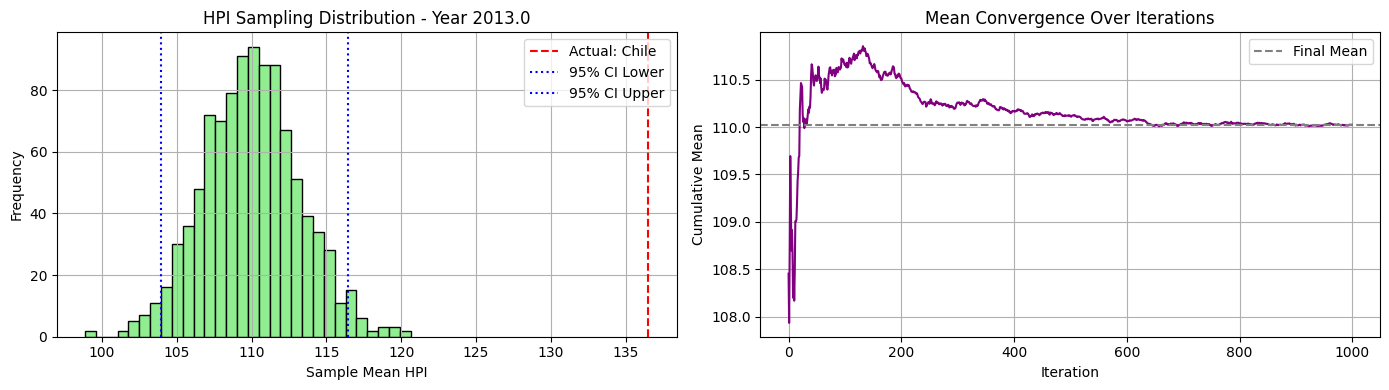


📅 Year 2014.0 - Available HPI values for sampling:
[140.75  94.37 151.67 102.38  95.84 109.43]


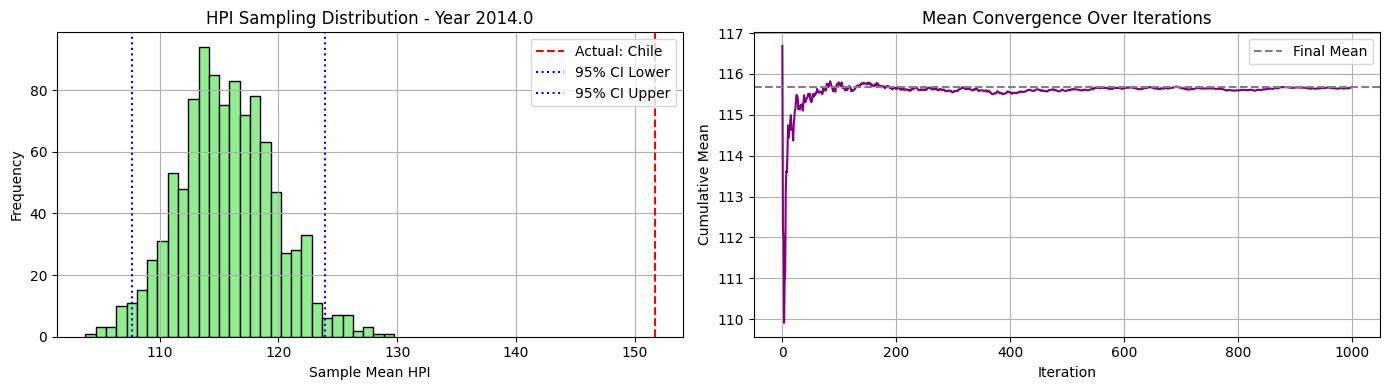


📅 Year 2015.0 - Available HPI values for sampling:
[152.93 106.75 162.89 104.86  97.   113.08]


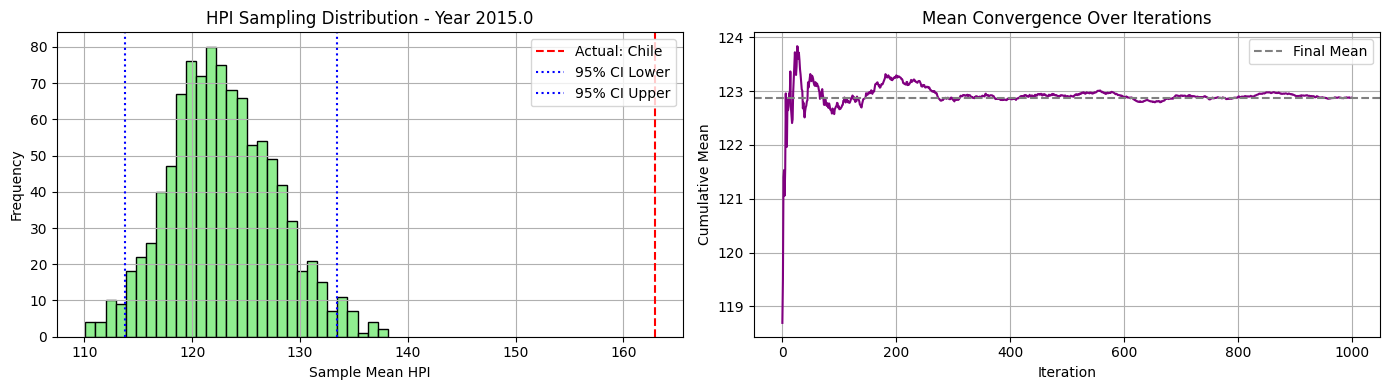


📅 Year 2016.0 - Available HPI values for sampling:
[167.48 121.03 172.75 107.18  91.86 116.09]


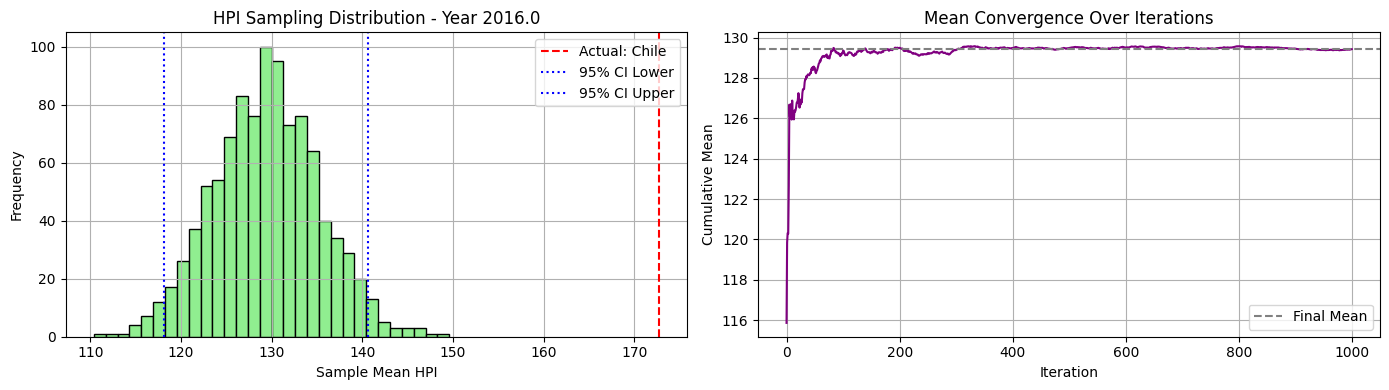


📅 Year 2017.0 - Available HPI values for sampling:
[178.56 135.84 183.99 109.91  88.54 117.6 ]


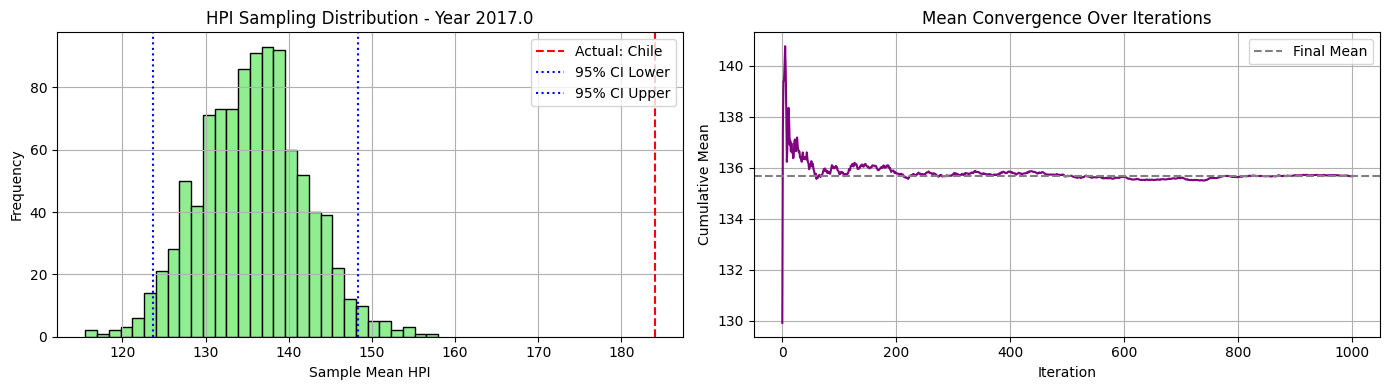


📅 Year 2018.0 - Available HPI values for sampling:
[188.24 155.3  191.85 112.04  90.72 120.22]


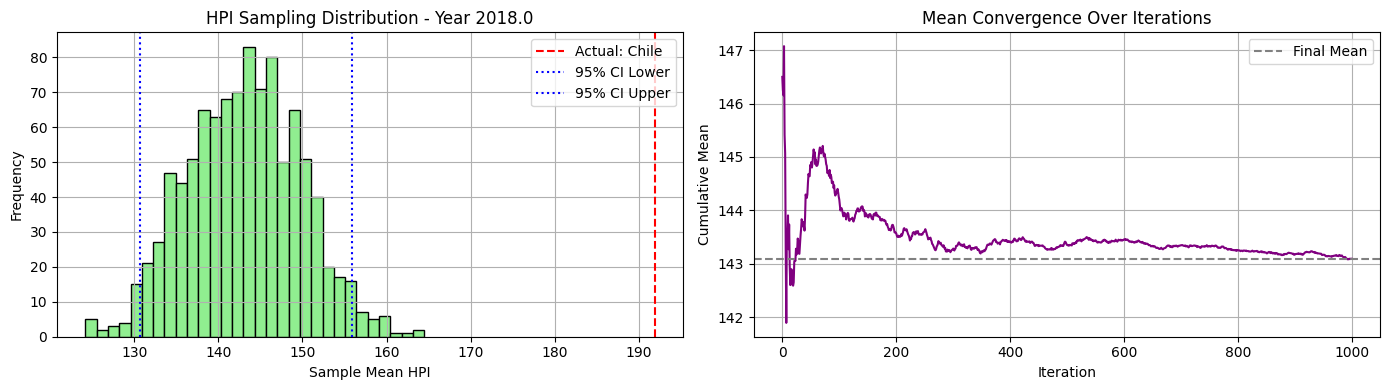


📅 Year 2019.0 - Available HPI values for sampling:
[198.37 181.64 198.37 113.84  97.25 121.93]


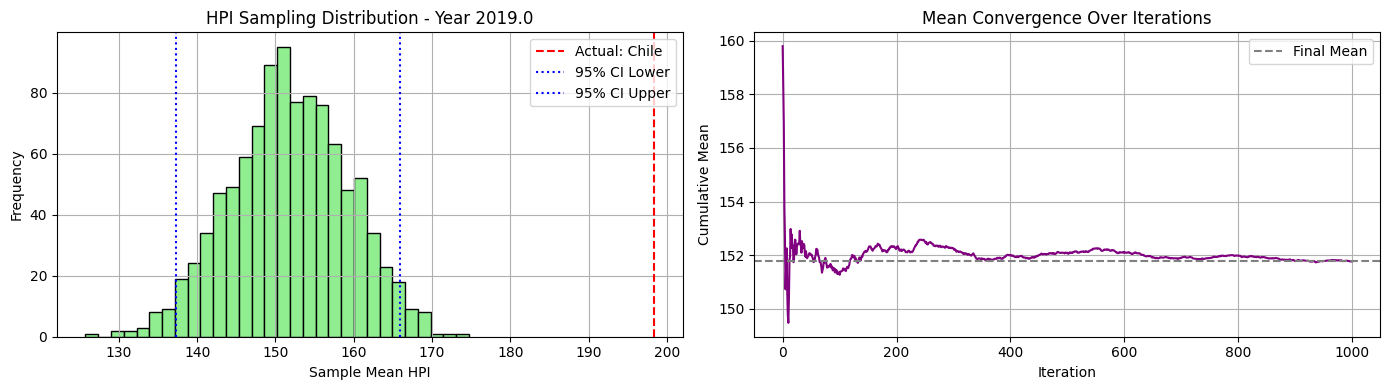


📅 Year 2020.0 - Available HPI values for sampling:
[203.12 190.63 213.74 113.93 106.71 126.56]


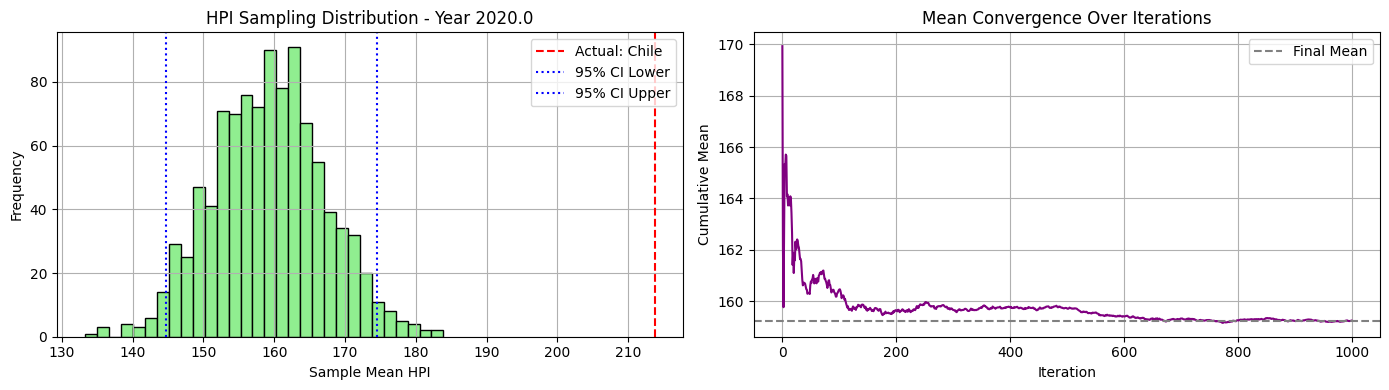


📅 Year 2021.0 - Available HPI values for sampling:
[214.9  222.1  248.26 120.7  121.41 143.73]


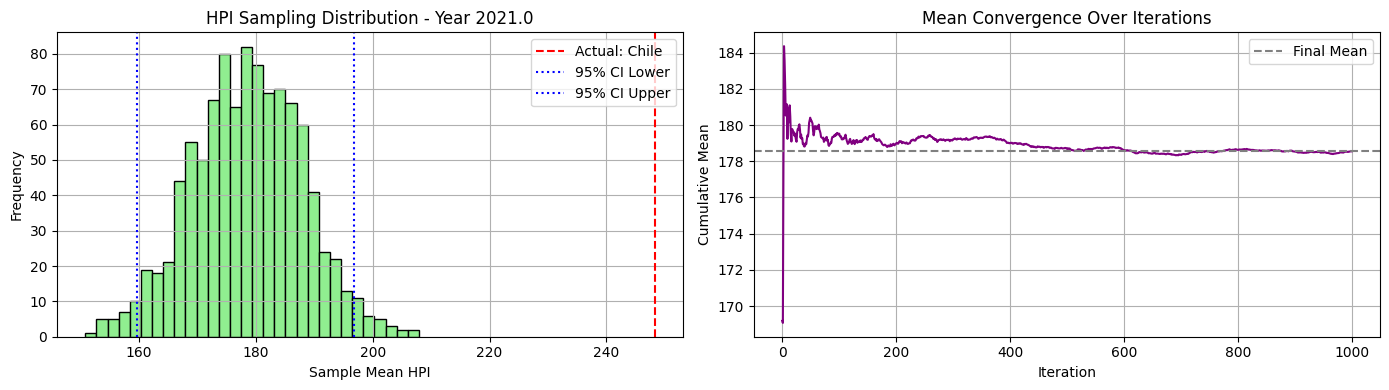


📅 Year 2022.0 - Available HPI values for sampling:
[230.   271.5  292.18 130.84 155.16 153.22]


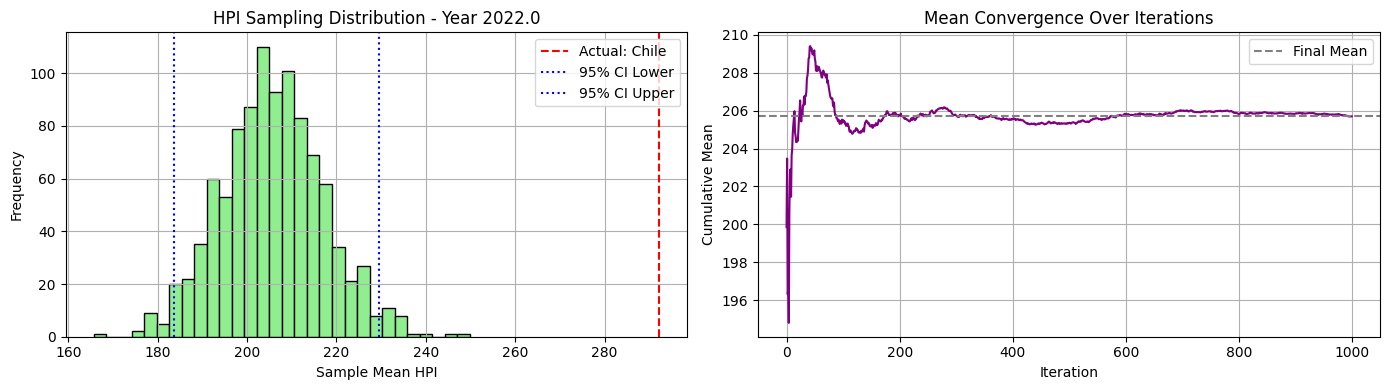


📅 Year 2023.0 - Available HPI values for sampling:
[245.75 290.98 309.37 134.8  157.88 143.99]


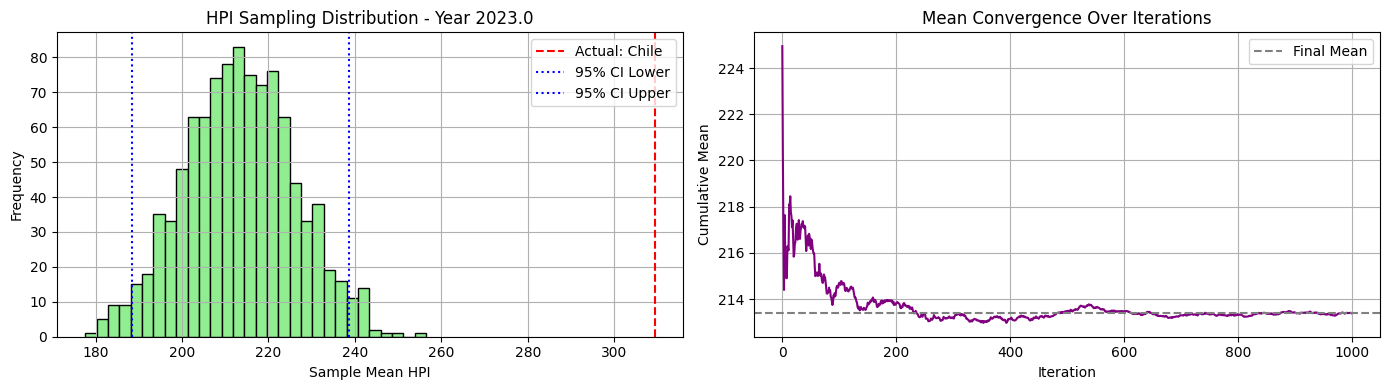


📅 Year 2024.0 - Available HPI values for sampling:
[269.02 328.1  328.24 138.61 186.66 142.46]


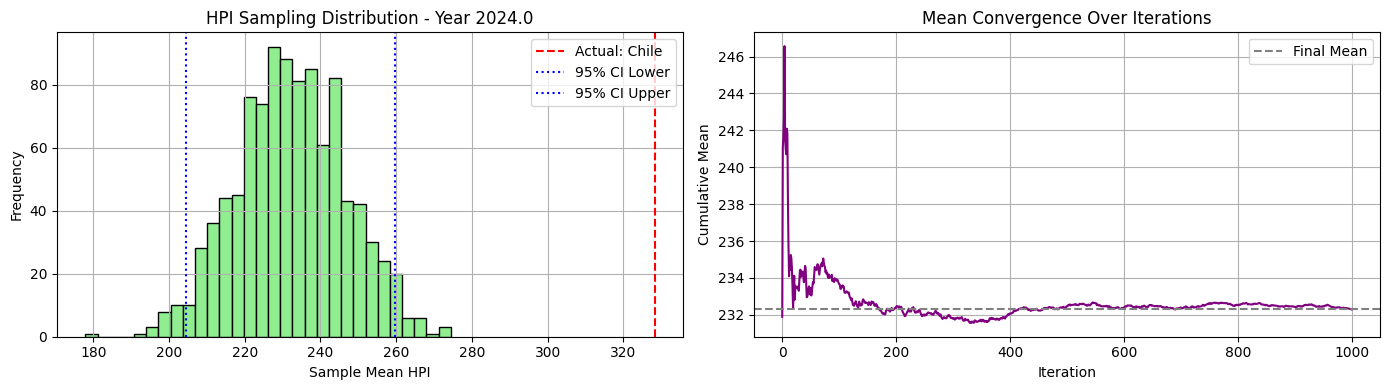

In [14]:
synthetic_00_32, excluded_00_32, actual_00_32 = estimate_hpi_by_cluster_sampling(hpi_winsorized, clusters_df, cluster_id=0, seed=32)

🔍 Cluster 1 selected. Excluding country: Bulgaria
📊 Sampling from countries: ['Austria', 'Belgium', 'Croatia', 'Cyprus', 'Estonia', 'Finland', 'Greece', 'Ireland', 'Latvia', 'Lithuania', 'Luxembourg', 'Malta', 'New Zealand', 'Portugal', 'Slovakia', 'Slovenia']

📅 Year 2010.0 - Available HPI values for sampling:
[100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.
 100. 100.]


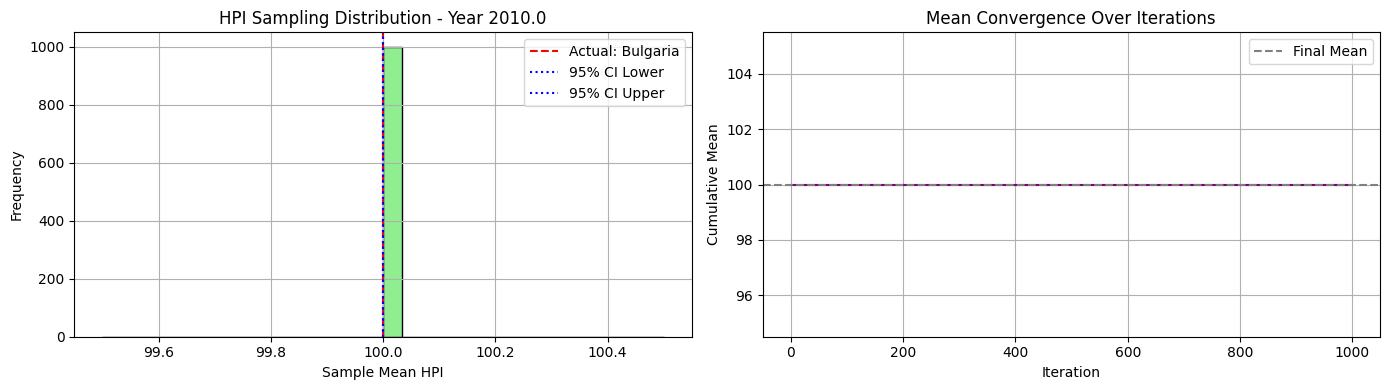


📅 Year 2011.0 - Available HPI values for sampling:
[104.22 103.58 100.16  96.68 108.47 103.17  94.53  94.49 110.42 106.6
 103.68  98.63 100.75  95.1   98.46 102.72]


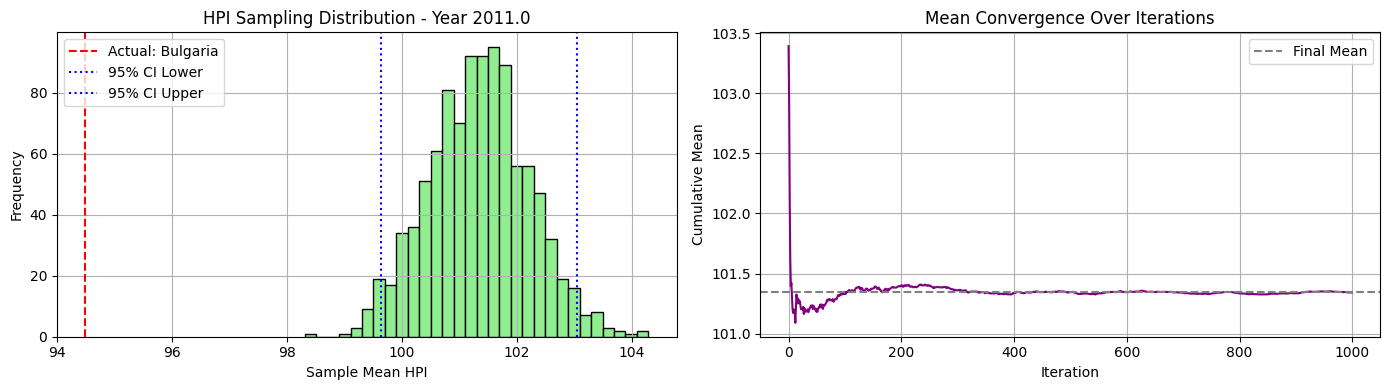


📅 Year 2012.0 - Available HPI values for sampling:
[117.13 106.02  98.62  91.54 116.34 105.64  88.37  88.37 113.71 106.36
 108.03 101.62 105.25  88.37  95.73  95.63]


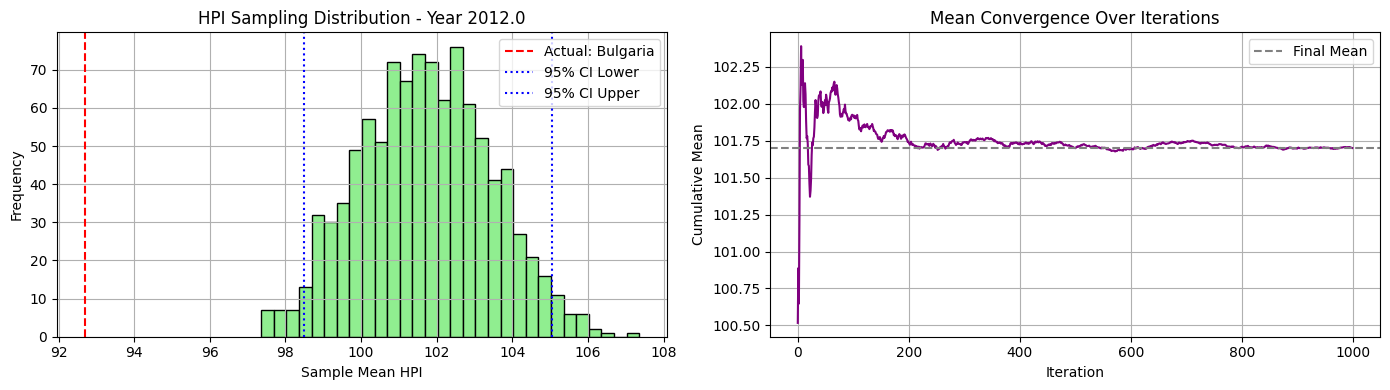


📅 Year 2013.0 - Available HPI values for sampling:
[122.59 107.59  94.7   85.58 128.77 106.87  85.58  85.58 121.5  107.65
 113.42 101.21 114.59  86.7   96.53  90.62]


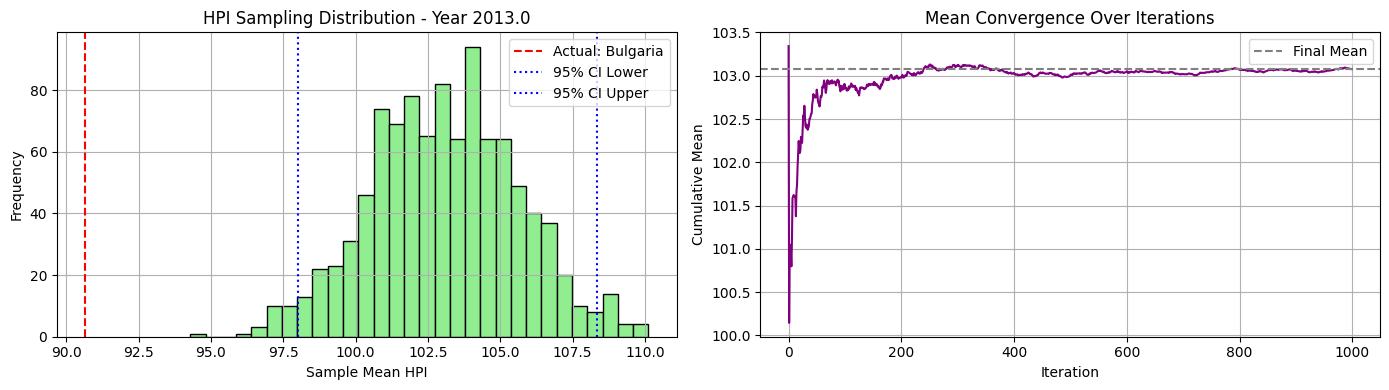


📅 Year 2014.0 - Available HPI values for sampling:
[126.79 107.22  93.19  84.64 146.41 106.5   84.64  84.66 128.78 114.57
 118.39 103.79 122.03  90.38  97.8   84.64]


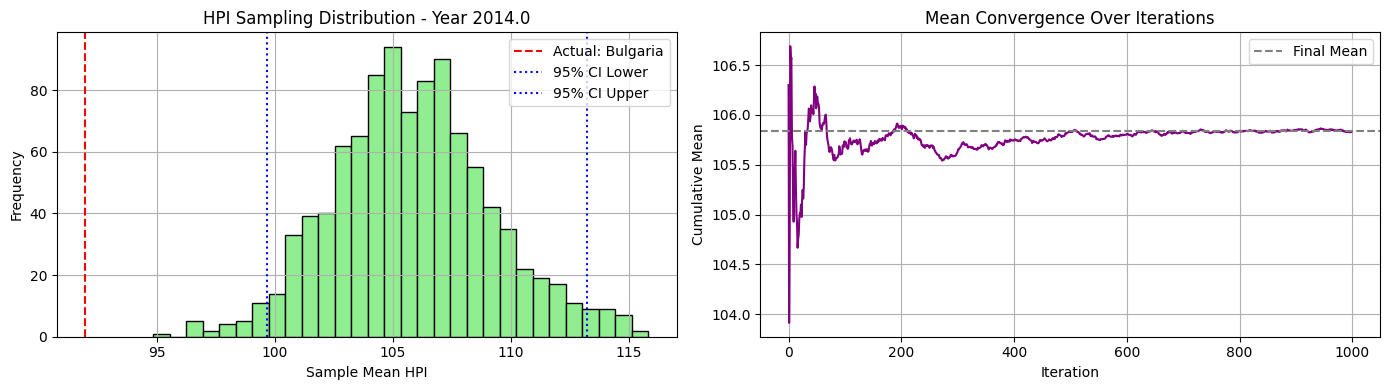


📅 Year 2015.0 - Available HPI values for sampling:
[132.06 109.17  90.54  84.67 156.46 106.5   84.67  94.36 124.46 118.76
 124.78 109.83 137.18  93.15 103.    85.32]


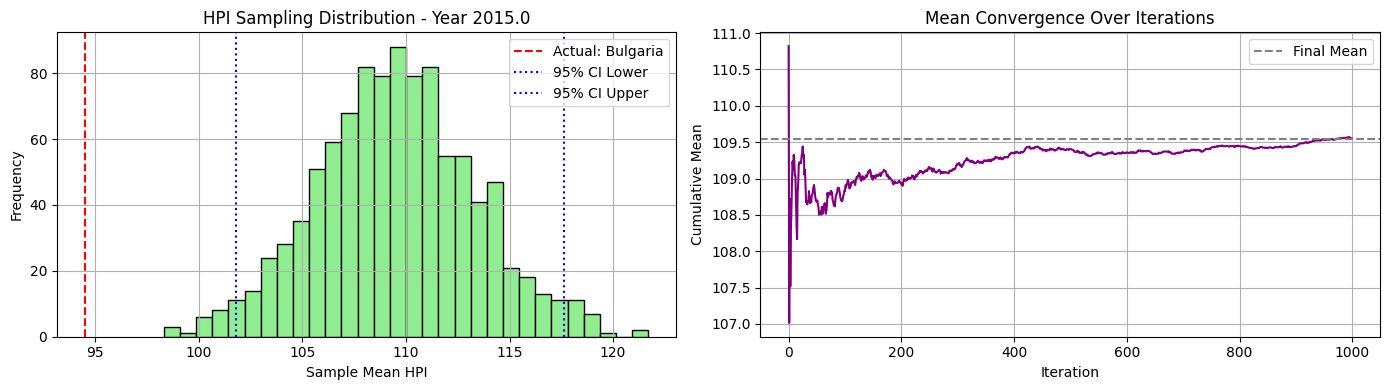


📅 Year 2016.0 - Available HPI values for sampling:
[141.76 111.72  91.33  88.1  163.86 107.86  88.1  101.42 135.02 125.16
 132.28 115.82 156.62  99.78 109.87  88.1 ]


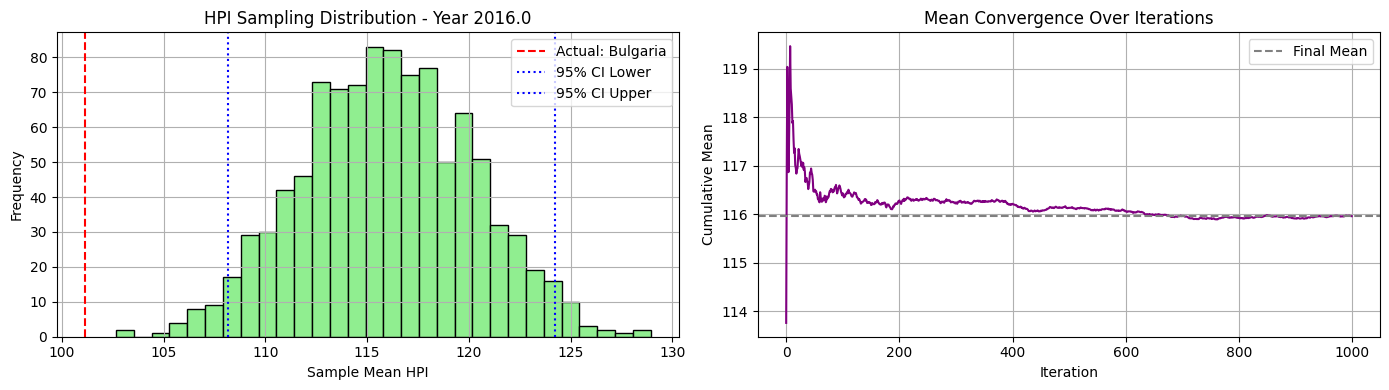


📅 Year 2017.0 - Available HPI values for sampling:
[147.08 115.66  94.84  88.54 172.91 109.02  88.54 112.44 146.87 136.34
 139.69 121.94 166.8  108.99 116.3   95.38]


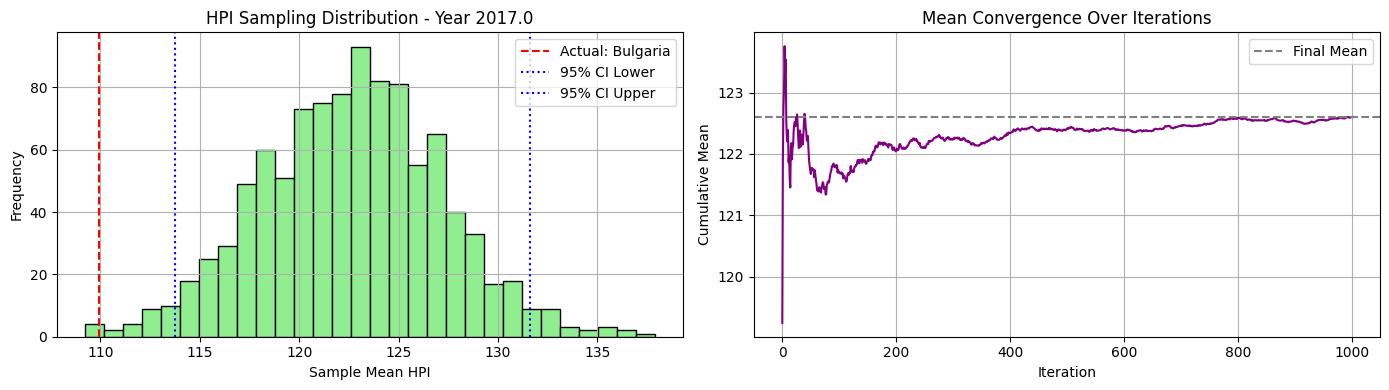


📅 Year 2018.0 - Available HPI values for sampling:
[157.24 119.16 100.59  90.72 183.13 110.06  90.72 123.96 160.92 146.29
 149.55 129.02 172.8  120.19 124.97 103.7 ]


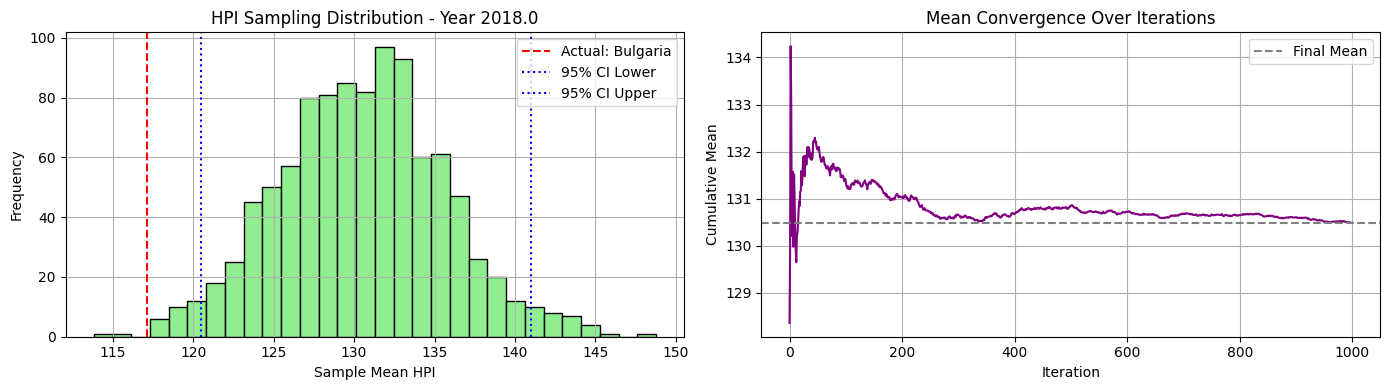


📅 Year 2019.0 - Available HPI values for sampling:
[163.43 123.62 109.64  97.25 195.98 110.52  97.25 126.85 175.33 156.3
 164.68 136.9  178.19 132.16 136.39 110.65]


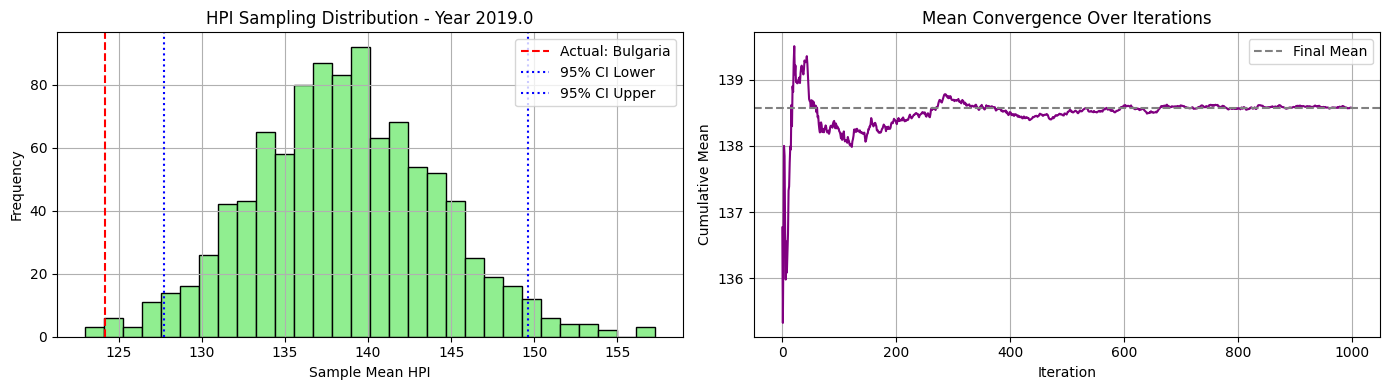


📅 Year 2020.0 - Available HPI values for sampling:
[174.92 128.92 118.06 106.71 207.78 112.49 106.71 127.24 181.42 167.66
 188.57 141.54 196.31 143.75 149.36 115.74]


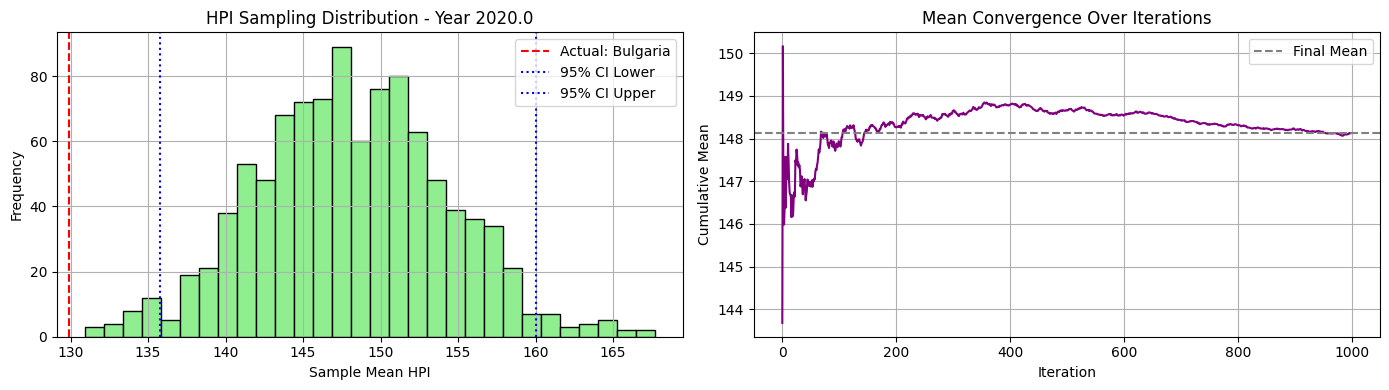


📅 Year 2021.0 - Available HPI values for sampling:
[195.48 137.52 126.64 112.34 239.04 117.62 112.34 137.77 201.18 194.58
 214.81 148.74 248.26 157.27 158.94 129.1 ]


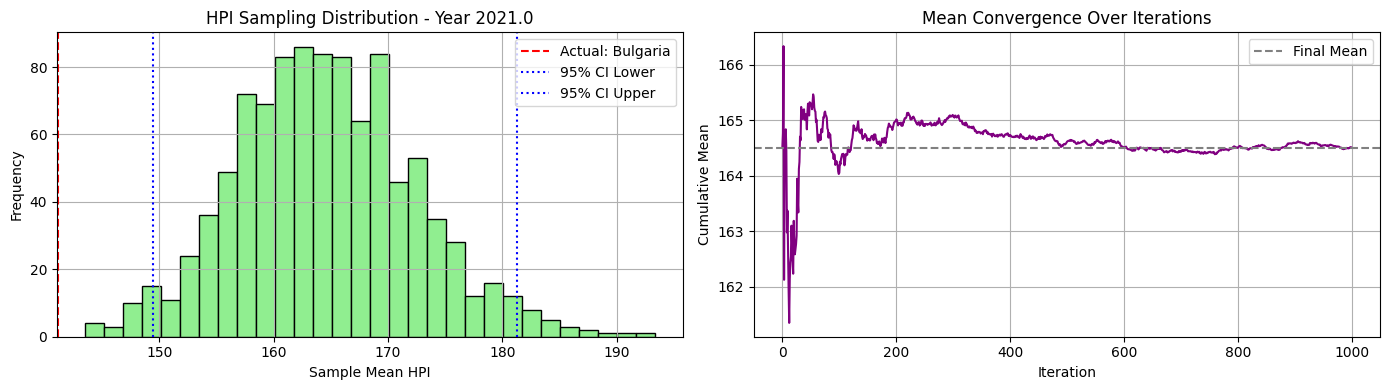


📅 Year 2022.0 - Available HPI values for sampling:
[215.62 145.12 145.44 118.98 292.18 118.98 118.98 154.73 229.01 231.64
 235.34 158.62 249.69 177.14 180.7  148.16]


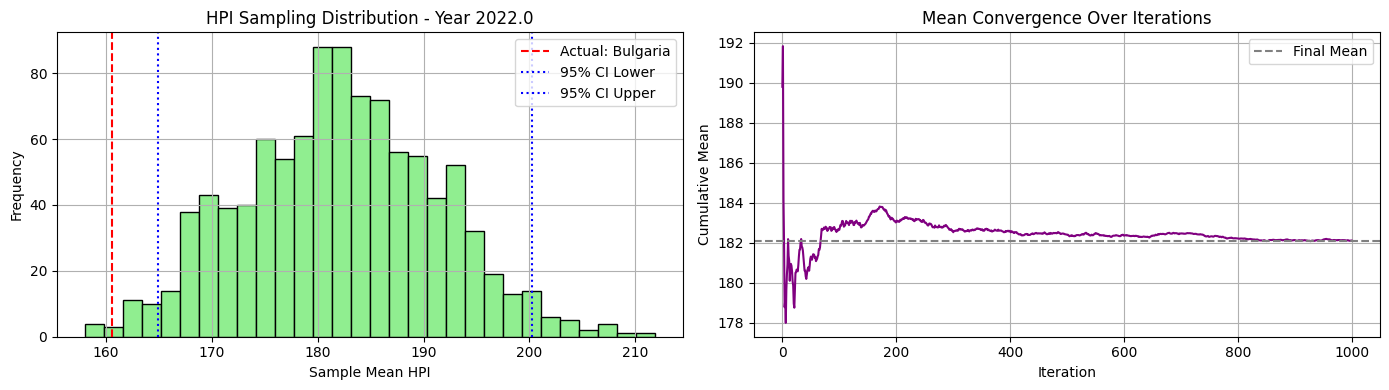


📅 Year 2023.0 - Available HPI values for sampling:
[212.08 148.52 162.82 112.27 309.37 112.27 112.27 159.48 237.56 254.38
 214.   168.5  233.54 191.66 180.36 158.88]


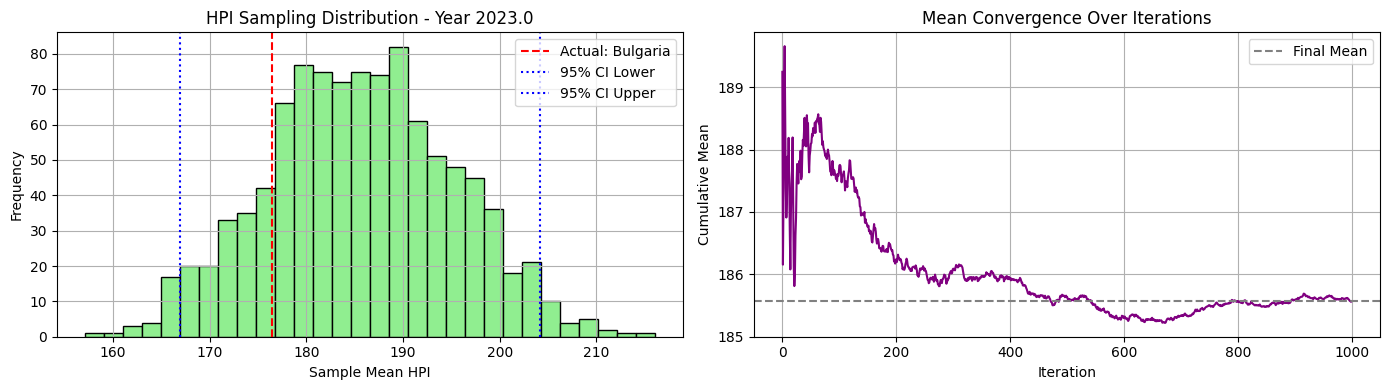


📅 Year 2024.0 - Available HPI values for sampling:
[207.62 153.31 179.7  119.1  328.24 119.1  119.1  173.07 247.54 279.12
 202.74 179.35 233.68 209.06 187.15 170.56]


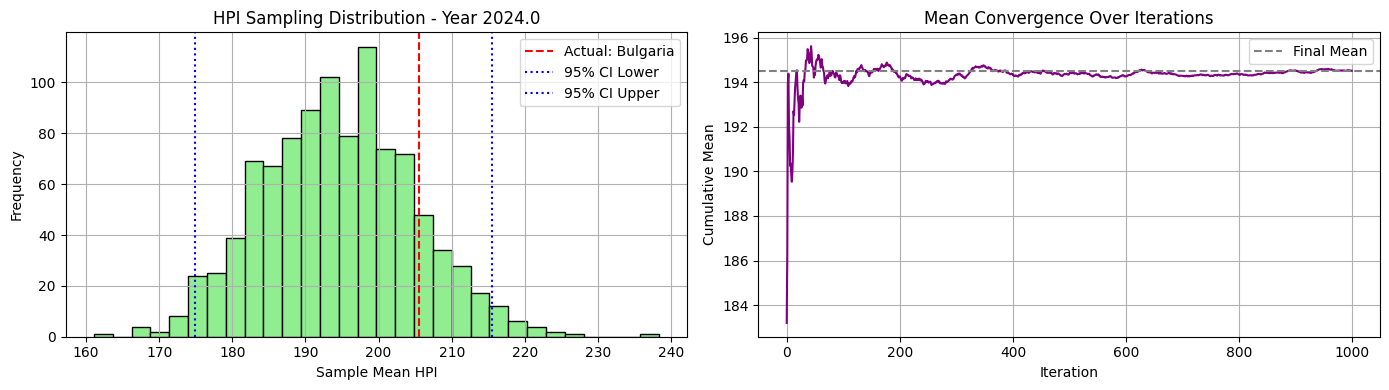

In [15]:
synthetic_01_32, excluded_01_32, actual_01_32 = estimate_hpi_by_cluster_sampling(hpi_winsorized, clusters_df, cluster_id=1, seed=32)

🔍 Cluster 2 selected. Excluding country: Canada
📊 Sampling from countries: ['Australia', 'Brazil', 'Czech Republic', 'Denmark', 'France', 'Germany', 'Iceland', 'Israel', 'Italy', 'Malaysia', 'Mexico', 'Netherlands', 'Norway', 'Peru', 'Philippines', 'Poland', 'Romania', 'Serbia', 'Singapore', 'South Africa', 'Spain', 'Sweden', 'Switzerland', 'Thailand', 'Turkey', 'United Kingdom', 'USA']

📅 Year 2010.0 - Available HPI values for sampling:
[100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.
 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.]


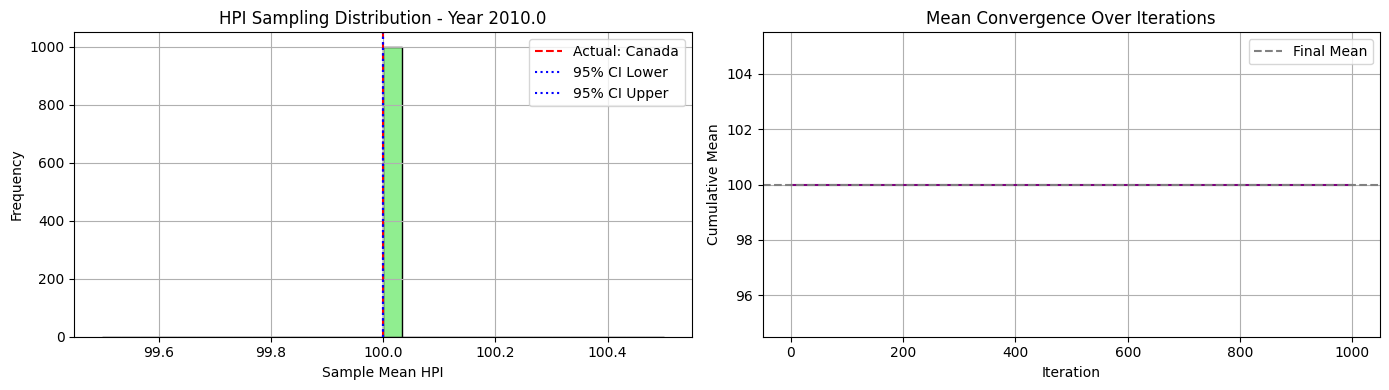


📅 Year 2011.0 - Available HPI values for sampling:
[ 97.84 110.52 100.02  98.29 105.69 102.42 105.5  110.52 101.36 109.83
 105.8   98.02 108.01 110.52 105.57 100.08  94.49  97.62 109.46 103.59
  94.49 102.58 107.51 104.26 108.8   98.54  97.24]


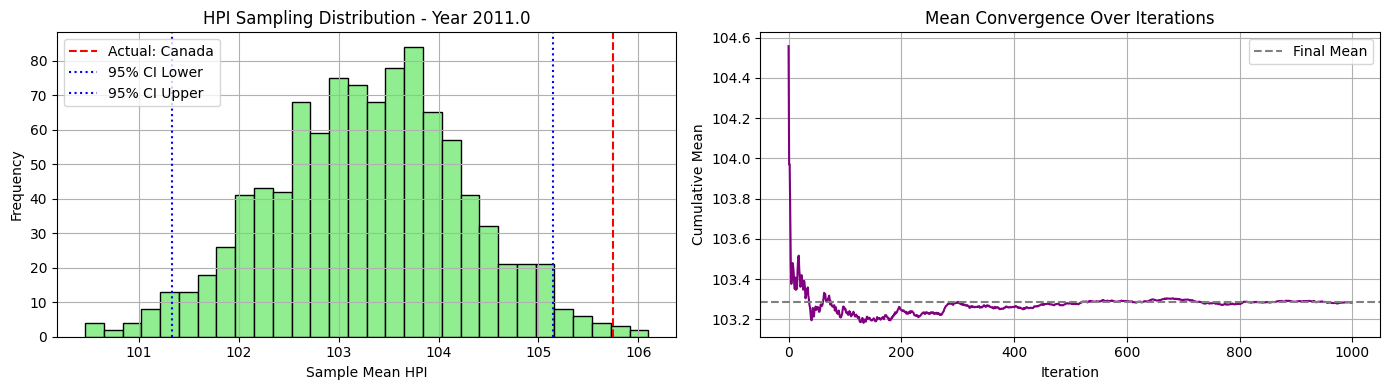


📅 Year 2012.0 - Available HPI values for sampling:
[ 97.53 124.02  98.56  95.67 105.11 105.48 112.38 114.1   98.77 124.02
 109.17  91.44 115.34 124.02 114.94  96.58  88.37  95.68 112.02 108.41
  88.37 103.86 113.72 107.63 120.68  98.92 101.82]


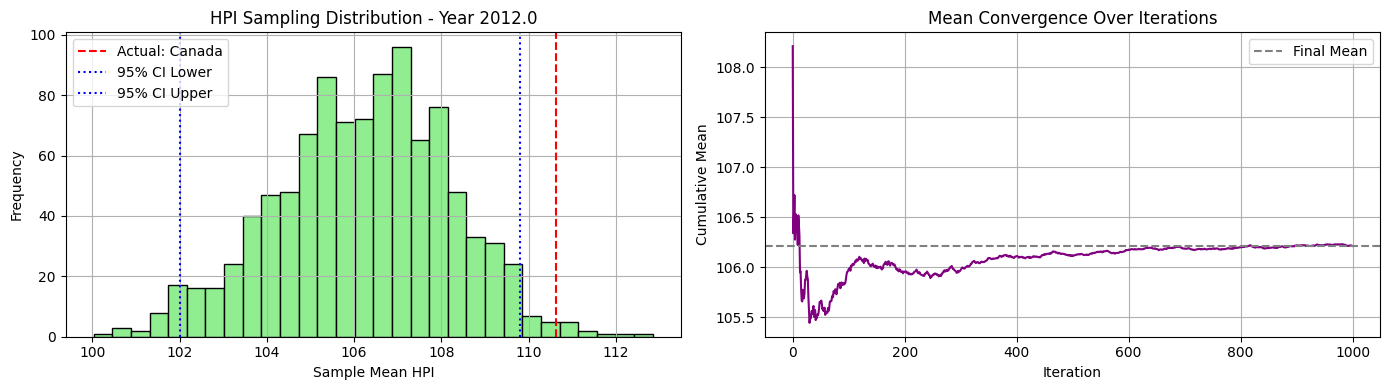


📅 Year 2013.0 - Available HPI values for sampling:
[103.99 136.52  98.58  99.37 103.13 108.68 119.18 124.45  92.38 136.52
 114.75  85.95 119.98 136.52 127.86  92.35  85.58  90.62 115.56 115.41
  85.58 109.22 118.3  115.99 134.46 101.46 111.83]


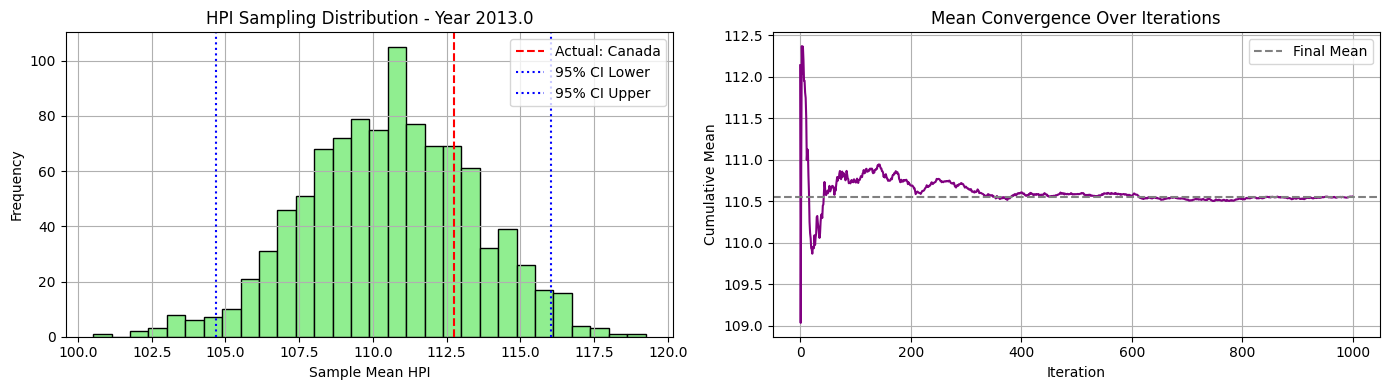


📅 Year 2014.0 - Available HPI values for sampling:
[113.41 151.67 101.   103.12 101.58 111.85 128.94 132.36  88.02 151.67
 119.64  86.66 123.24 151.67 142.76  93.27  84.64  95.77 112.25 123.99
  84.64 119.52 121.46 127.07 151.25 109.6  118.88]


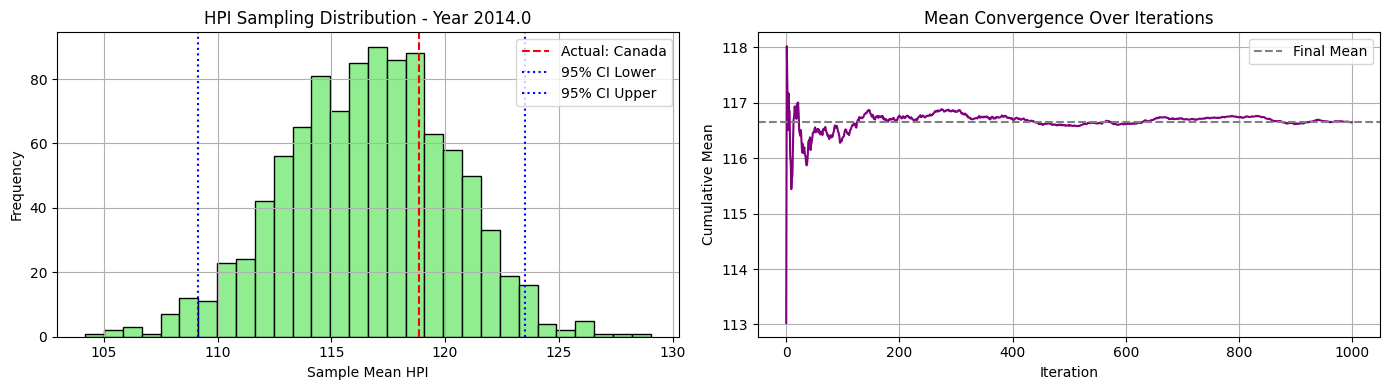


📅 Year 2015.0 - Available HPI values for sampling:
[123.65 156.16 105.01 110.29 100.22 117.12 139.74 140.12  84.67 162.89
 129.39  89.69 130.76 162.89 157.04  94.69  84.67  99.5  107.92 131.8
  84.67 135.2  124.08 136.   162.89 116.12 125.18]


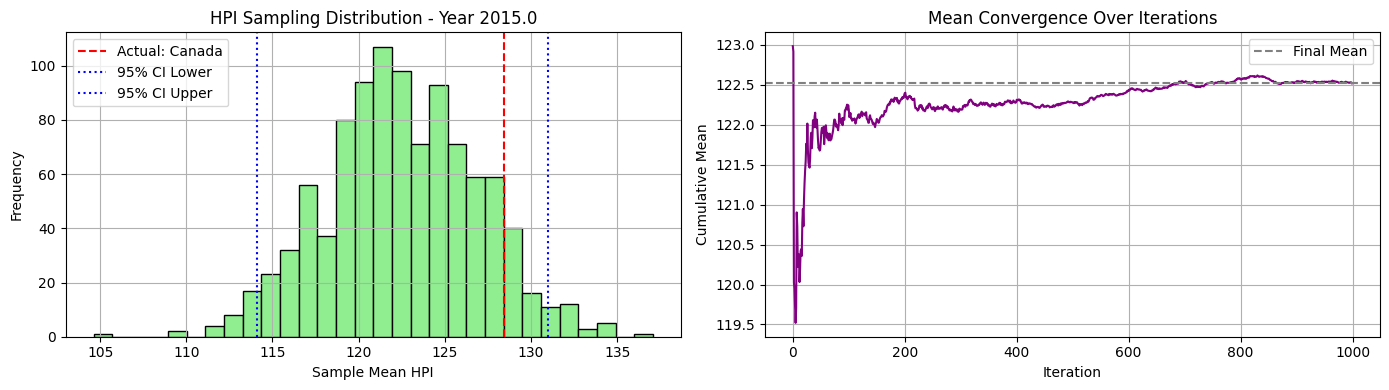


📅 Year 2016.0 - Available HPI values for sampling:
[130.44 151.94 112.52 115.5  101.25 125.93 154.59 150.56  88.1  172.75
 138.82  94.43 139.95 164.18 172.75  96.44  88.91 110.62 104.55 138.22
  88.1  146.34 124.32 142.4  172.75 124.27 131.88]


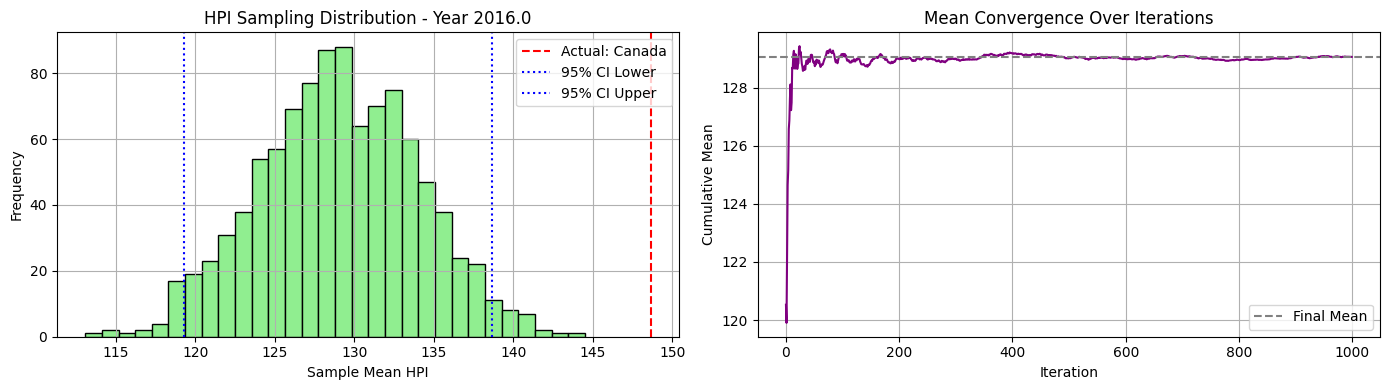


📅 Year 2017.0 - Available HPI values for sampling:
[141.34 149.02 125.7  120.63 104.46 133.62 183.99 156.44  88.54 183.99
 149.69 102.06 146.91 168.   178.82 100.16  93.93 115.3  103.4  143.94
  88.54 156.06 125.42 146.48 183.99 129.93 139.61]


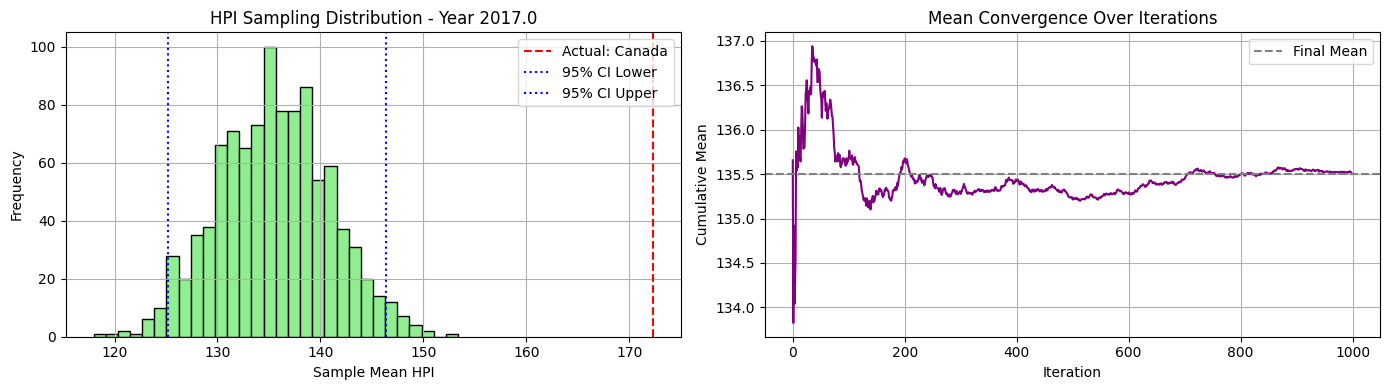


📅 Year 2018.0 - Available HPI values for sampling:
[139.3  149.81 136.52 126.31 107.52 142.52 191.85 155.14  90.72 191.85
 162.97 111.57 149.04 168.42 183.82 106.75  99.37 123.06 111.46 148.96
  90.72 154.6  129.16 153.9  191.85 134.04 147.35]


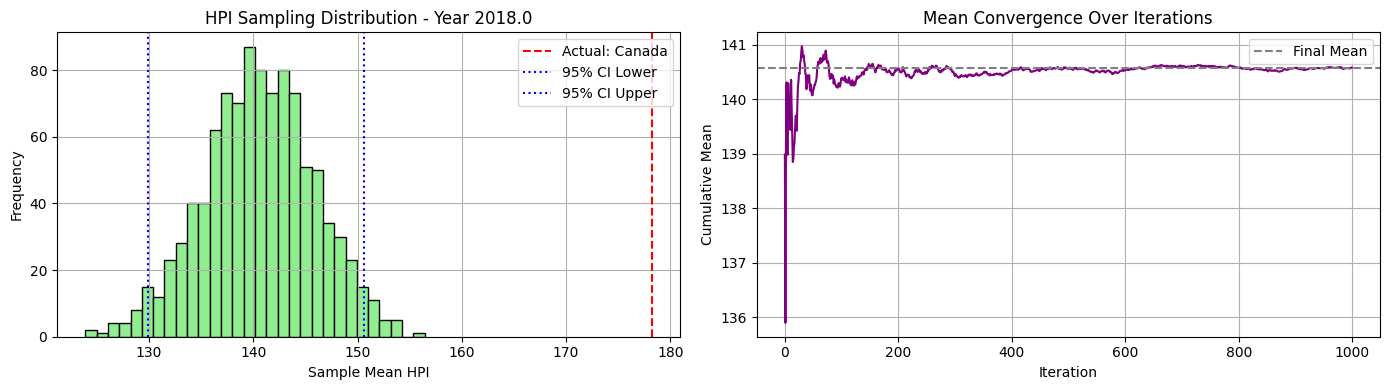


📅 Year 2019.0 - Available HPI values for sampling:
[133.64 155.06 149.02 129.62 111.1  150.75 198.37 158.06  97.25 196.06
 176.92 119.62 152.73 172.03 195.26 116.01 102.72 135.77 113.98 152.69
  97.25 158.44 133.99 155.1  198.37 135.37 153.14]


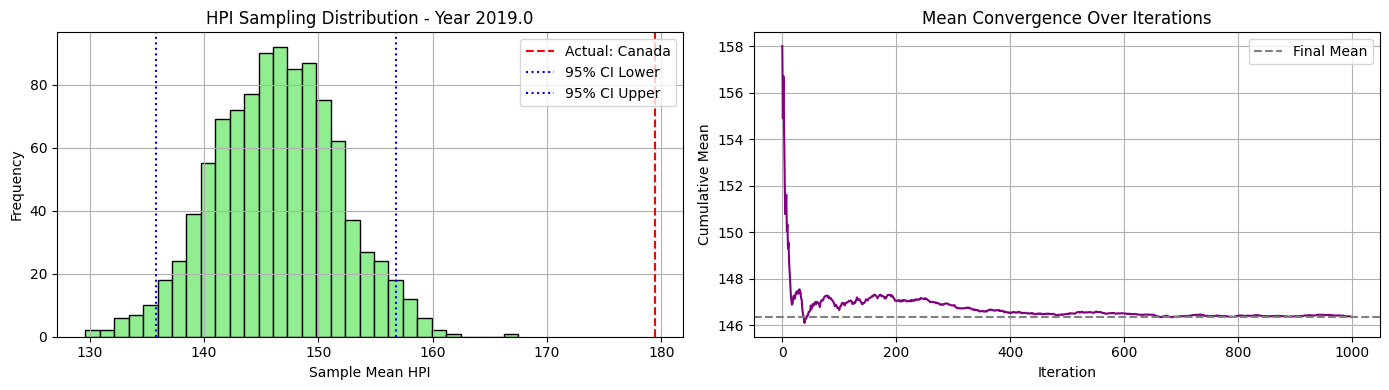


📅 Year 2020.0 - Available HPI values for sampling:
[140.85 166.92 161.56 136.24 116.89 162.48 213.74 162.9  106.71 198.37
 187.18 129.21 159.24 173.67 213.74 128.18 107.53 149.28 115.8  156.31
 106.71 165.09 137.31 160.6  213.74 139.24 163.52]


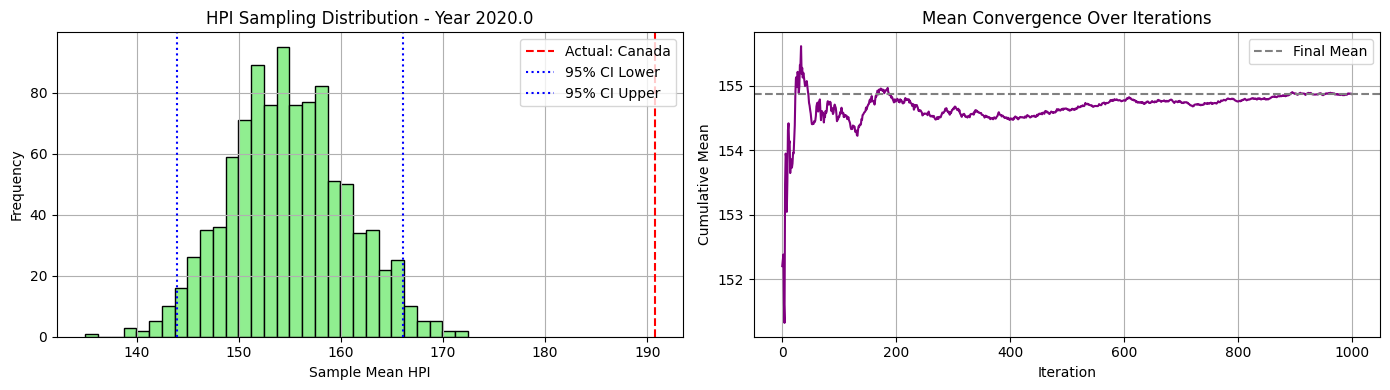


📅 Year 2021.0 - Available HPI values for sampling:
[165.39 180.02 193.46 152.2  124.38 181.28 248.26 176.65 112.34 200.69
 201.94 147.93 175.91 173.6  211.74 139.92 112.34 166.04 125.04 166.82
 112.34 181.79 145.16 164.23 248.26 150.58 188.56]


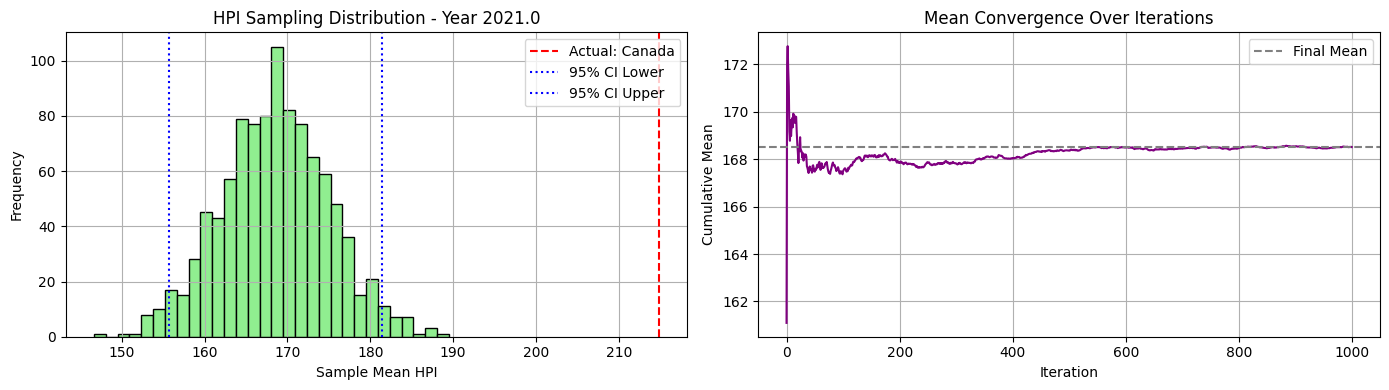


📅 Year 2022.0 - Available HPI values for sampling:
[179.02 185.16 226.15 151.49 132.1  190.42 292.18 207.16 118.98 207.75
 219.93 167.57 185.13 172.65 223.73 156.43 120.29 191.49 137.74 174.03
 118.98 188.27 154.42 169.16 292.18 164.55 213.  ]


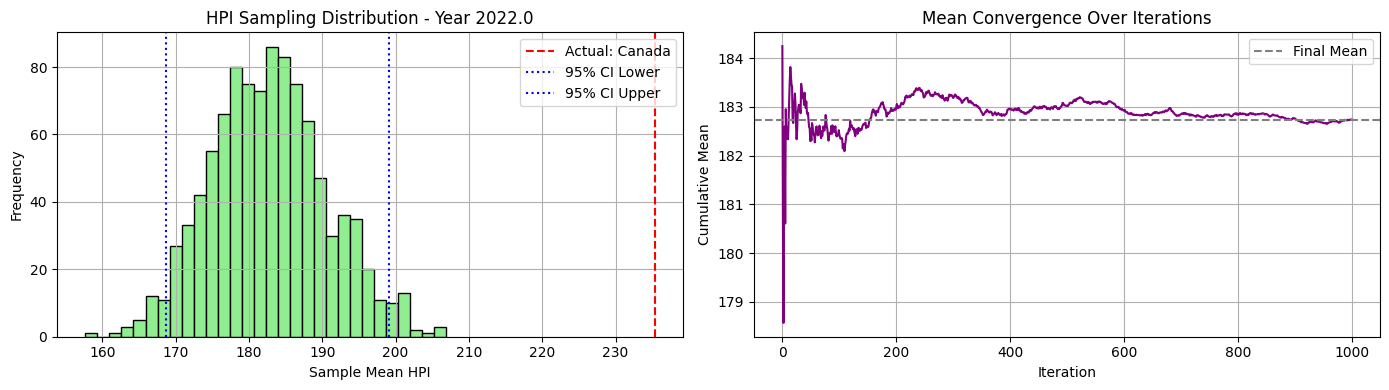


📅 Year 2023.0 - Available HPI values for sampling:
[178.65 191.27 222.4  151.24 131.52 174.25 309.37 214.23 112.27 216.19
 243.89 164.36 184.12 175.16 248.04 170.23 124.06 209.99 148.01 176.62
 112.27 178.36 157.81 174.79 309.37 165.   221.72]


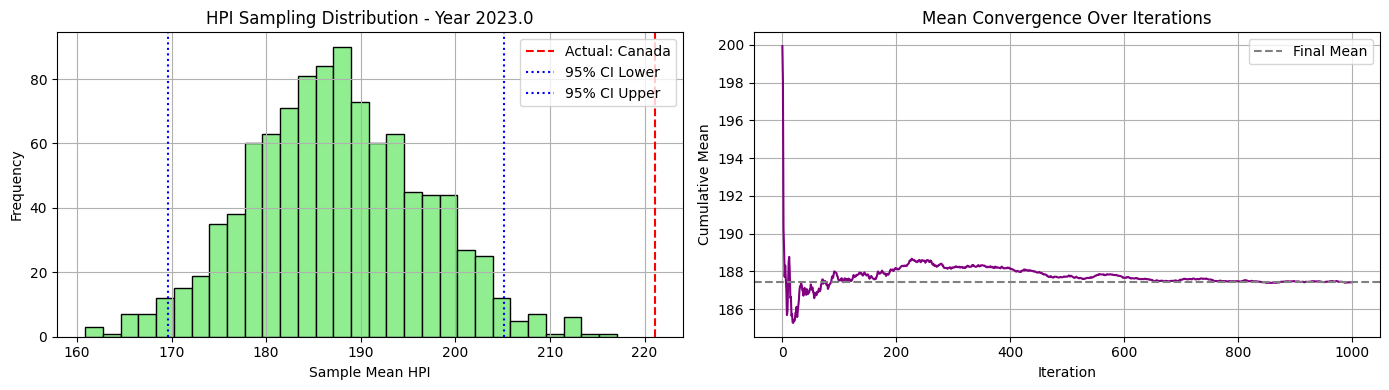


📅 Year 2024.0 - Available HPI values for sampling:
[192.53 203.78 233.42 156.73 126.68 171.5  328.24 224.54 119.1  225.06
 266.38 177.7  189.05 175.38 256.03 195.72 130.34 220.7  155.12 178.1
 119.1  178.49 160.56 178.06 328.24 166.38 231.23]


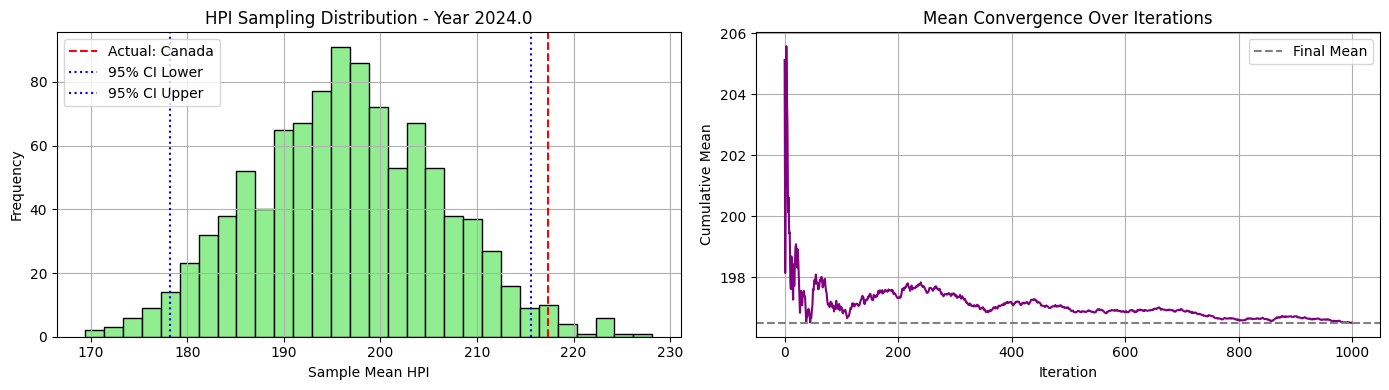

In [16]:
synthetic_02_32, excluded_02_32, actual_02_32 = estimate_hpi_by_cluster_sampling(hpi_winsorized, clusters_df, cluster_id=2, seed=32)

### Experiment with seed 43

🔍 Cluster 0 selected. Excluding country: Chile
📊 Sampling from countries: ['Colombia', 'Hungary', 'India', 'Japan', 'Russia', 'South Korea']

📅 Year 2010.0 - Available HPI values for sampling:
[100. 100. 100. 100. 100. 100.]


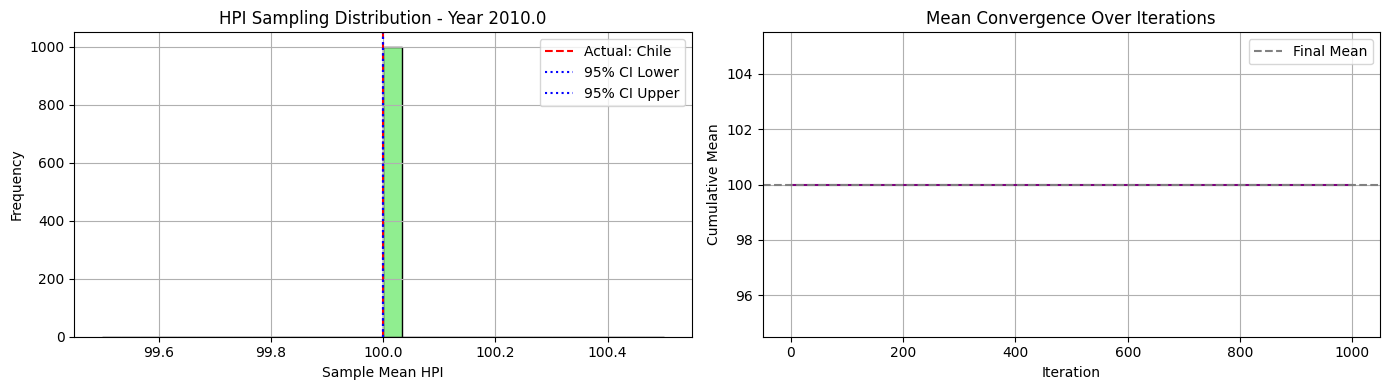


📅 Year 2011.0 - Available HPI values for sampling:
[107.89  96.56 110.52 100.07  94.49 105.23]


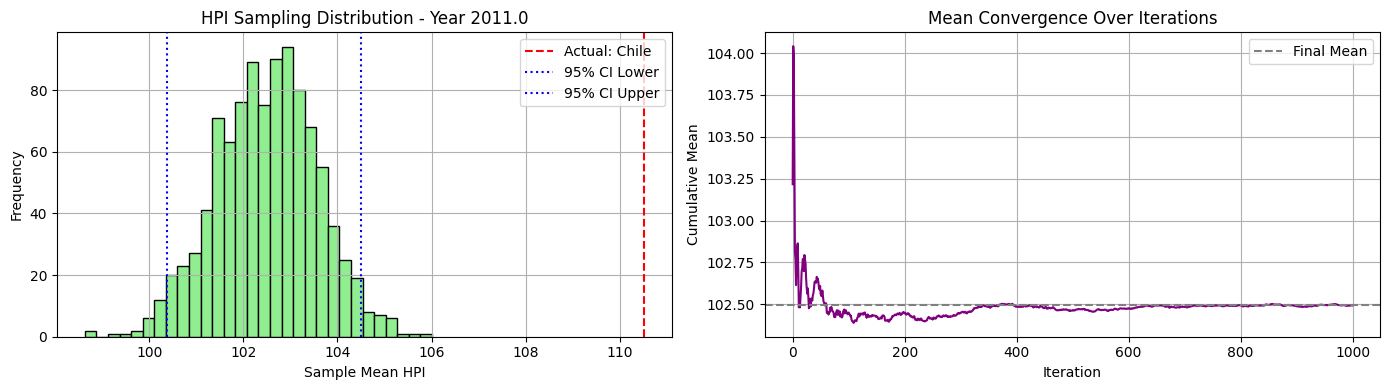


📅 Year 2012.0 - Available HPI values for sampling:
[118.79  92.98 124.02  99.19  91.1  108.25]


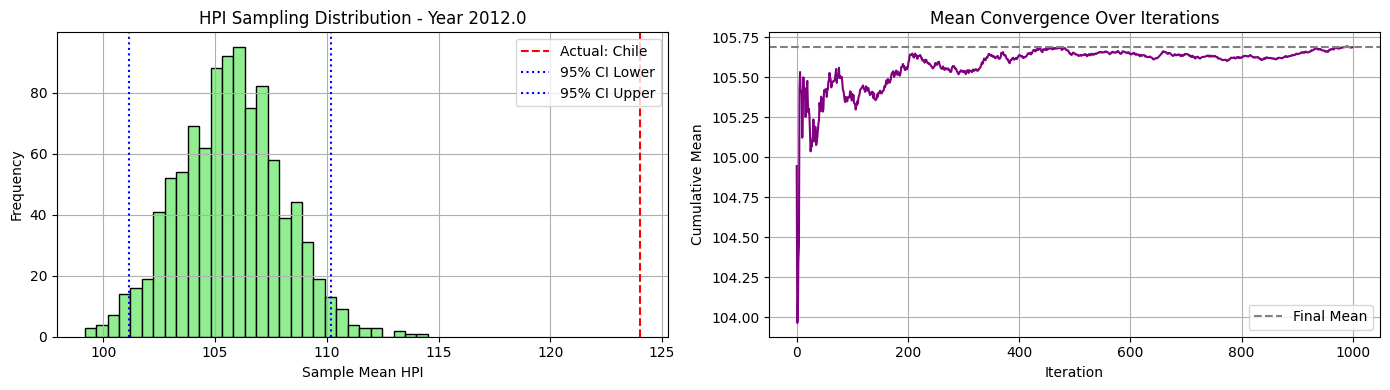


📅 Year 2013.0 - Available HPI values for sampling:
[130.06  90.58 136.52 100.81  94.32 107.8 ]


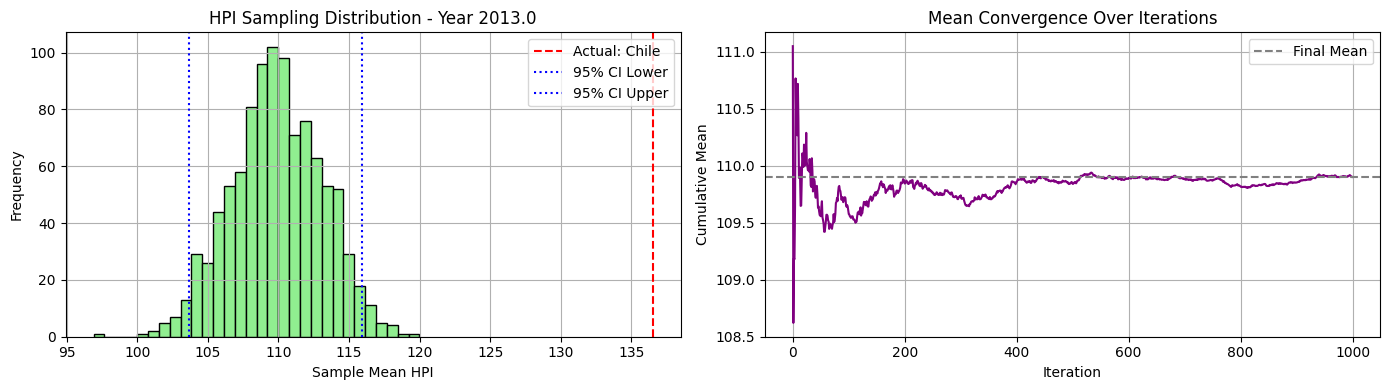


📅 Year 2014.0 - Available HPI values for sampling:
[140.75  94.37 151.67 102.38  95.84 109.43]


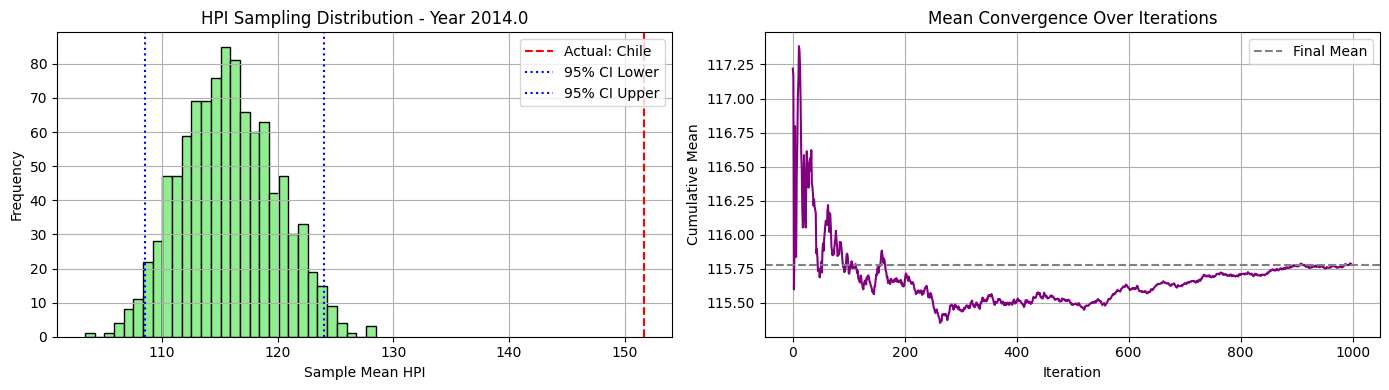


📅 Year 2015.0 - Available HPI values for sampling:
[152.93 106.75 162.89 104.86  97.   113.08]


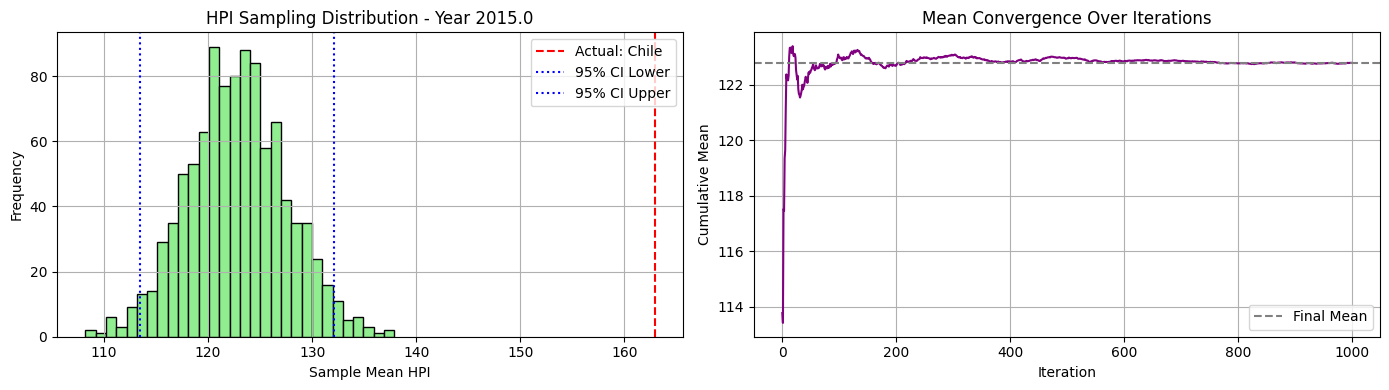


📅 Year 2016.0 - Available HPI values for sampling:
[167.48 121.03 172.75 107.18  91.86 116.09]


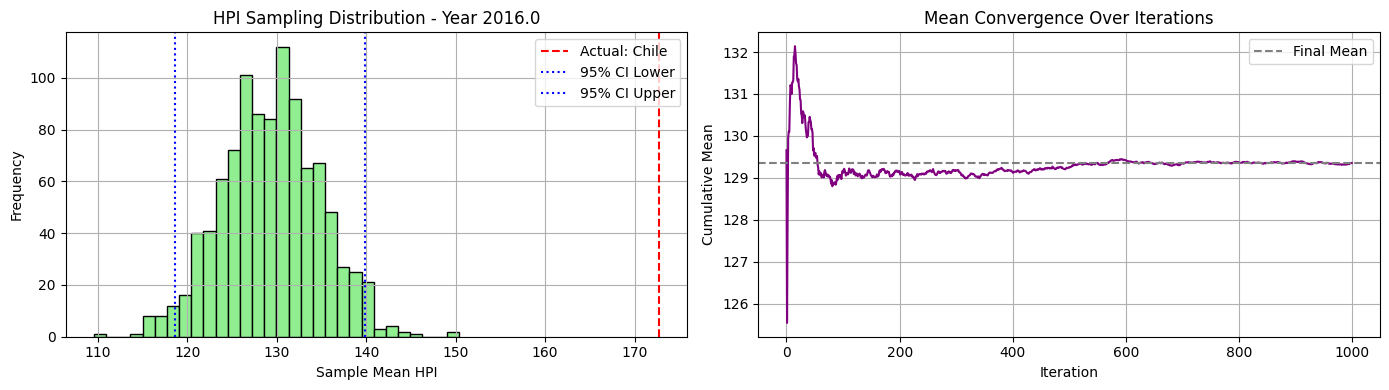


📅 Year 2017.0 - Available HPI values for sampling:
[178.56 135.84 183.99 109.91  88.54 117.6 ]


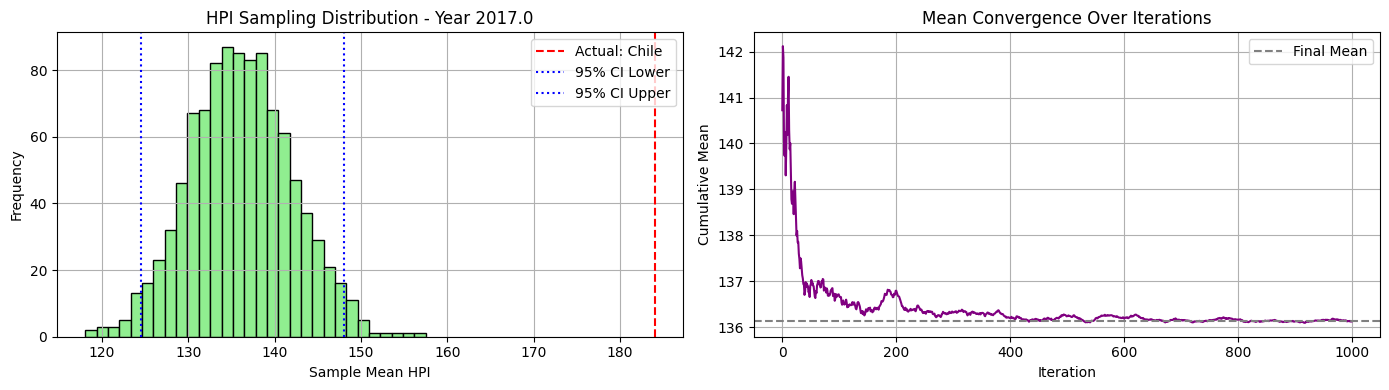


📅 Year 2018.0 - Available HPI values for sampling:
[188.24 155.3  191.85 112.04  90.72 120.22]


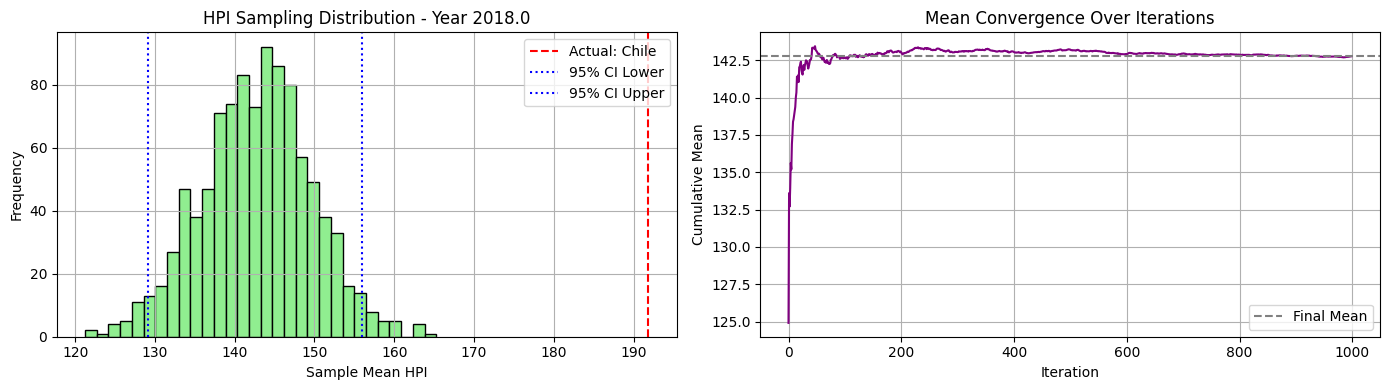


📅 Year 2019.0 - Available HPI values for sampling:
[198.37 181.64 198.37 113.84  97.25 121.93]


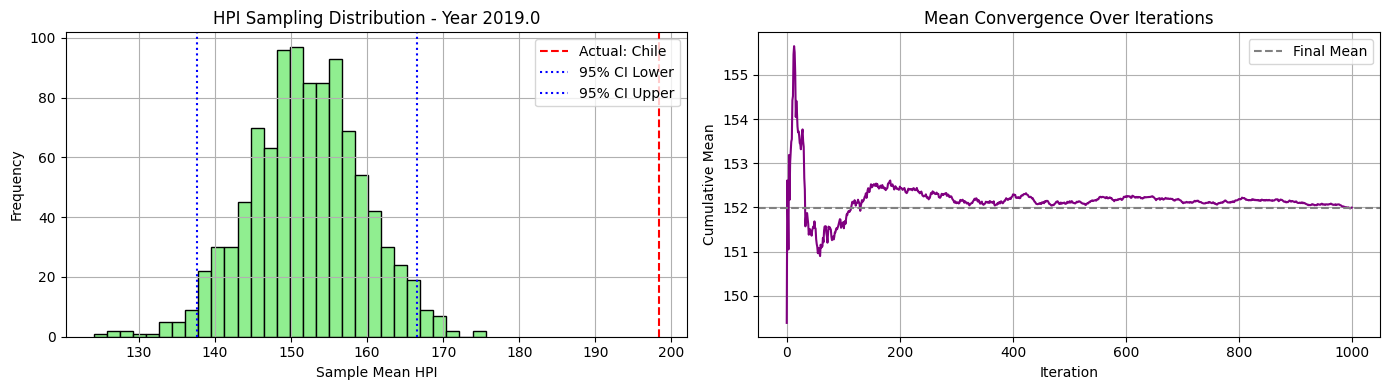


📅 Year 2020.0 - Available HPI values for sampling:
[203.12 190.63 213.74 113.93 106.71 126.56]


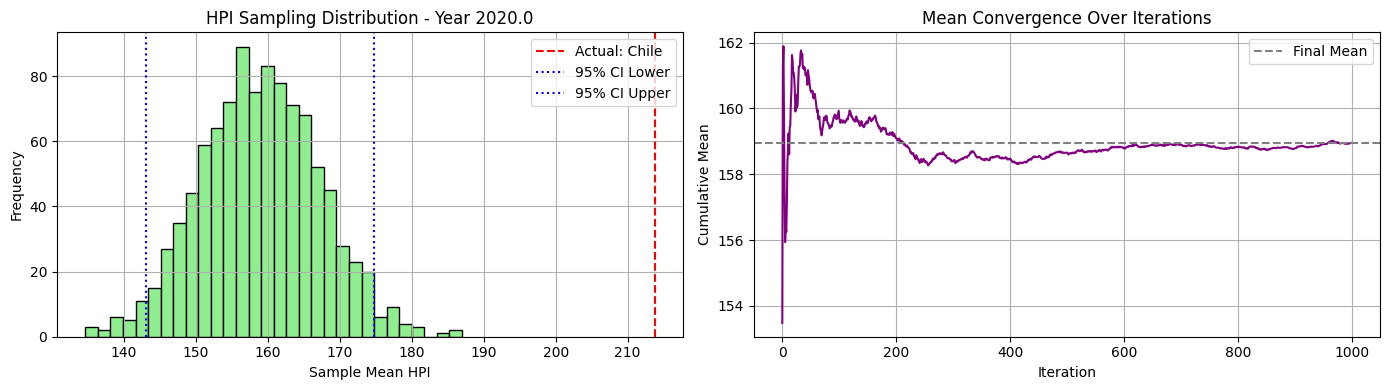


📅 Year 2021.0 - Available HPI values for sampling:
[214.9  222.1  248.26 120.7  121.41 143.73]


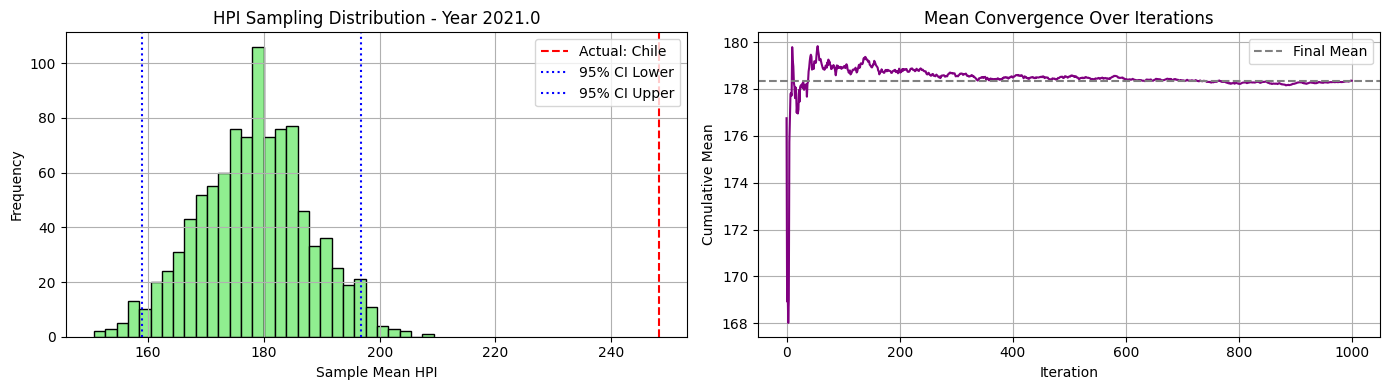


📅 Year 2022.0 - Available HPI values for sampling:
[230.   271.5  292.18 130.84 155.16 153.22]


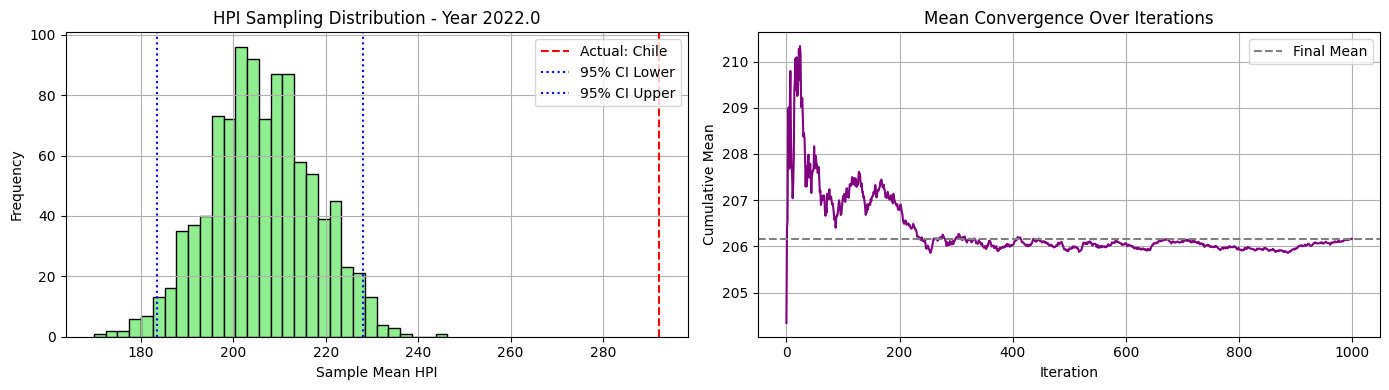


📅 Year 2023.0 - Available HPI values for sampling:
[245.75 290.98 309.37 134.8  157.88 143.99]


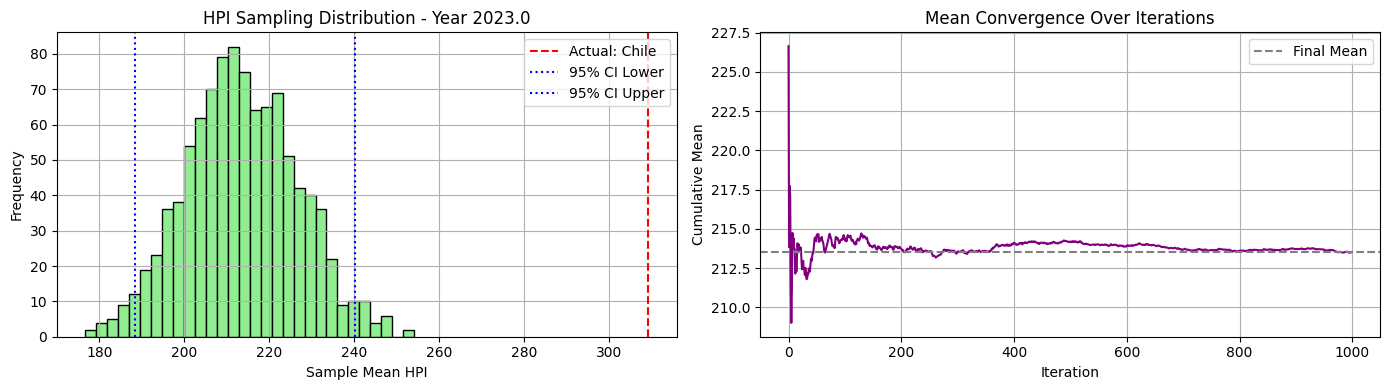


📅 Year 2024.0 - Available HPI values for sampling:
[269.02 328.1  328.24 138.61 186.66 142.46]


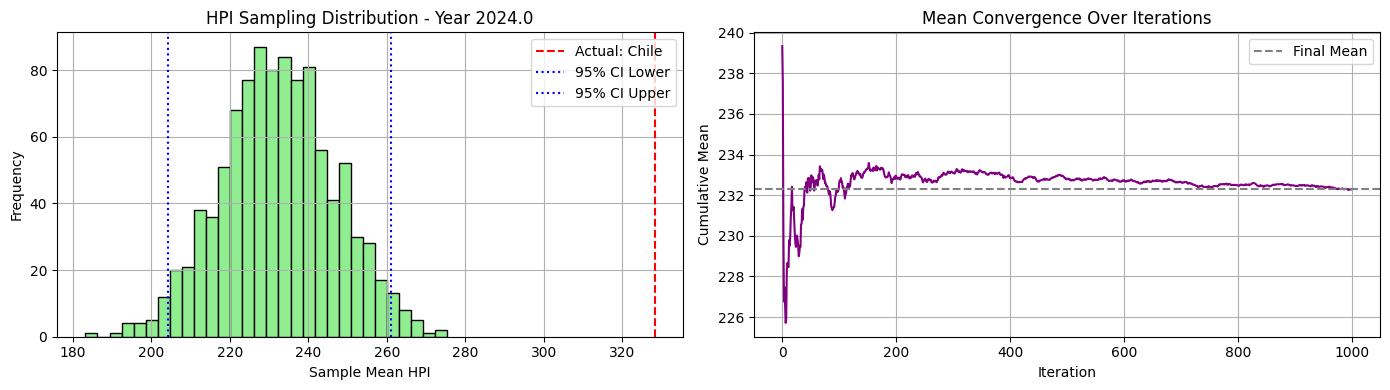

In [17]:
synthetic_00_43, excluded_00_43, actual_00_43 = estimate_hpi_by_cluster_sampling(hpi_winsorized, clusters_df, cluster_id=0, seed=43)

🔍 Cluster 1 selected. Excluding country: Belgium
📊 Sampling from countries: ['Austria', 'Bulgaria', 'Croatia', 'Cyprus', 'Estonia', 'Finland', 'Greece', 'Ireland', 'Latvia', 'Lithuania', 'Luxembourg', 'Malta', 'New Zealand', 'Portugal', 'Slovakia', 'Slovenia']

📅 Year 2010.0 - Available HPI values for sampling:
[100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.
 100. 100.]


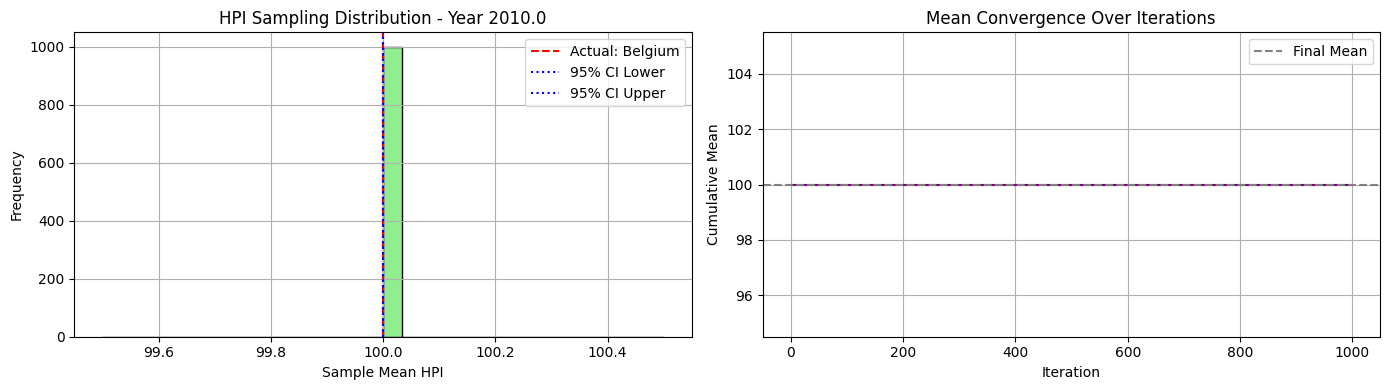


📅 Year 2011.0 - Available HPI values for sampling:
[104.22  94.49 100.16  96.68 108.47 103.17  94.53  94.49 110.42 106.6
 103.68  98.63 100.75  95.1   98.46 102.72]


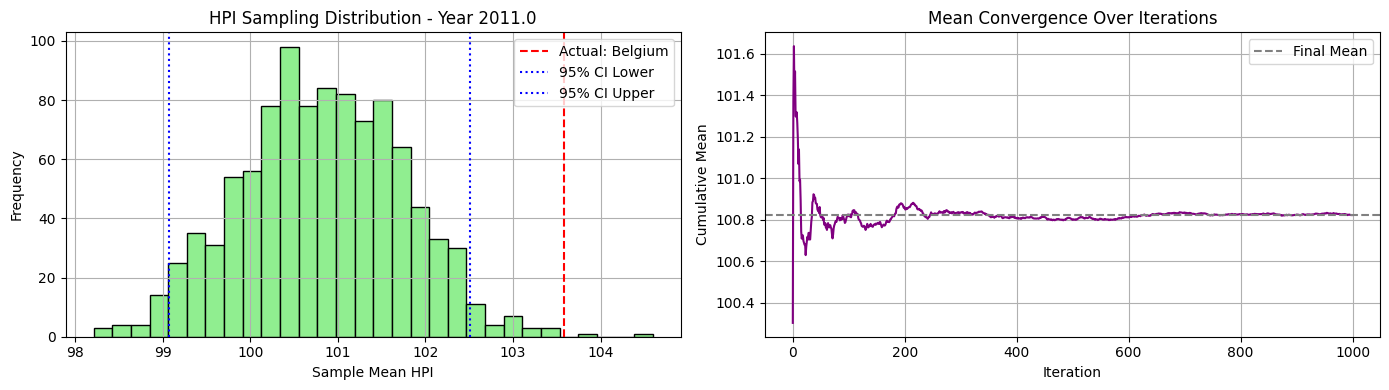


📅 Year 2012.0 - Available HPI values for sampling:
[117.13  92.69  98.62  91.54 116.34 105.64  88.37  88.37 113.71 106.36
 108.03 101.62 105.25  88.37  95.73  95.63]


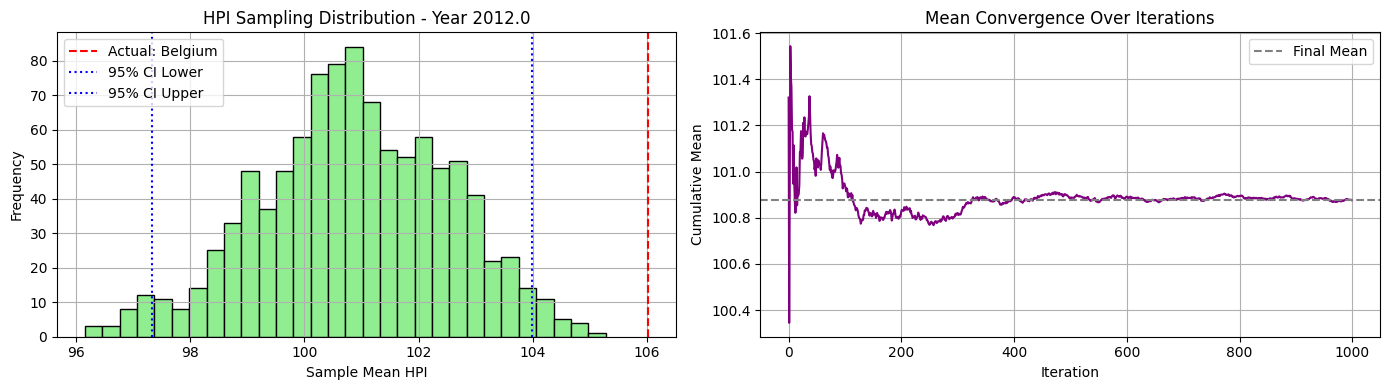


📅 Year 2013.0 - Available HPI values for sampling:
[122.59  90.65  94.7   85.58 128.77 106.87  85.58  85.58 121.5  107.65
 113.42 101.21 114.59  86.7   96.53  90.62]


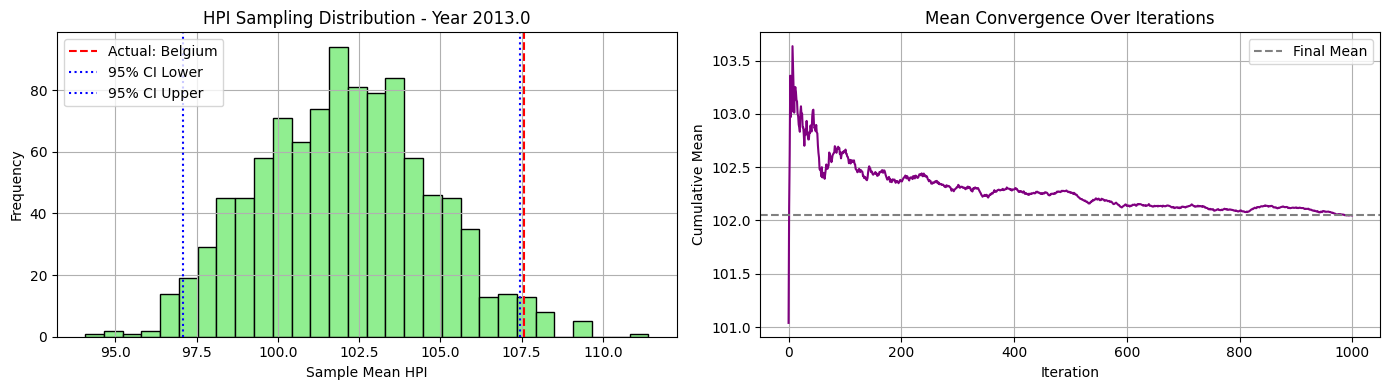


📅 Year 2014.0 - Available HPI values for sampling:
[126.79  91.95  93.19  84.64 146.41 106.5   84.64  84.66 128.78 114.57
 118.39 103.79 122.03  90.38  97.8   84.64]


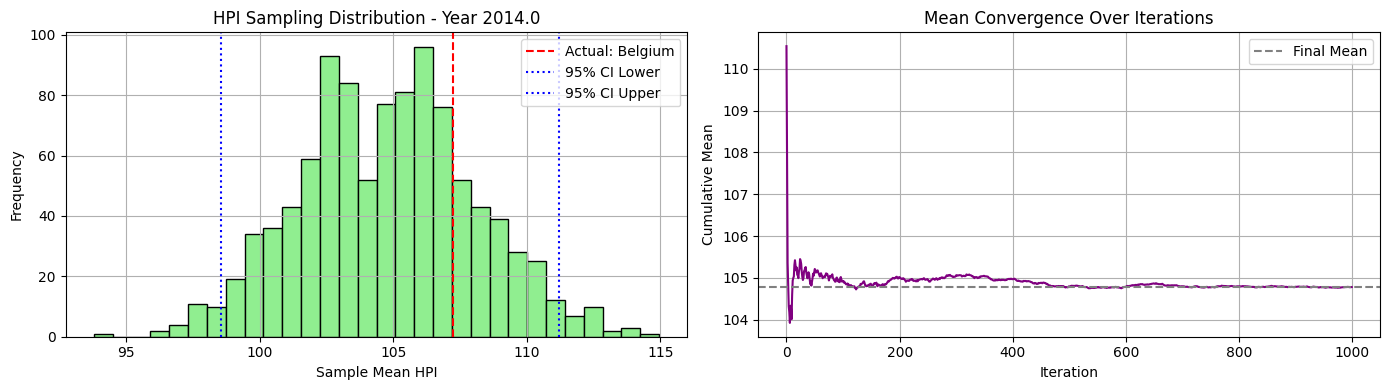


📅 Year 2015.0 - Available HPI values for sampling:
[132.06  94.51  90.54  84.67 156.46 106.5   84.67  94.36 124.46 118.76
 124.78 109.83 137.18  93.15 103.    85.32]


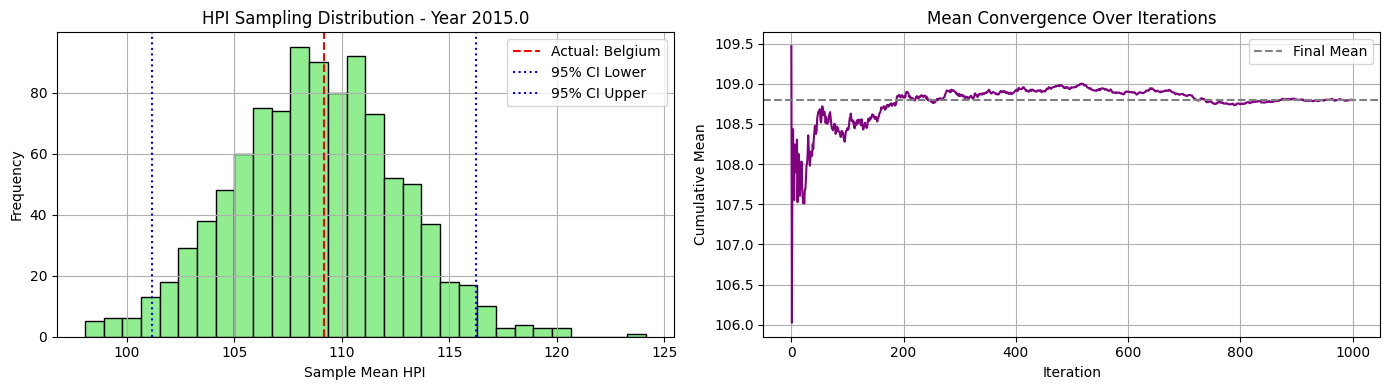


📅 Year 2016.0 - Available HPI values for sampling:
[141.76 101.15  91.33  88.1  163.86 107.86  88.1  101.42 135.02 125.16
 132.28 115.82 156.62  99.78 109.87  88.1 ]


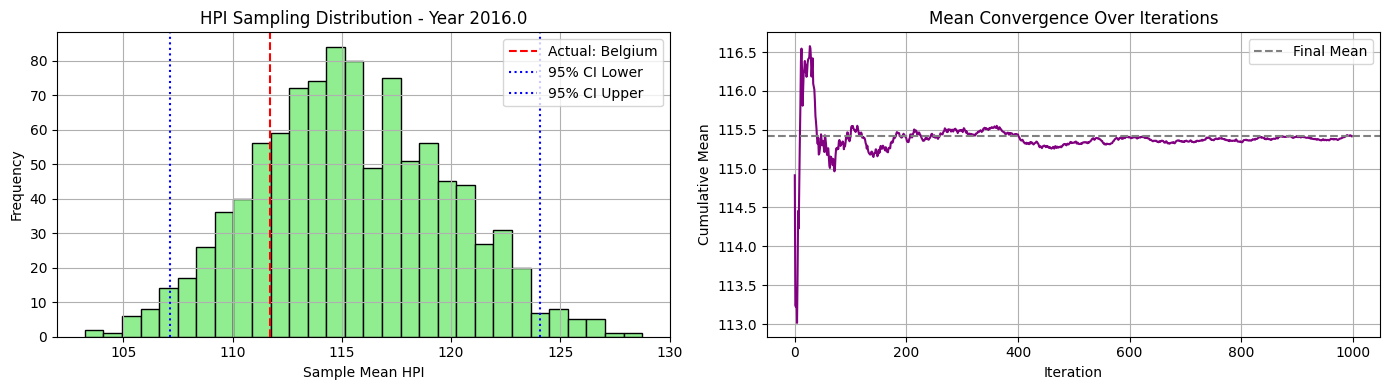


📅 Year 2017.0 - Available HPI values for sampling:
[147.08 109.91  94.84  88.54 172.91 109.02  88.54 112.44 146.87 136.34
 139.69 121.94 166.8  108.99 116.3   95.38]


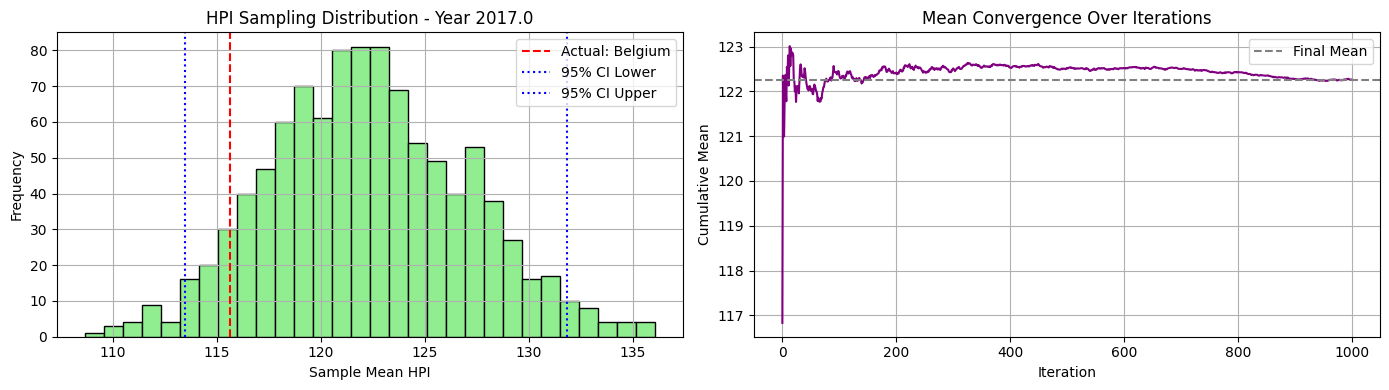


📅 Year 2018.0 - Available HPI values for sampling:
[157.24 117.15 100.59  90.72 183.13 110.06  90.72 123.96 160.92 146.29
 149.55 129.02 172.8  120.19 124.97 103.7 ]


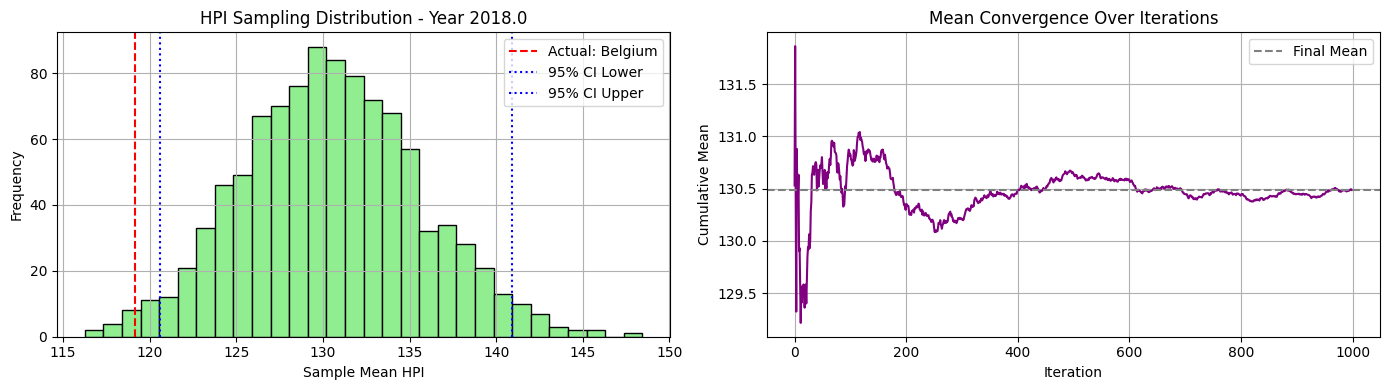


📅 Year 2019.0 - Available HPI values for sampling:
[163.43 124.2  109.64  97.25 195.98 110.52  97.25 126.85 175.33 156.3
 164.68 136.9  178.19 132.16 136.39 110.65]


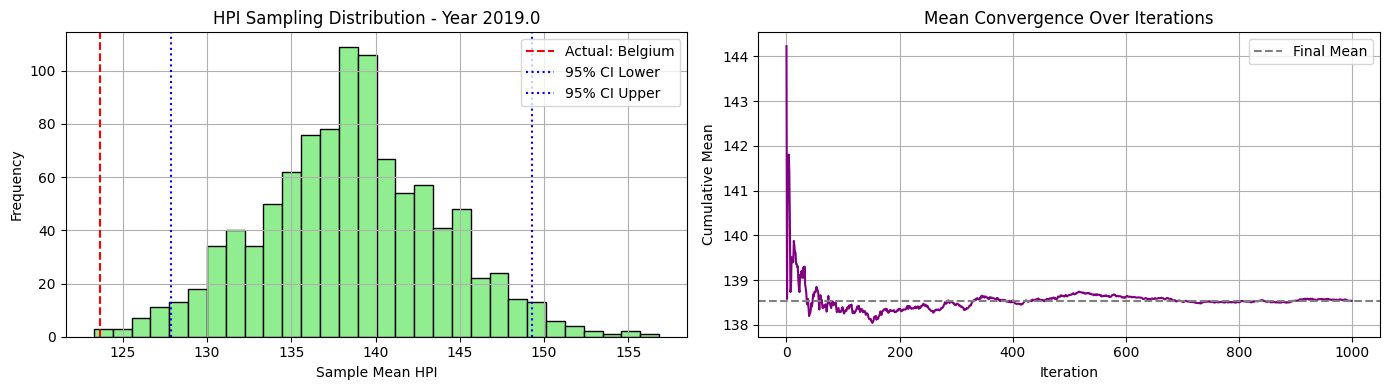


📅 Year 2020.0 - Available HPI values for sampling:
[174.92 129.87 118.06 106.71 207.78 112.49 106.71 127.24 181.42 167.66
 188.57 141.54 196.31 143.75 149.36 115.74]


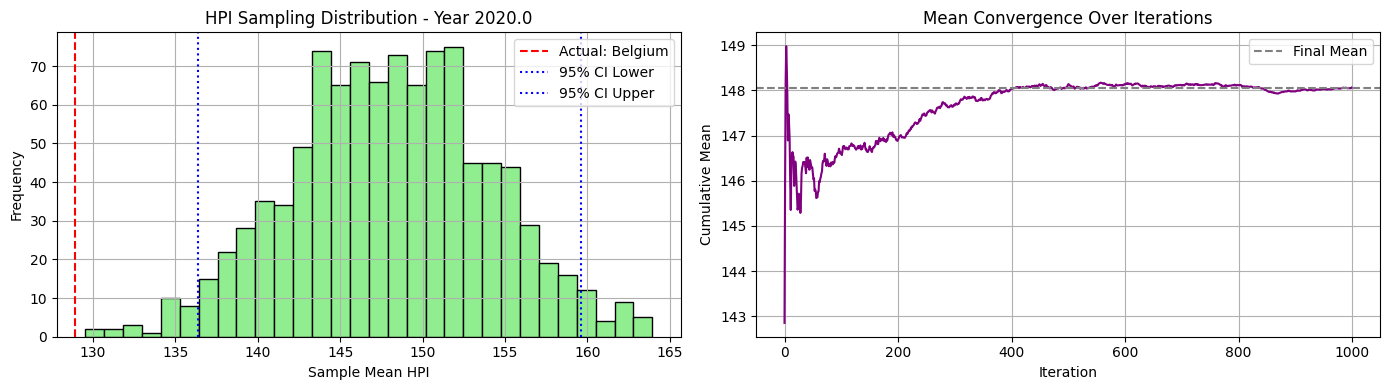


📅 Year 2021.0 - Available HPI values for sampling:
[195.48 141.14 126.64 112.34 239.04 117.62 112.34 137.77 201.18 194.58
 214.81 148.74 248.26 157.27 158.94 129.1 ]


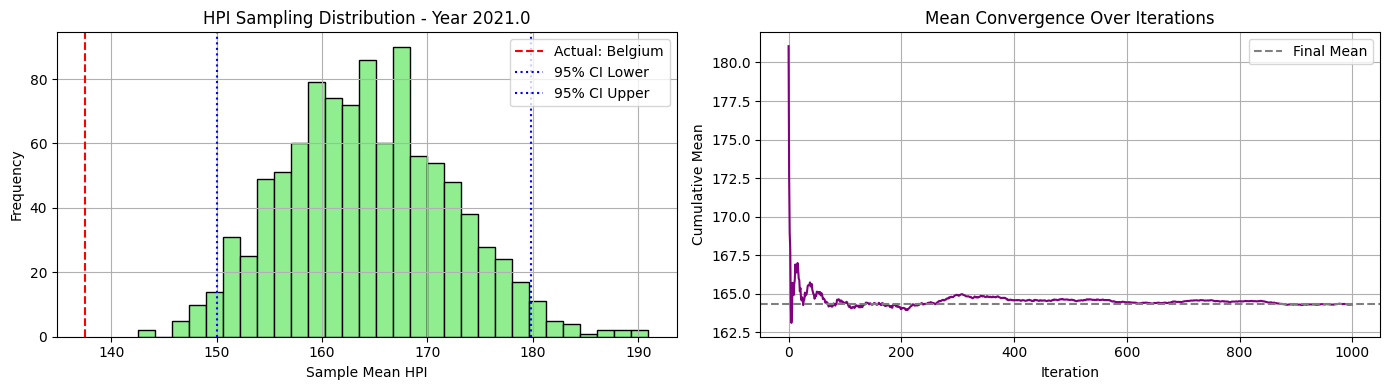


📅 Year 2022.0 - Available HPI values for sampling:
[215.62 160.59 145.44 118.98 292.18 118.98 118.98 154.73 229.01 231.64
 235.34 158.62 249.69 177.14 180.7  148.16]


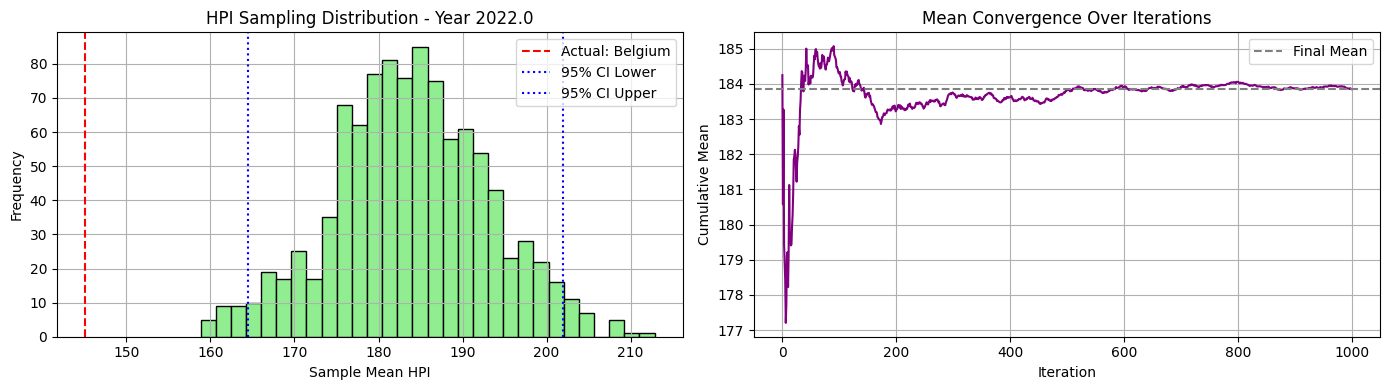


📅 Year 2023.0 - Available HPI values for sampling:
[212.08 176.43 162.82 112.27 309.37 112.27 112.27 159.48 237.56 254.38
 214.   168.5  233.54 191.66 180.36 158.88]


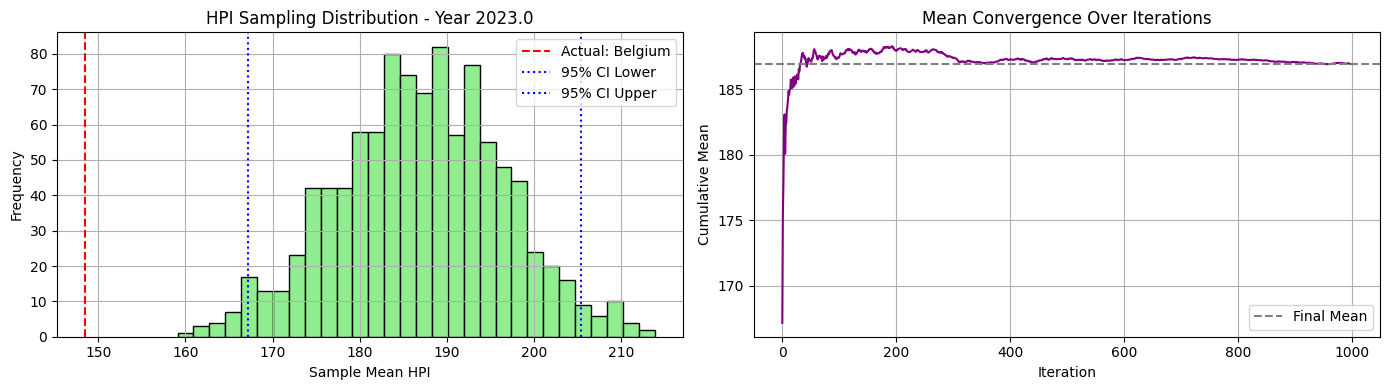


📅 Year 2024.0 - Available HPI values for sampling:
[207.62 205.53 179.7  119.1  328.24 119.1  119.1  173.07 247.54 279.12
 202.74 179.35 233.68 209.06 187.15 170.56]


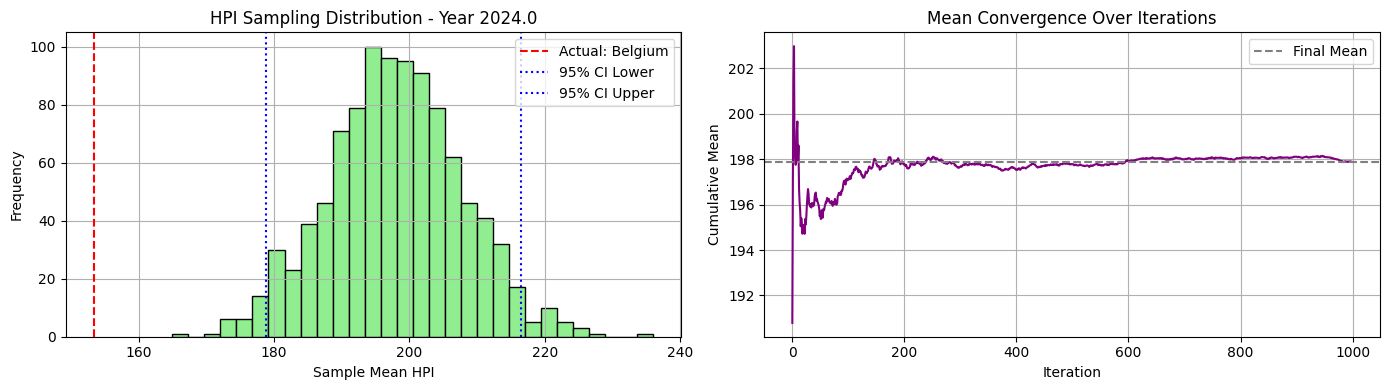

In [18]:
synthetic_01_43, excluded_01_43, actual_01_43 = estimate_hpi_by_cluster_sampling(hpi_winsorized, clusters_df, cluster_id=1, seed=43)

🔍 Cluster 2 selected. Excluding country: Brazil
📊 Sampling from countries: ['Australia', 'Canada', 'Czech Republic', 'Denmark', 'France', 'Germany', 'Iceland', 'Israel', 'Italy', 'Malaysia', 'Mexico', 'Netherlands', 'Norway', 'Peru', 'Philippines', 'Poland', 'Romania', 'Serbia', 'Singapore', 'South Africa', 'Spain', 'Sweden', 'Switzerland', 'Thailand', 'Turkey', 'United Kingdom', 'USA']

📅 Year 2010.0 - Available HPI values for sampling:
[100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.
 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.]


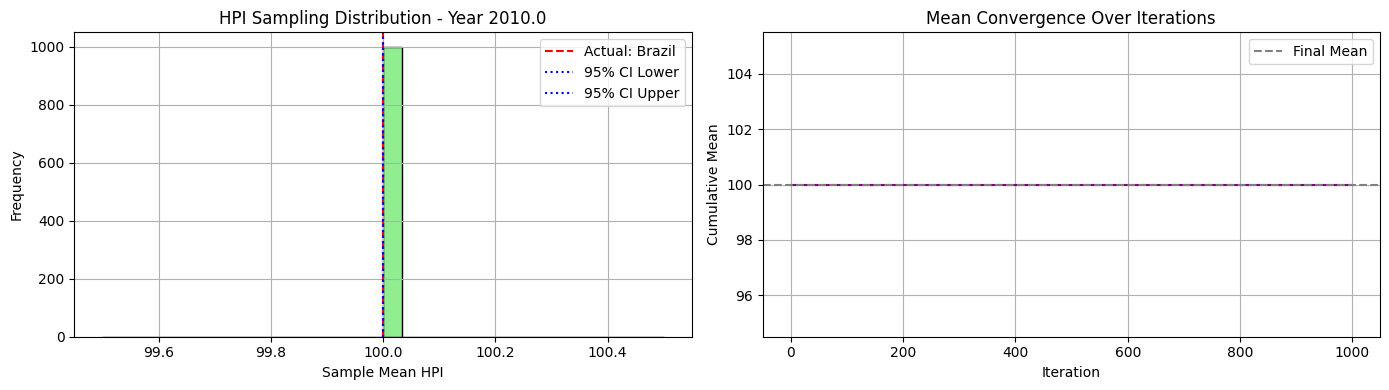


📅 Year 2011.0 - Available HPI values for sampling:
[ 97.84 105.75 100.02  98.29 105.69 102.42 105.5  110.52 101.36 109.83
 105.8   98.02 108.01 110.52 105.57 100.08  94.49  97.62 109.46 103.59
  94.49 102.58 107.51 104.26 108.8   98.54  97.24]


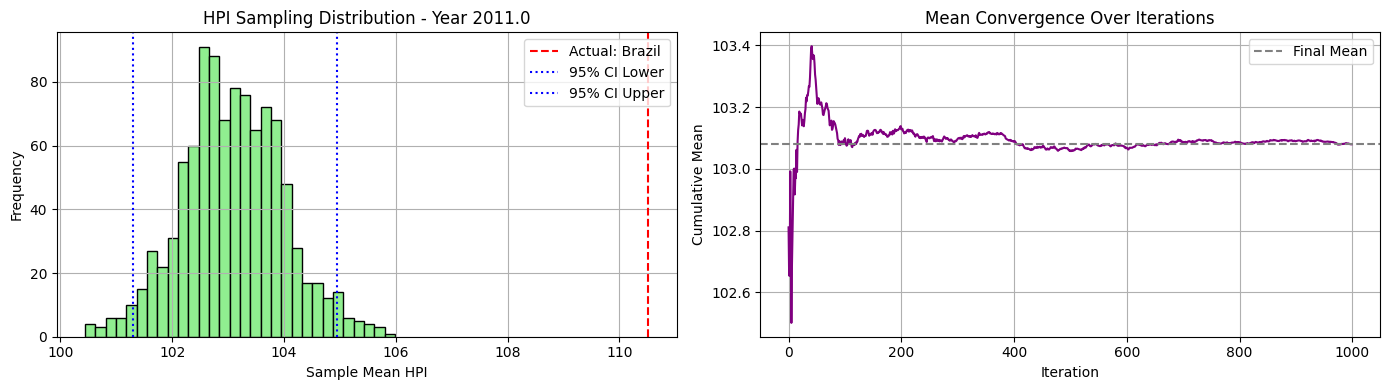


📅 Year 2012.0 - Available HPI values for sampling:
[ 97.53 110.62  98.56  95.67 105.11 105.48 112.38 114.1   98.77 124.02
 109.17  91.44 115.34 124.02 114.94  96.58  88.37  95.68 112.02 108.41
  88.37 103.86 113.72 107.63 120.68  98.92 101.82]


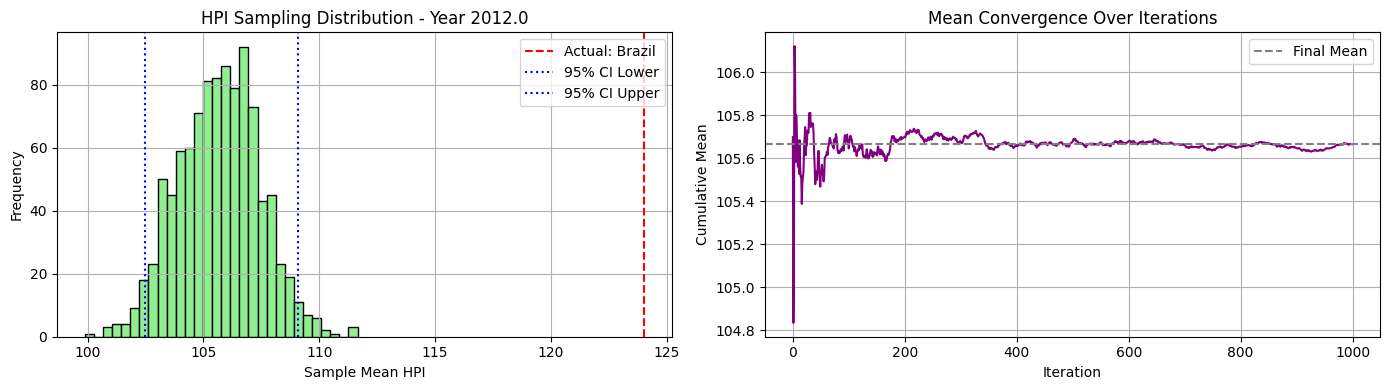


📅 Year 2013.0 - Available HPI values for sampling:
[103.99 112.76  98.58  99.37 103.13 108.68 119.18 124.45  92.38 136.52
 114.75  85.95 119.98 136.52 127.86  92.35  85.58  90.62 115.56 115.41
  85.58 109.22 118.3  115.99 134.46 101.46 111.83]


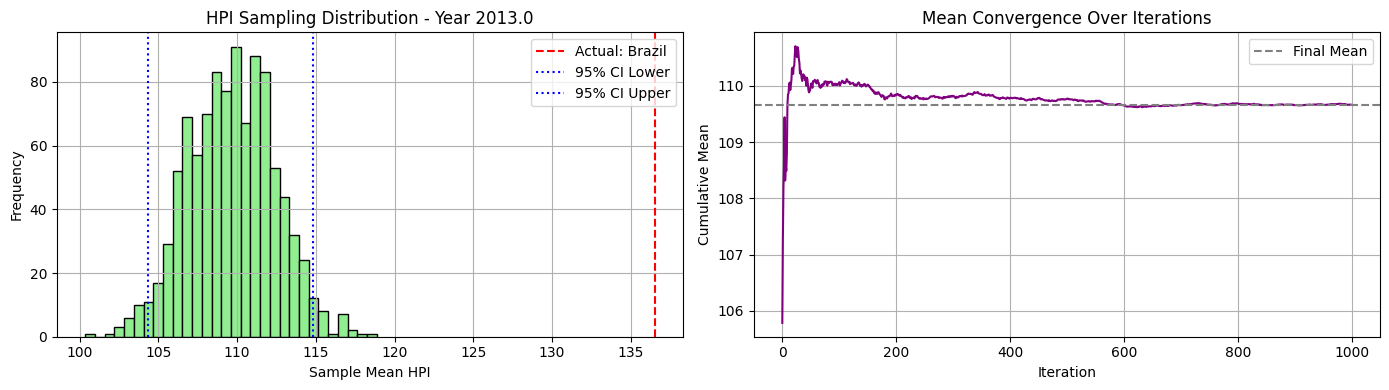


📅 Year 2014.0 - Available HPI values for sampling:
[113.41 118.86 101.   103.12 101.58 111.85 128.94 132.36  88.02 151.67
 119.64  86.66 123.24 151.67 142.76  93.27  84.64  95.77 112.25 123.99
  84.64 119.52 121.46 127.07 151.25 109.6  118.88]


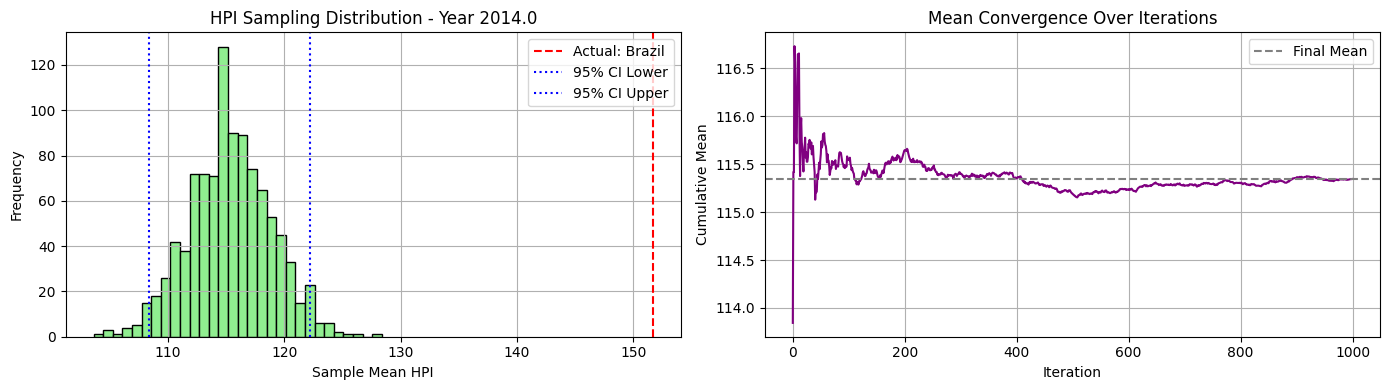


📅 Year 2015.0 - Available HPI values for sampling:
[123.65 128.43 105.01 110.29 100.22 117.12 139.74 140.12  84.67 162.89
 129.39  89.69 130.76 162.89 157.04  94.69  84.67  99.5  107.92 131.8
  84.67 135.2  124.08 136.   162.89 116.12 125.18]


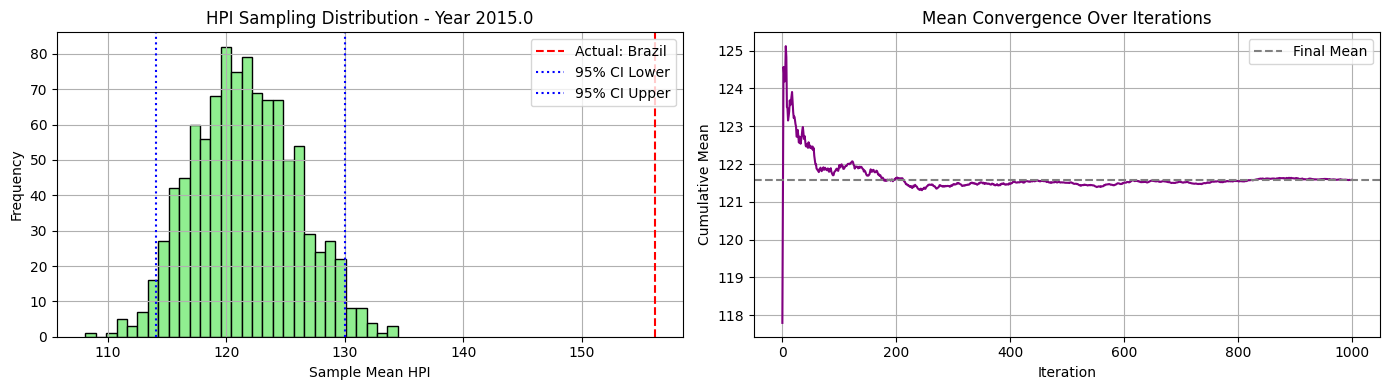


📅 Year 2016.0 - Available HPI values for sampling:
[130.44 148.66 112.52 115.5  101.25 125.93 154.59 150.56  88.1  172.75
 138.82  94.43 139.95 164.18 172.75  96.44  88.91 110.62 104.55 138.22
  88.1  146.34 124.32 142.4  172.75 124.27 131.88]


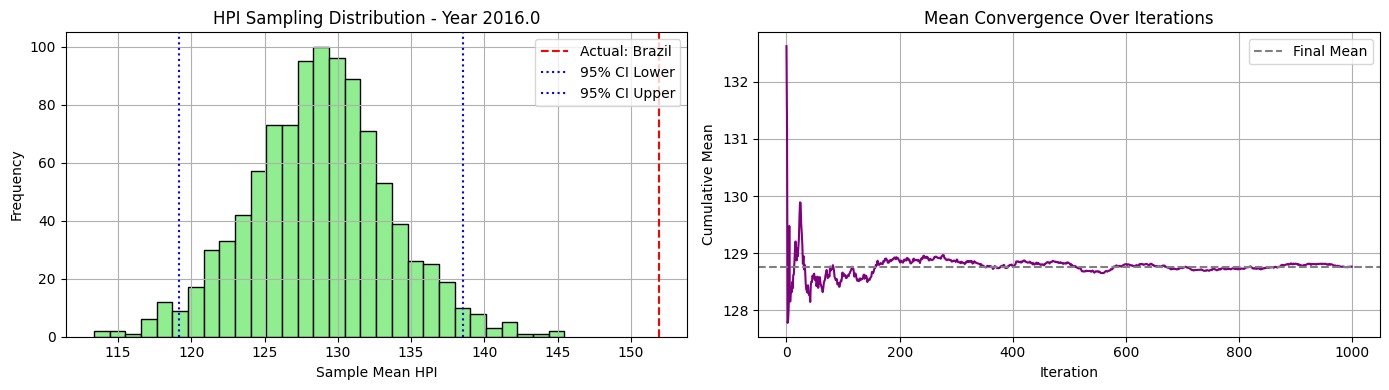


📅 Year 2017.0 - Available HPI values for sampling:
[141.34 172.3  125.7  120.63 104.46 133.62 183.99 156.44  88.54 183.99
 149.69 102.06 146.91 168.   178.82 100.16  93.93 115.3  103.4  143.94
  88.54 156.06 125.42 146.48 183.99 129.93 139.61]


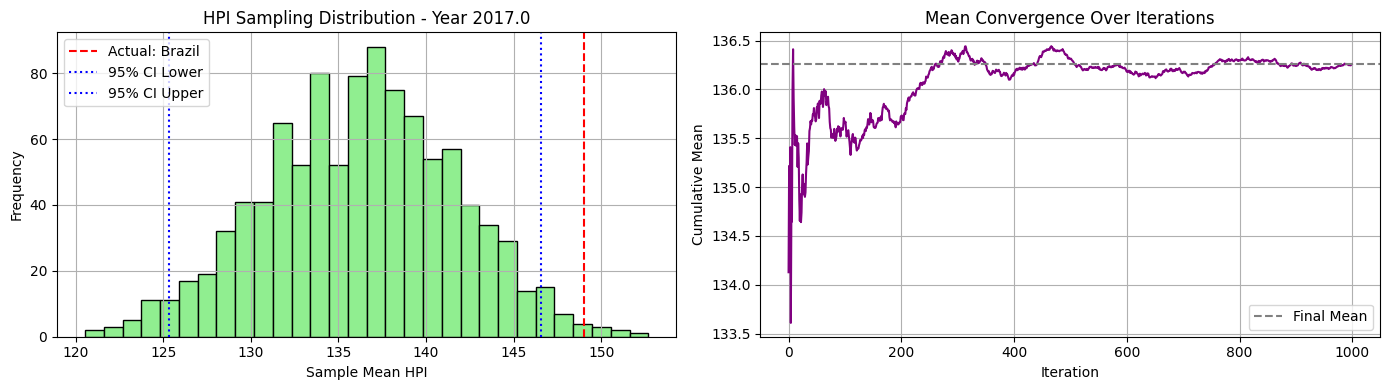


📅 Year 2018.0 - Available HPI values for sampling:
[139.3  178.24 136.52 126.31 107.52 142.52 191.85 155.14  90.72 191.85
 162.97 111.57 149.04 168.42 183.82 106.75  99.37 123.06 111.46 148.96
  90.72 154.6  129.16 153.9  191.85 134.04 147.35]


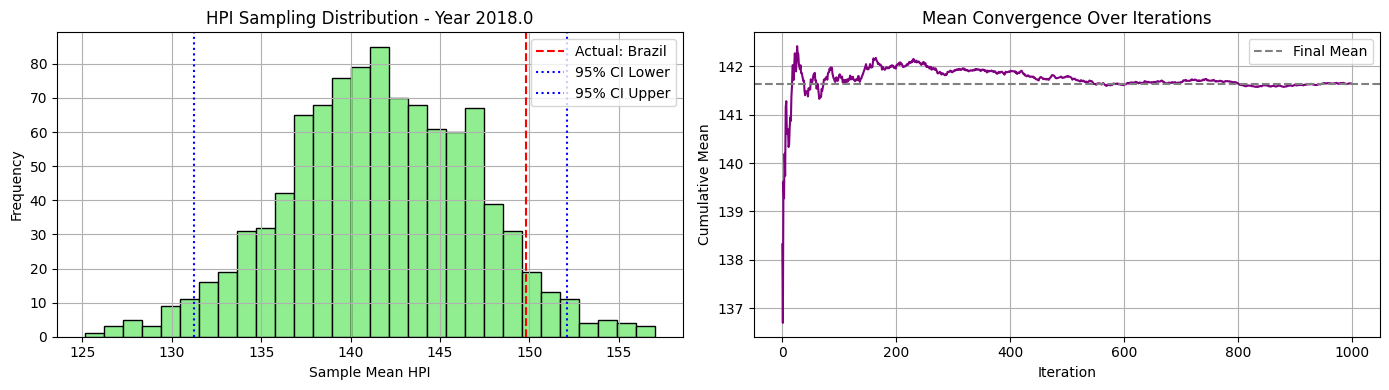


📅 Year 2019.0 - Available HPI values for sampling:
[133.64 179.4  149.02 129.62 111.1  150.75 198.37 158.06  97.25 196.06
 176.92 119.62 152.73 172.03 195.26 116.01 102.72 135.77 113.98 152.69
  97.25 158.44 133.99 155.1  198.37 135.37 153.14]


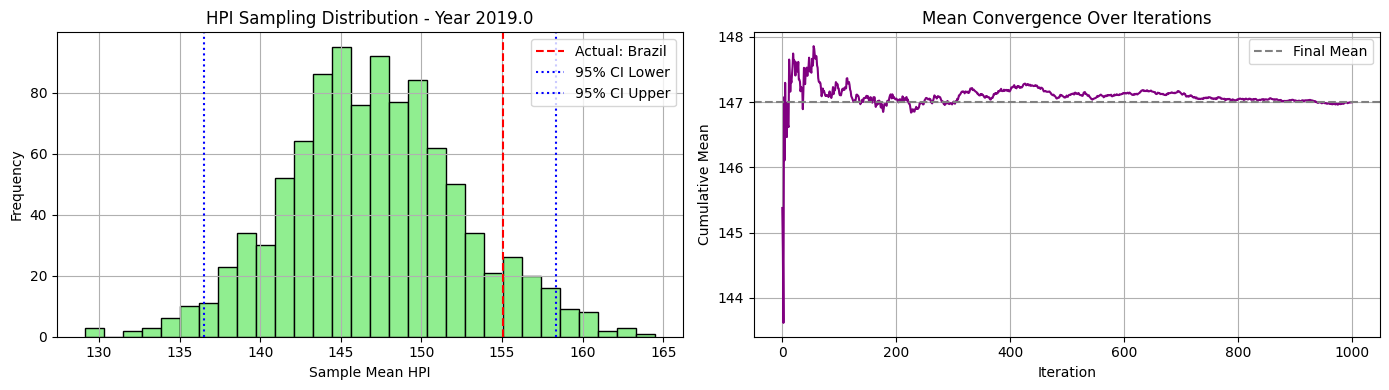


📅 Year 2020.0 - Available HPI values for sampling:
[140.85 190.73 161.56 136.24 116.89 162.48 213.74 162.9  106.71 198.37
 187.18 129.21 159.24 173.67 213.74 128.18 107.53 149.28 115.8  156.31
 106.71 165.09 137.31 160.6  213.74 139.24 163.52]


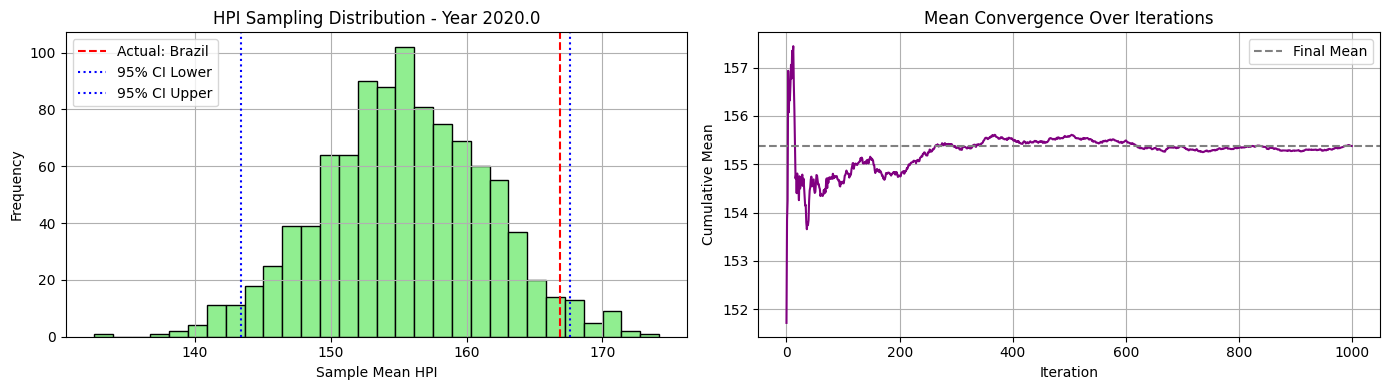


📅 Year 2021.0 - Available HPI values for sampling:
[165.39 214.88 193.46 152.2  124.38 181.28 248.26 176.65 112.34 200.69
 201.94 147.93 175.91 173.6  211.74 139.92 112.34 166.04 125.04 166.82
 112.34 181.79 145.16 164.23 248.26 150.58 188.56]


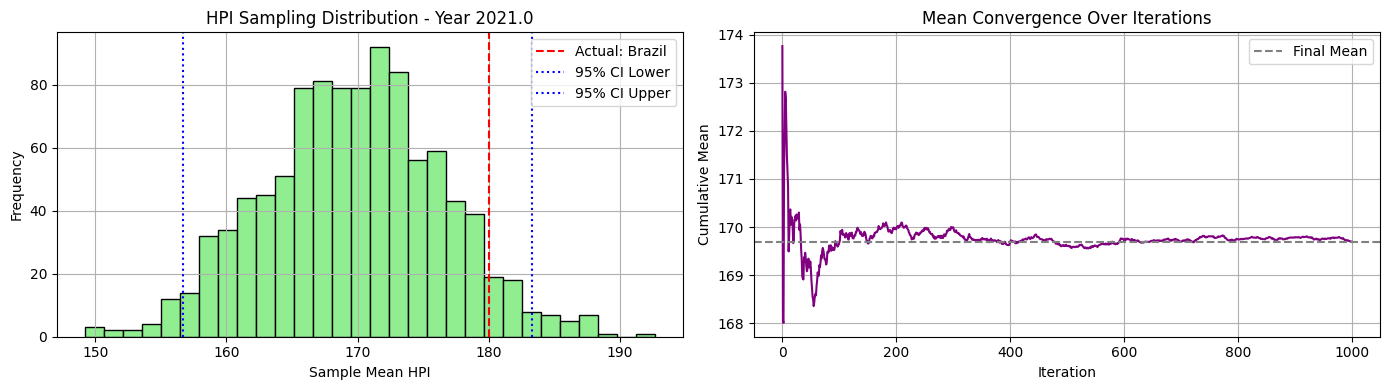


📅 Year 2022.0 - Available HPI values for sampling:
[179.02 235.32 226.15 151.49 132.1  190.42 292.18 207.16 118.98 207.75
 219.93 167.57 185.13 172.65 223.73 156.43 120.29 191.49 137.74 174.03
 118.98 188.27 154.42 169.16 292.18 164.55 213.  ]


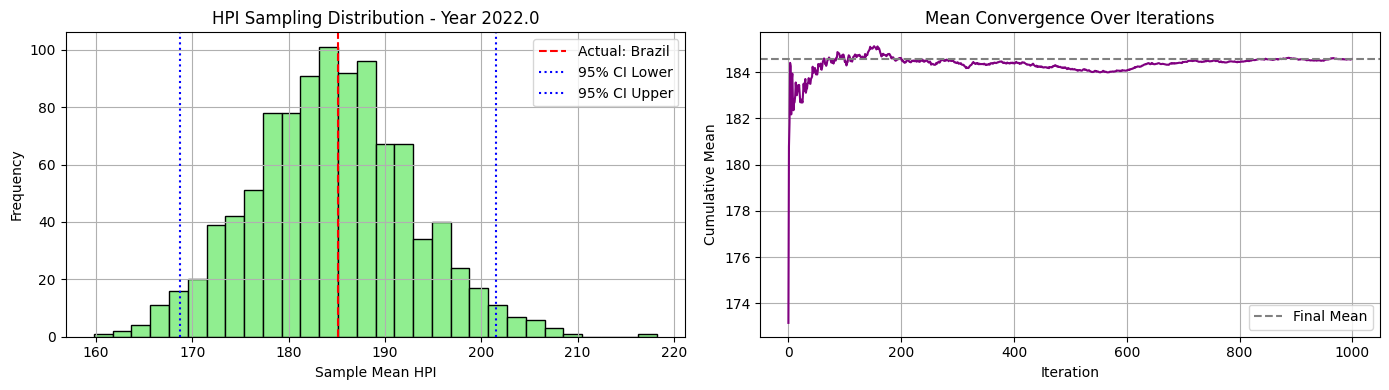


📅 Year 2023.0 - Available HPI values for sampling:
[178.65 221.05 222.4  151.24 131.52 174.25 309.37 214.23 112.27 216.19
 243.89 164.36 184.12 175.16 248.04 170.23 124.06 209.99 148.01 176.62
 112.27 178.36 157.81 174.79 309.37 165.   221.72]


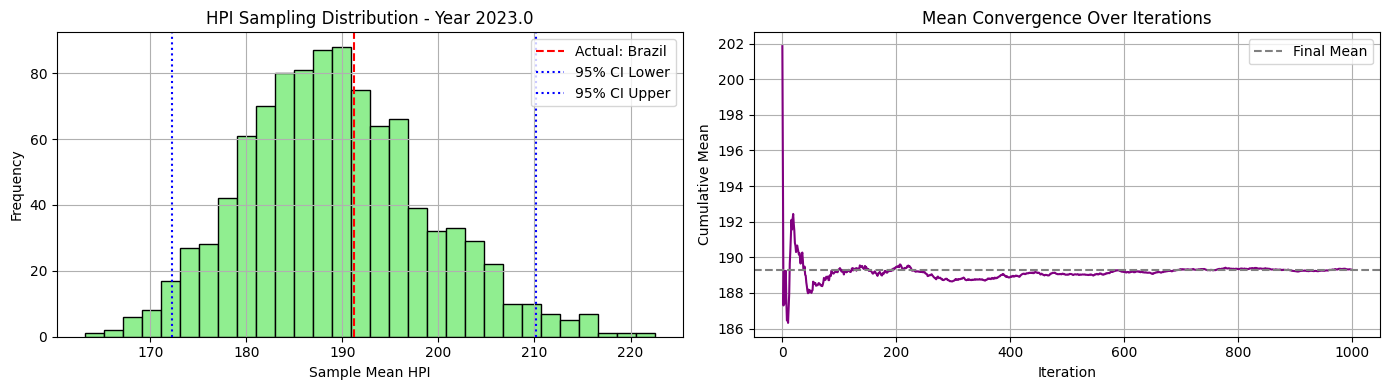


📅 Year 2024.0 - Available HPI values for sampling:
[192.53 217.35 233.42 156.73 126.68 171.5  328.24 224.54 119.1  225.06
 266.38 177.7  189.05 175.38 256.03 195.72 130.34 220.7  155.12 178.1
 119.1  178.49 160.56 178.06 328.24 166.38 231.23]


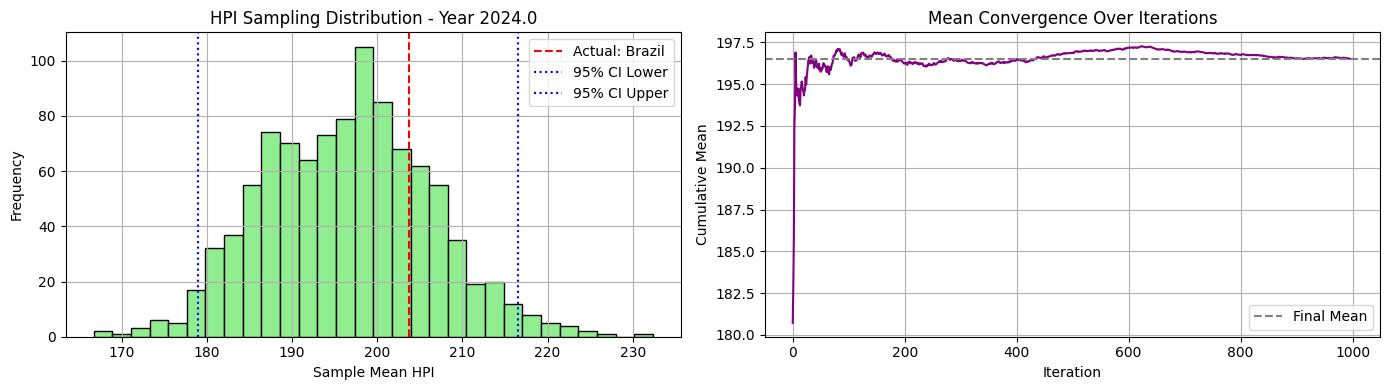

In [19]:
synthetic_02_43, excluded_02_43, actual_02_43 = estimate_hpi_by_cluster_sampling(hpi_winsorized, clusters_df, cluster_id=2, seed=43)

### Experiment with seed 52

🔍 Cluster 0 selected. Excluding country: Hungary
📊 Sampling from countries: ['Chile', 'Colombia', 'India', 'Japan', 'Russia', 'South Korea']

📅 Year 2010.0 - Available HPI values for sampling:
[100. 100. 100. 100. 100. 100.]


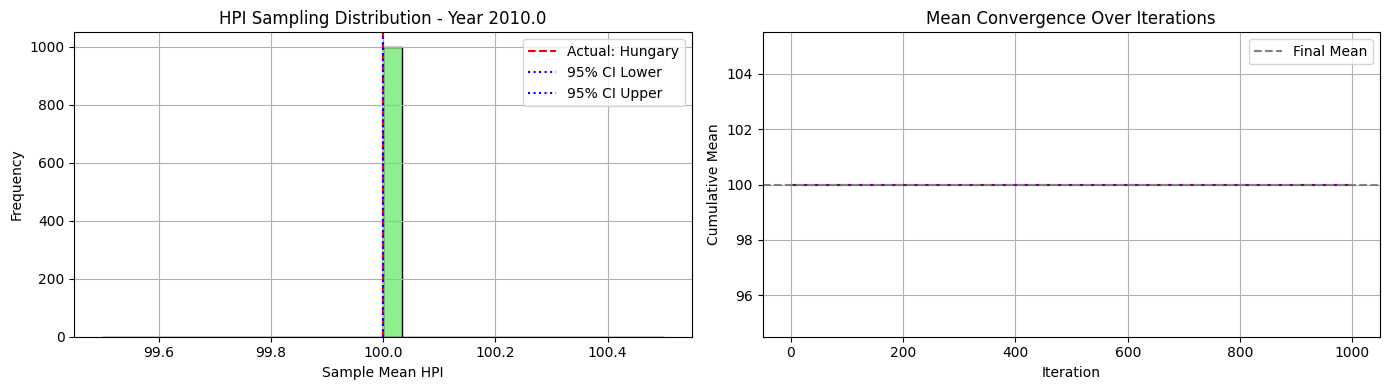


📅 Year 2011.0 - Available HPI values for sampling:
[110.52 107.89 110.52 100.07  94.49 105.23]


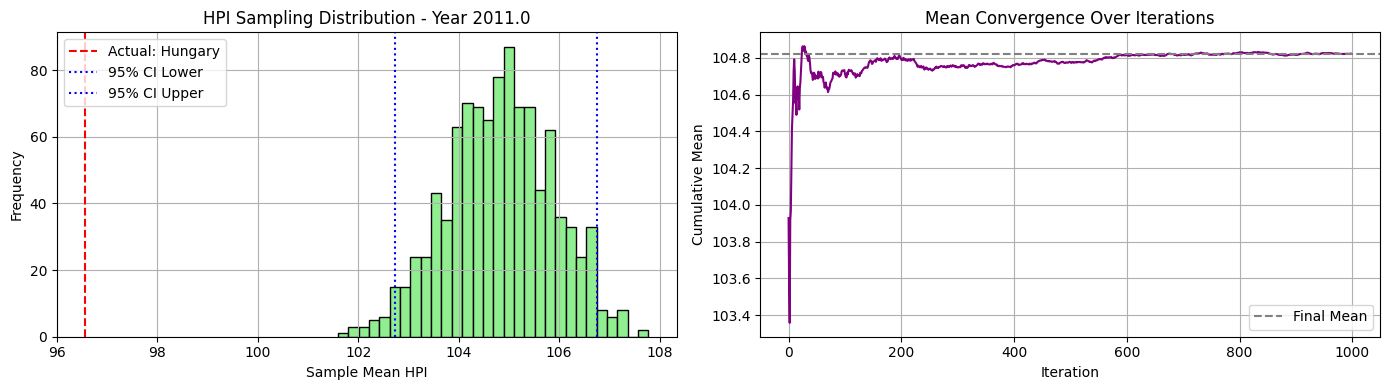


📅 Year 2012.0 - Available HPI values for sampling:
[124.02 118.79 124.02  99.19  91.1  108.25]


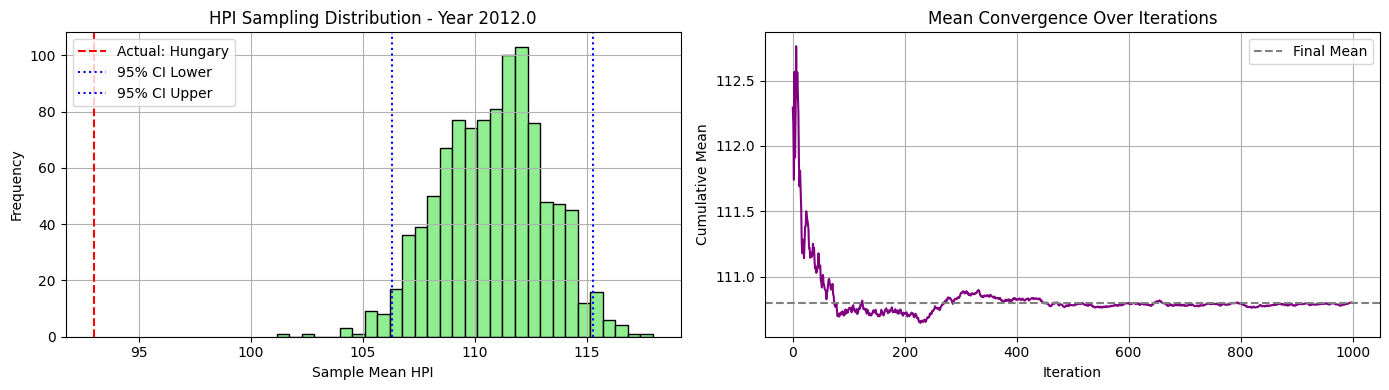


📅 Year 2013.0 - Available HPI values for sampling:
[136.52 130.06 136.52 100.81  94.32 107.8 ]


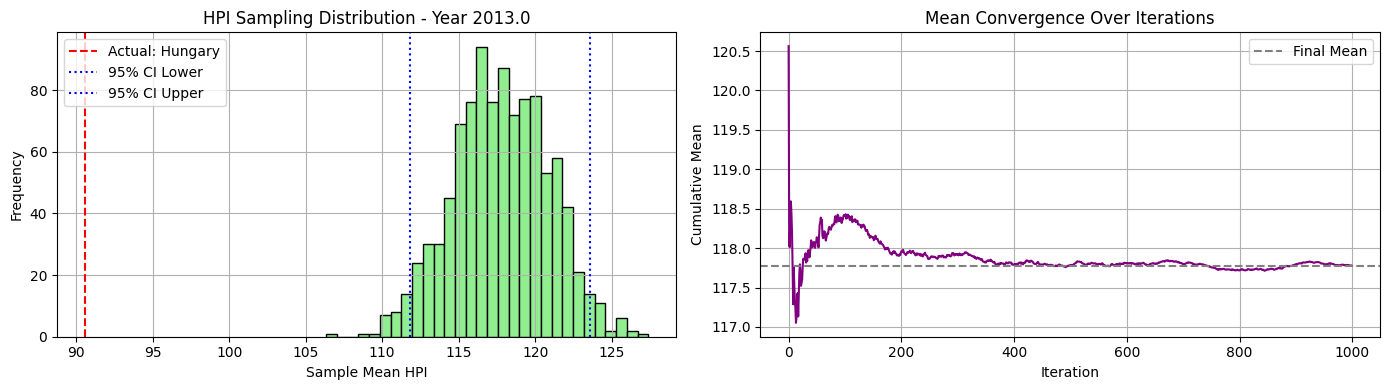


📅 Year 2014.0 - Available HPI values for sampling:
[151.67 140.75 151.67 102.38  95.84 109.43]


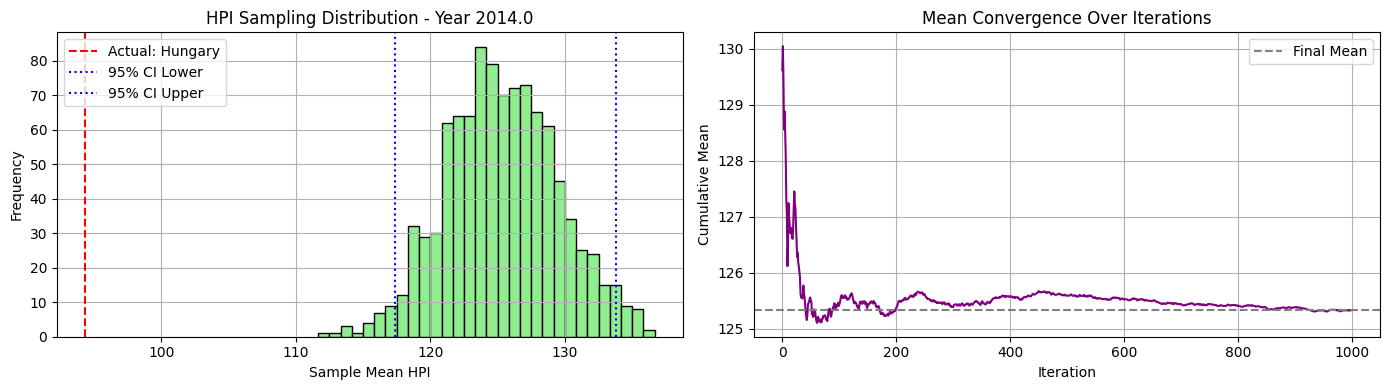


📅 Year 2015.0 - Available HPI values for sampling:
[162.89 152.93 162.89 104.86  97.   113.08]


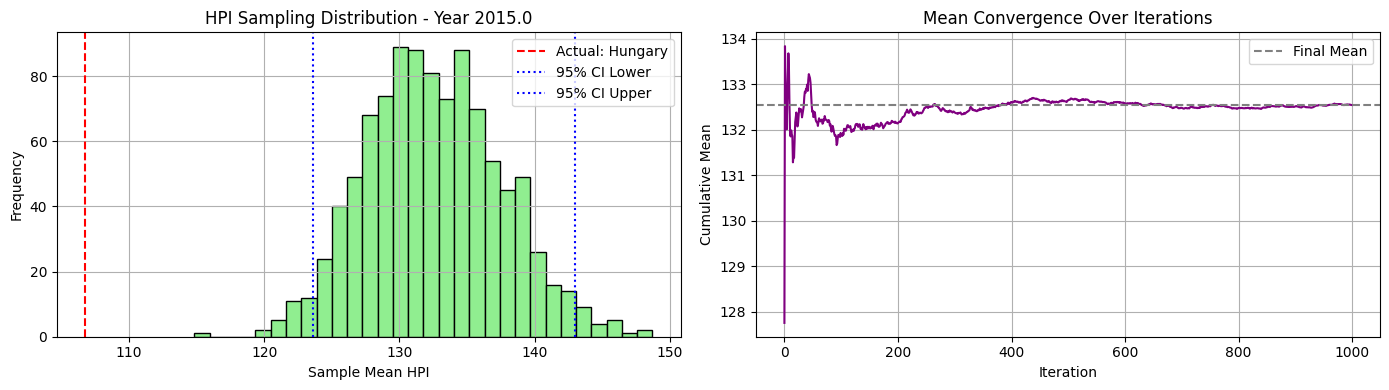


📅 Year 2016.0 - Available HPI values for sampling:
[172.75 167.48 172.75 107.18  91.86 116.09]


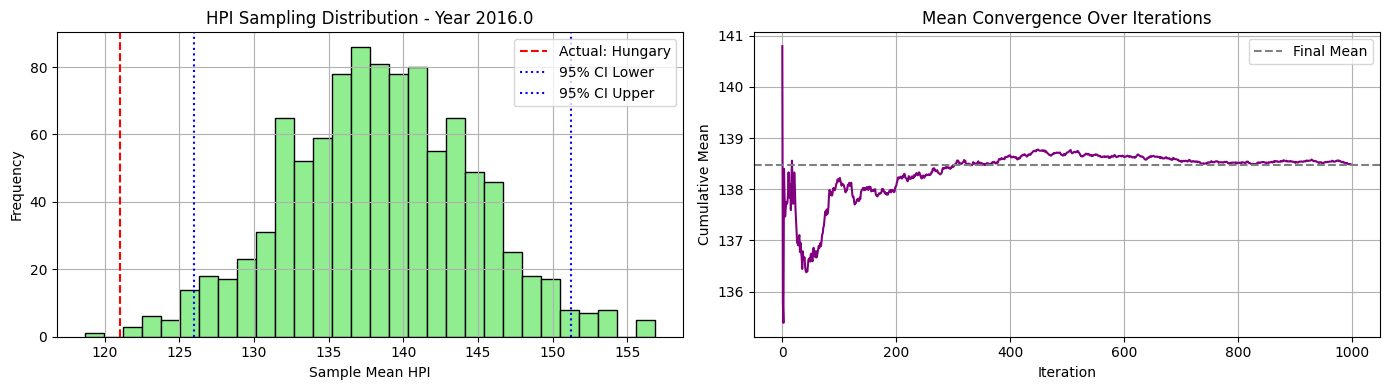


📅 Year 2017.0 - Available HPI values for sampling:
[183.99 178.56 183.99 109.91  88.54 117.6 ]


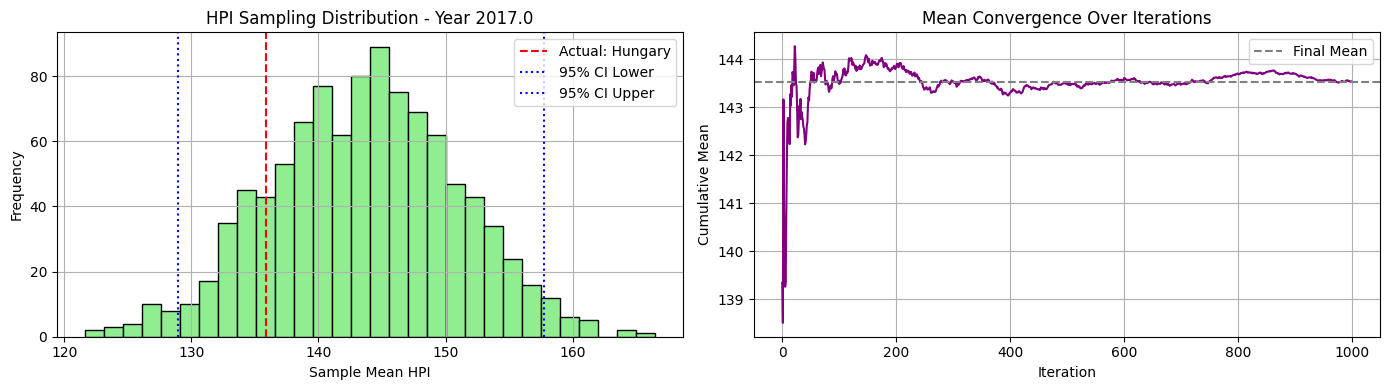


📅 Year 2018.0 - Available HPI values for sampling:
[191.85 188.24 191.85 112.04  90.72 120.22]


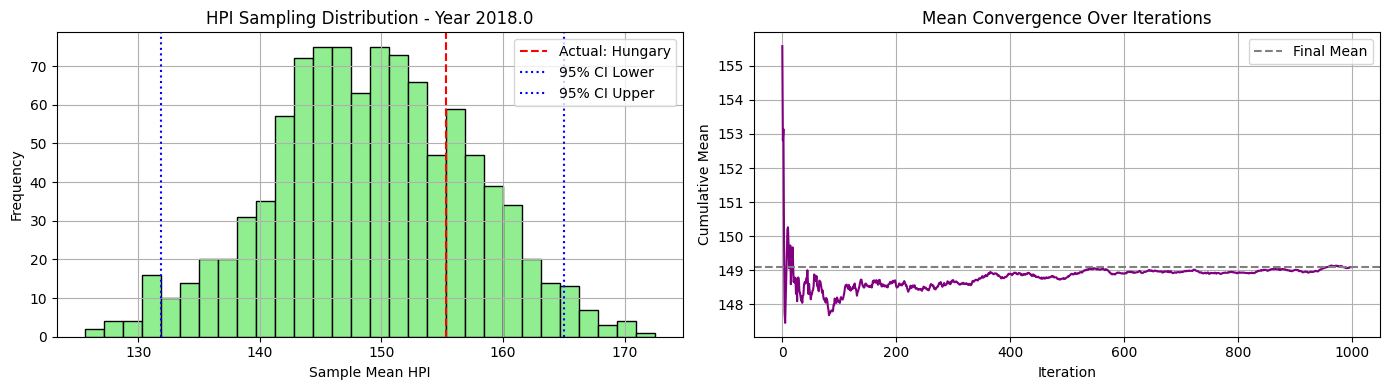


📅 Year 2019.0 - Available HPI values for sampling:
[198.37 198.37 198.37 113.84  97.25 121.93]


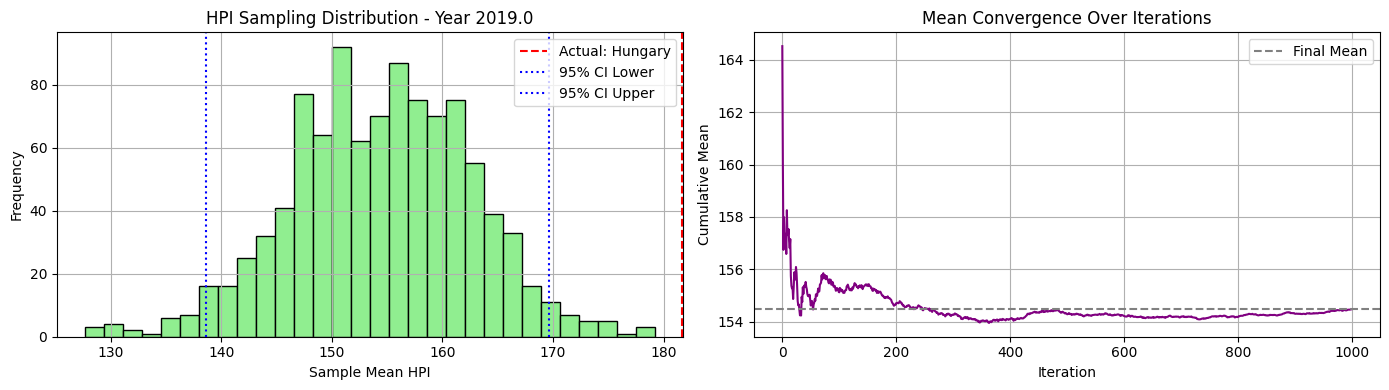


📅 Year 2020.0 - Available HPI values for sampling:
[213.74 203.12 213.74 113.93 106.71 126.56]


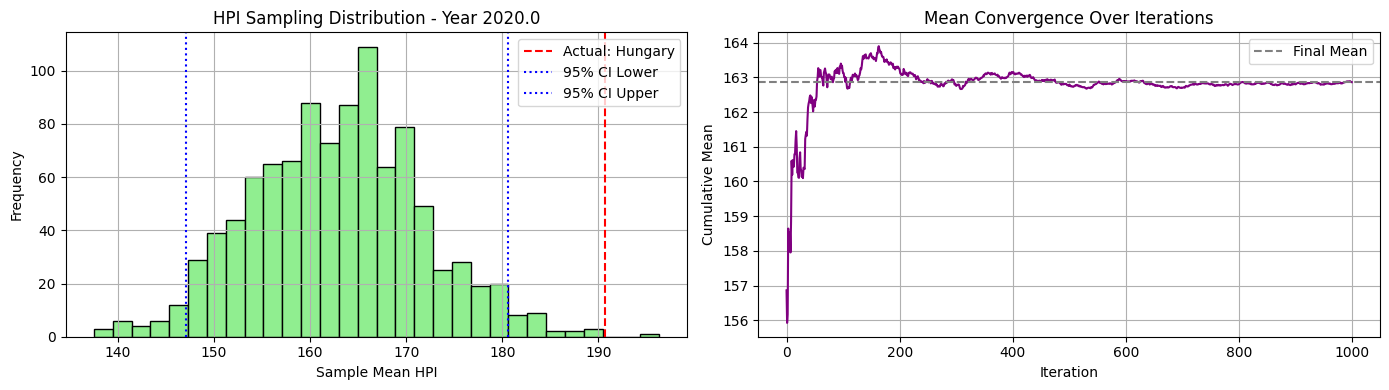


📅 Year 2021.0 - Available HPI values for sampling:
[248.26 214.9  248.26 120.7  121.41 143.73]


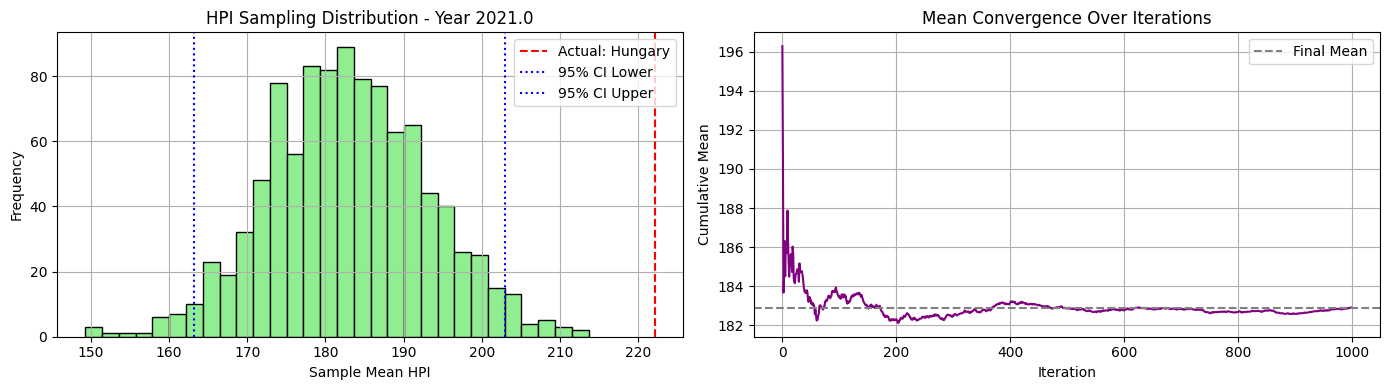


📅 Year 2022.0 - Available HPI values for sampling:
[292.18 230.   292.18 130.84 155.16 153.22]


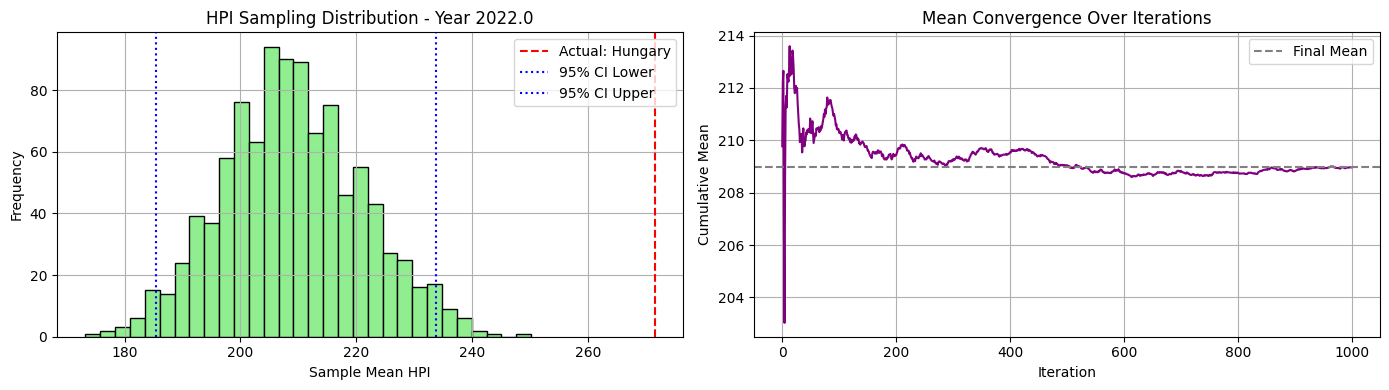


📅 Year 2023.0 - Available HPI values for sampling:
[309.37 245.75 309.37 134.8  157.88 143.99]


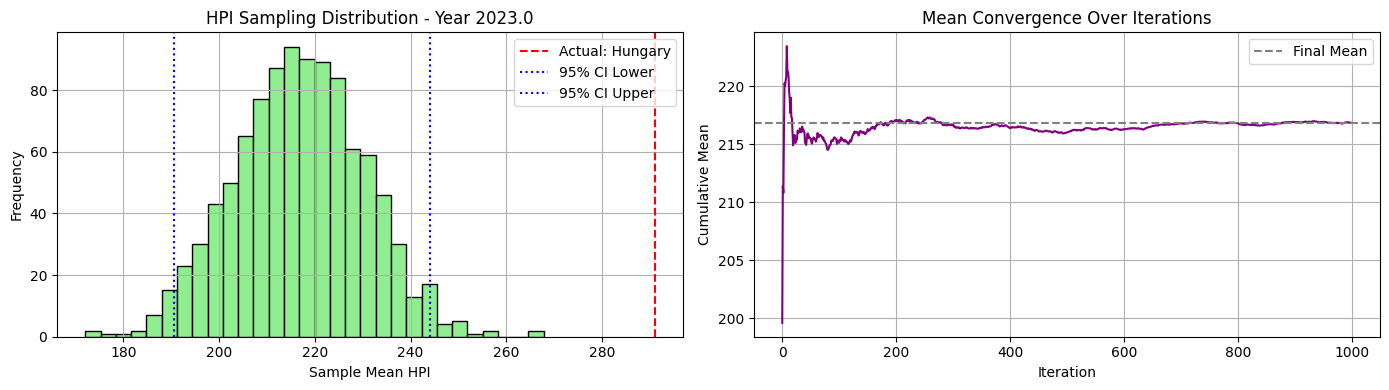


📅 Year 2024.0 - Available HPI values for sampling:
[328.24 269.02 328.24 138.61 186.66 142.46]


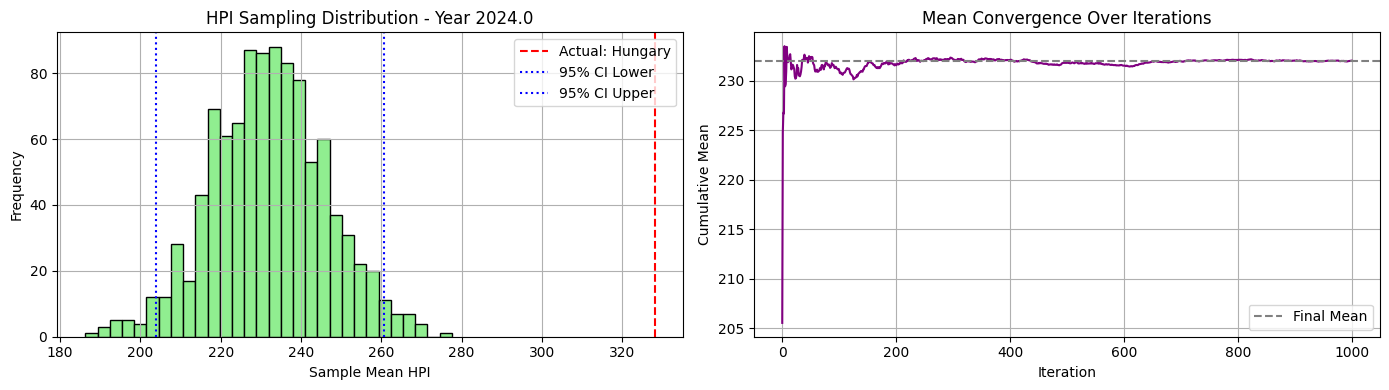

In [20]:
synthetic_00_52, excluded_00_52, actual_00_52 = estimate_hpi_by_cluster_sampling(hpi_winsorized, clusters_df, cluster_id=0, seed=52)

🔍 Cluster 1 selected. Excluding country: Ireland
📊 Sampling from countries: ['Austria', 'Belgium', 'Bulgaria', 'Croatia', 'Cyprus', 'Estonia', 'Finland', 'Greece', 'Latvia', 'Lithuania', 'Luxembourg', 'Malta', 'New Zealand', 'Portugal', 'Slovakia', 'Slovenia']

📅 Year 2010.0 - Available HPI values for sampling:
[100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.
 100. 100.]


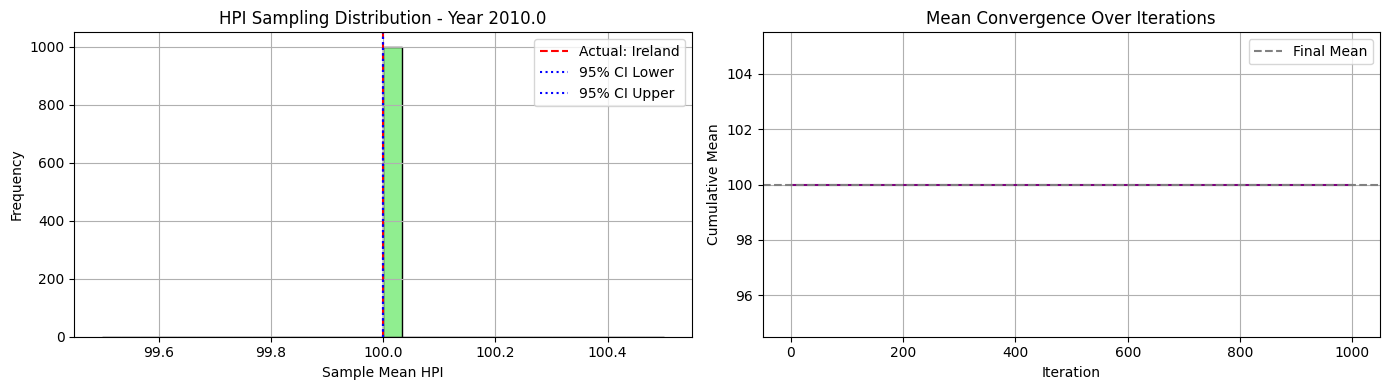


📅 Year 2011.0 - Available HPI values for sampling:
[104.22 103.58  94.49 100.16  96.68 108.47 103.17  94.53 110.42 106.6
 103.68  98.63 100.75  95.1   98.46 102.72]


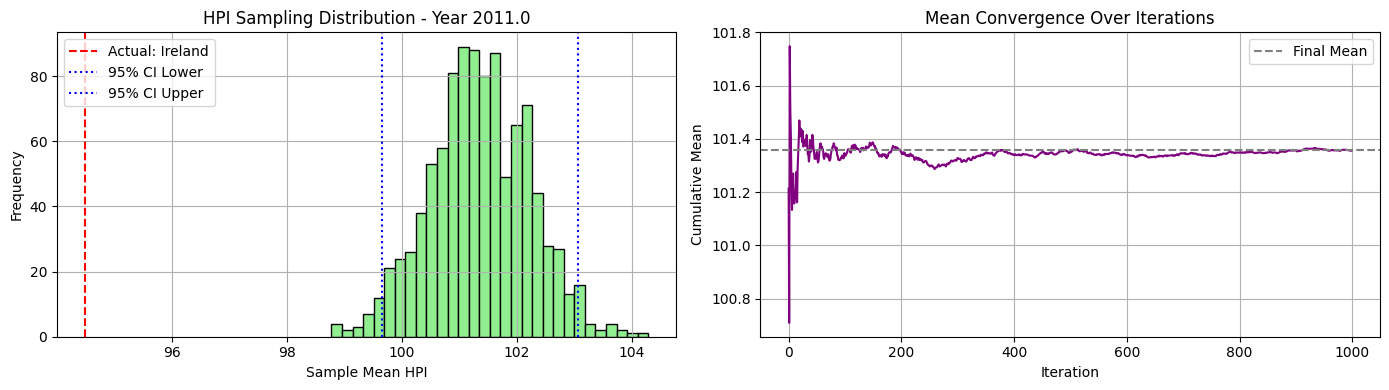


📅 Year 2012.0 - Available HPI values for sampling:
[117.13 106.02  92.69  98.62  91.54 116.34 105.64  88.37 113.71 106.36
 108.03 101.62 105.25  88.37  95.73  95.63]


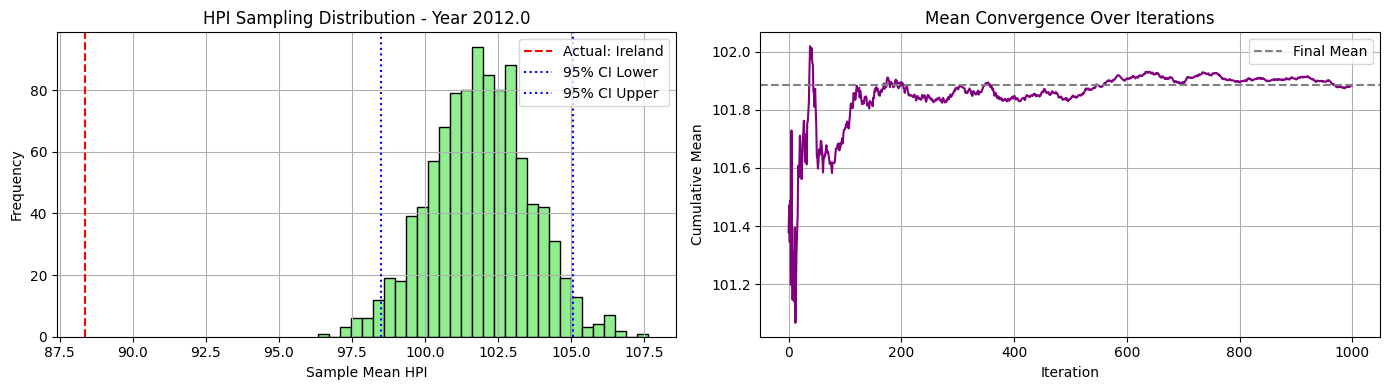


📅 Year 2013.0 - Available HPI values for sampling:
[122.59 107.59  90.65  94.7   85.58 128.77 106.87  85.58 121.5  107.65
 113.42 101.21 114.59  86.7   96.53  90.62]


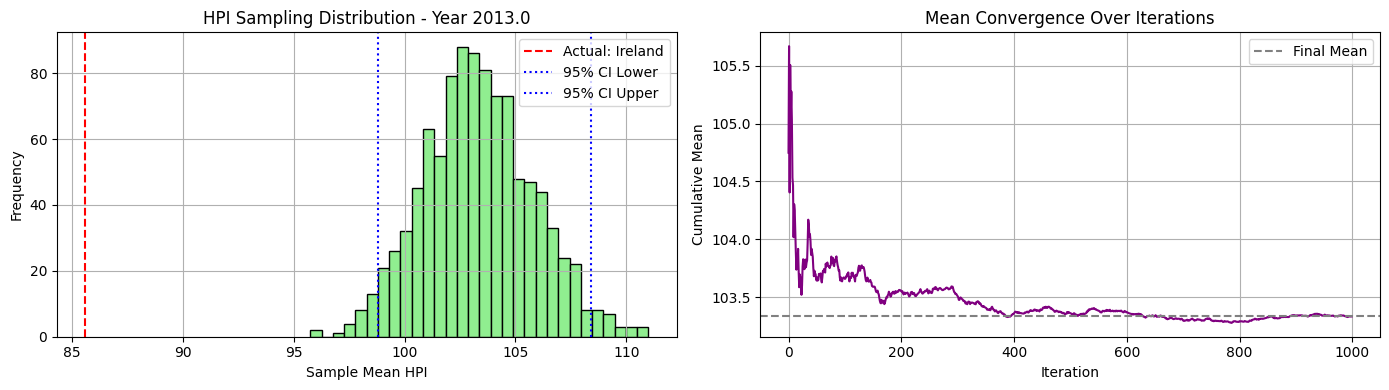


📅 Year 2014.0 - Available HPI values for sampling:
[126.79 107.22  91.95  93.19  84.64 146.41 106.5   84.64 128.78 114.57
 118.39 103.79 122.03  90.38  97.8   84.64]


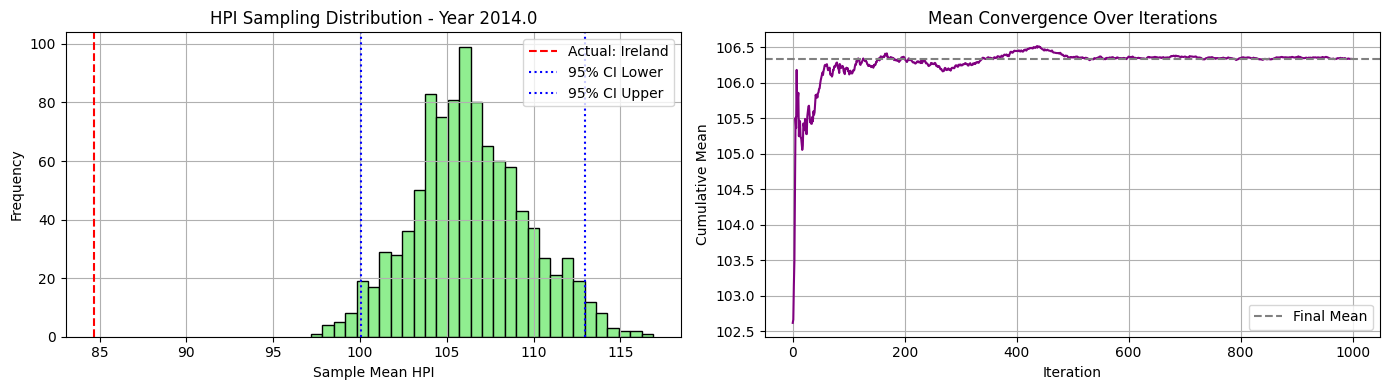


📅 Year 2015.0 - Available HPI values for sampling:
[132.06 109.17  94.51  90.54  84.67 156.46 106.5   84.67 124.46 118.76
 124.78 109.83 137.18  93.15 103.    85.32]


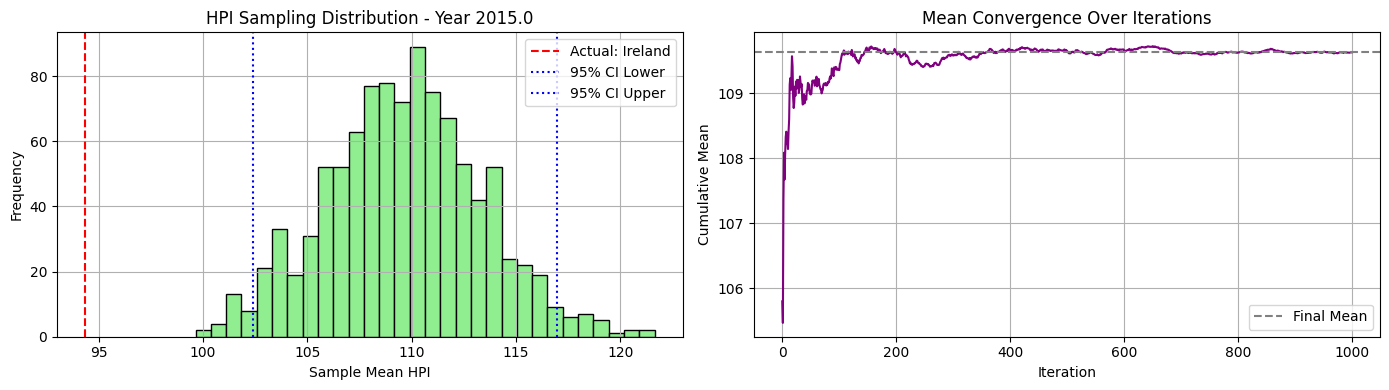


📅 Year 2016.0 - Available HPI values for sampling:
[141.76 111.72 101.15  91.33  88.1  163.86 107.86  88.1  135.02 125.16
 132.28 115.82 156.62  99.78 109.87  88.1 ]


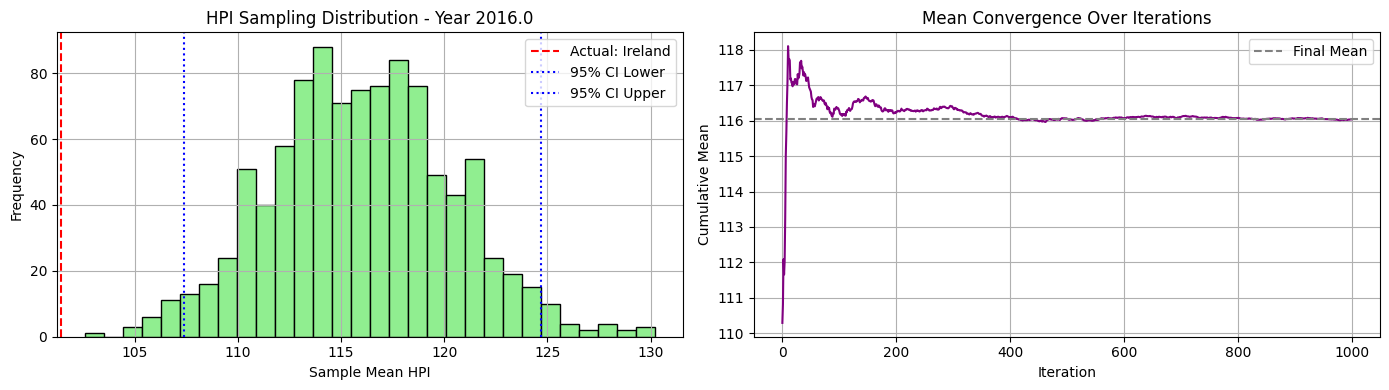


📅 Year 2017.0 - Available HPI values for sampling:
[147.08 115.66 109.91  94.84  88.54 172.91 109.02  88.54 146.87 136.34
 139.69 121.94 166.8  108.99 116.3   95.38]


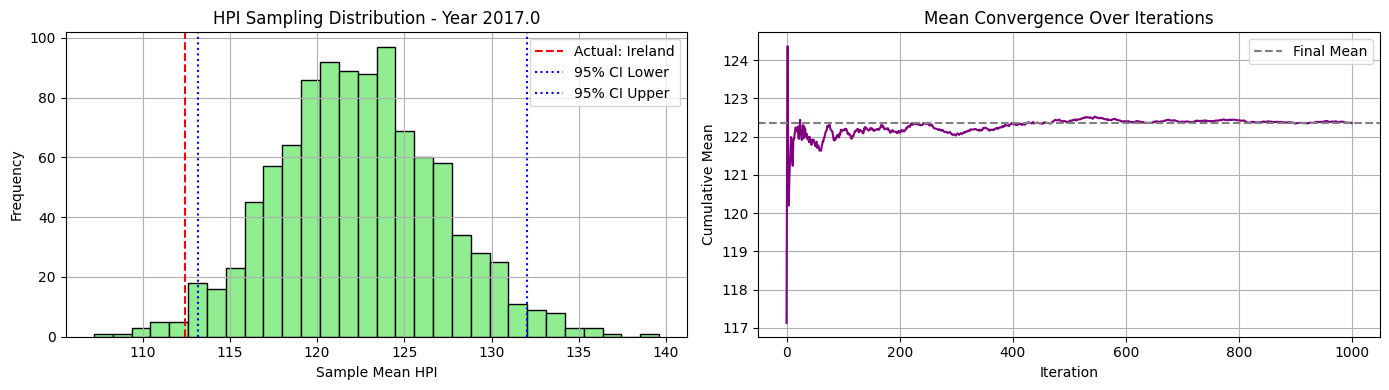


📅 Year 2018.0 - Available HPI values for sampling:
[157.24 119.16 117.15 100.59  90.72 183.13 110.06  90.72 160.92 146.29
 149.55 129.02 172.8  120.19 124.97 103.7 ]


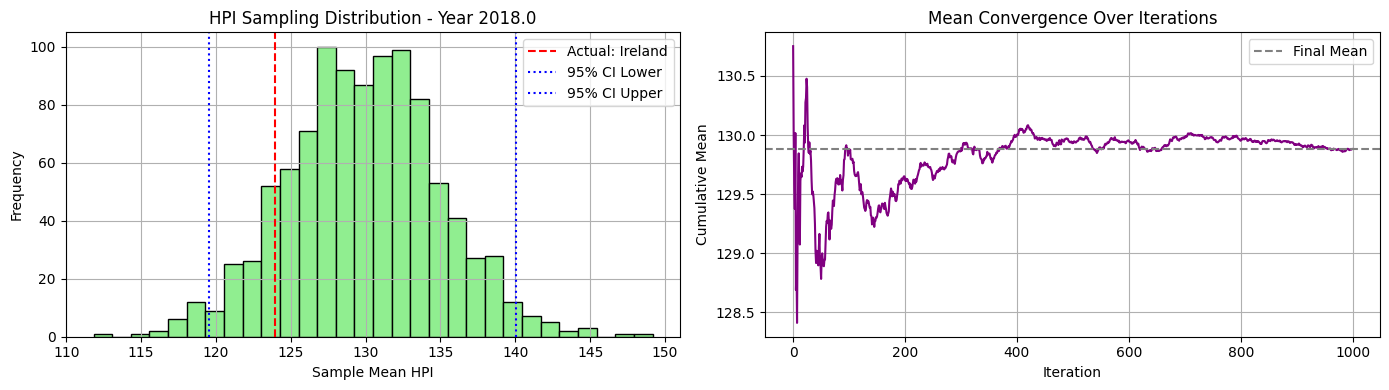


📅 Year 2019.0 - Available HPI values for sampling:
[163.43 123.62 124.2  109.64  97.25 195.98 110.52  97.25 175.33 156.3
 164.68 136.9  178.19 132.16 136.39 110.65]


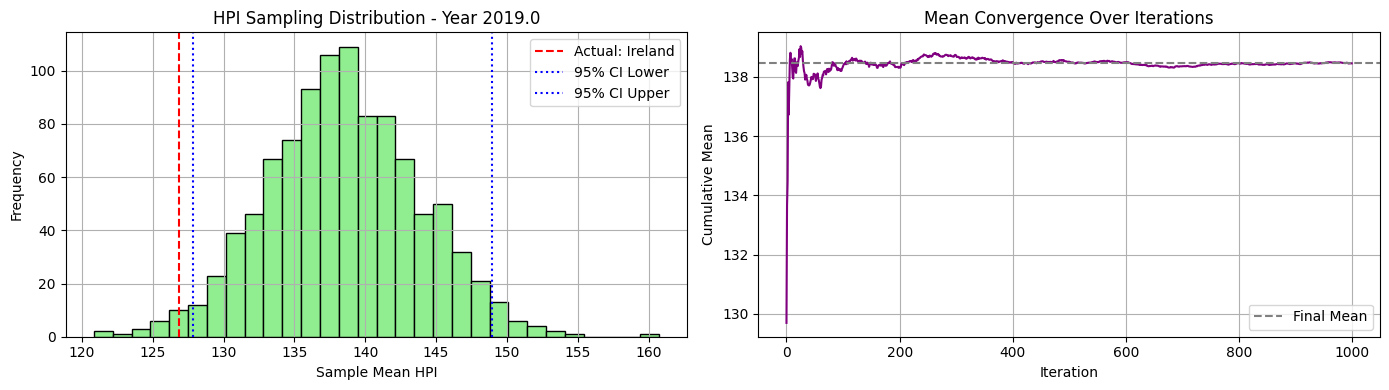


📅 Year 2020.0 - Available HPI values for sampling:
[174.92 128.92 129.87 118.06 106.71 207.78 112.49 106.71 181.42 167.66
 188.57 141.54 196.31 143.75 149.36 115.74]


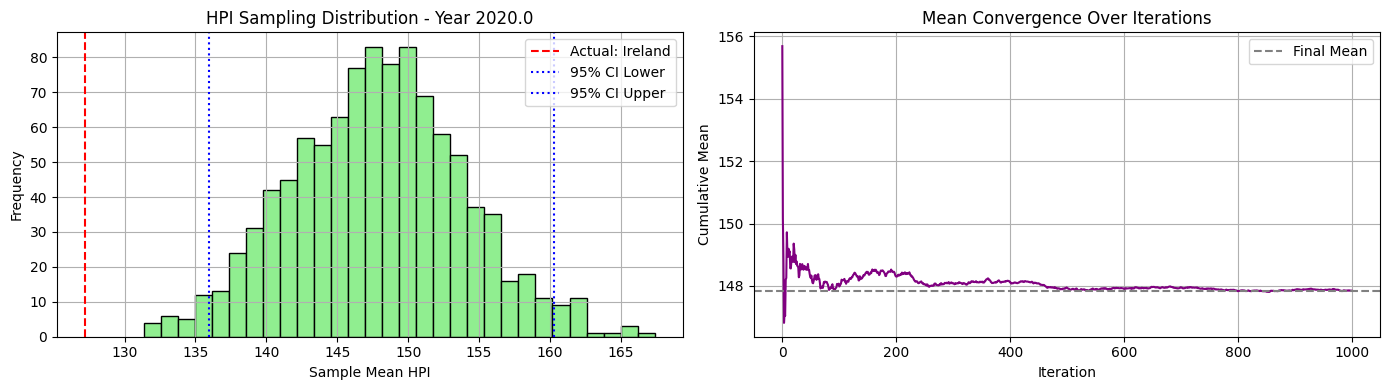


📅 Year 2021.0 - Available HPI values for sampling:
[195.48 137.52 141.14 126.64 112.34 239.04 117.62 112.34 201.18 194.58
 214.81 148.74 248.26 157.27 158.94 129.1 ]


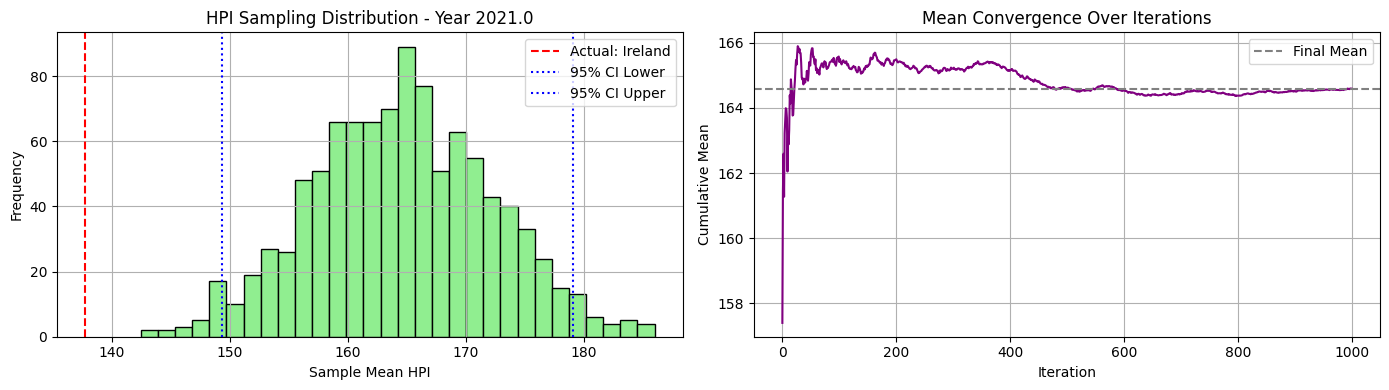


📅 Year 2022.0 - Available HPI values for sampling:
[215.62 145.12 160.59 145.44 118.98 292.18 118.98 118.98 229.01 231.64
 235.34 158.62 249.69 177.14 180.7  148.16]


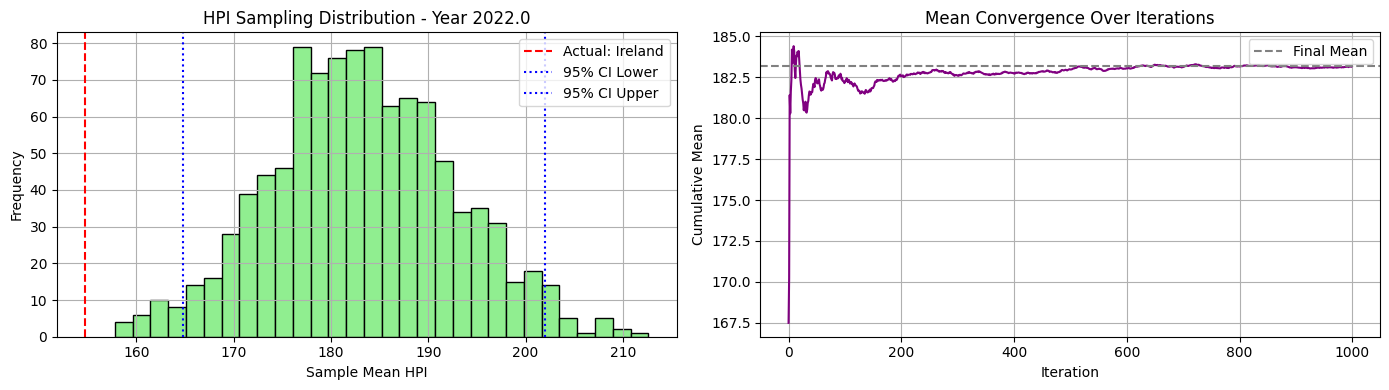


📅 Year 2023.0 - Available HPI values for sampling:
[212.08 148.52 176.43 162.82 112.27 309.37 112.27 112.27 237.56 254.38
 214.   168.5  233.54 191.66 180.36 158.88]


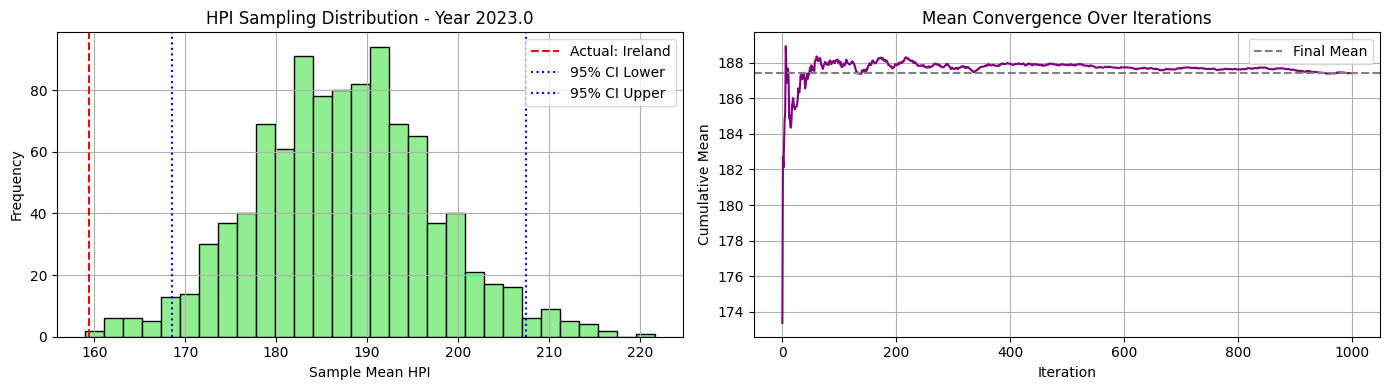


📅 Year 2024.0 - Available HPI values for sampling:
[207.62 153.31 205.53 179.7  119.1  328.24 119.1  119.1  247.54 279.12
 202.74 179.35 233.68 209.06 187.15 170.56]


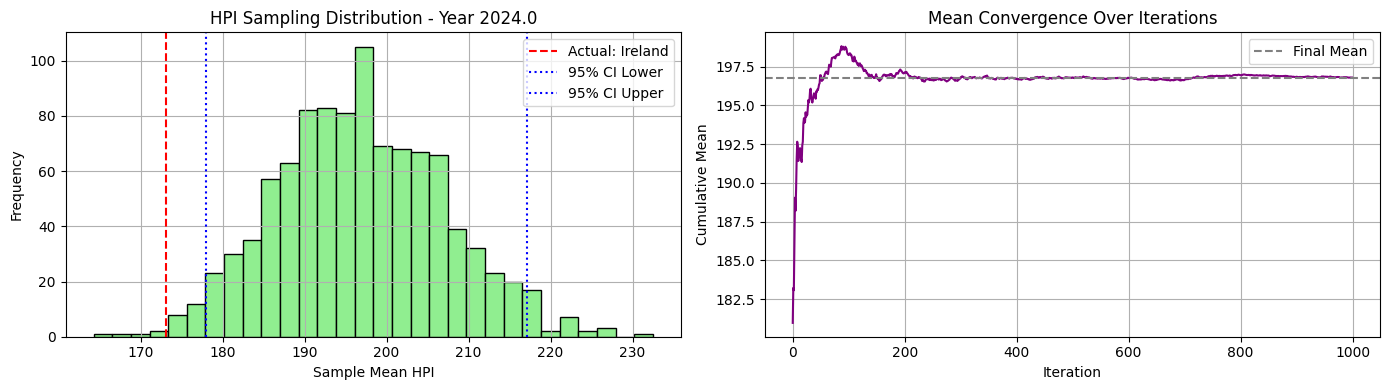

In [21]:
synthetic_01_52, excluded_01_52, actual_01_52 = estimate_hpi_by_cluster_sampling(hpi_winsorized, clusters_df, cluster_id=1, seed=52)

🔍 Cluster 2 selected. Excluding country: Israel
📊 Sampling from countries: ['Australia', 'Brazil', 'Canada', 'Czech Republic', 'Denmark', 'France', 'Germany', 'Iceland', 'Italy', 'Malaysia', 'Mexico', 'Netherlands', 'Norway', 'Peru', 'Philippines', 'Poland', 'Romania', 'Serbia', 'Singapore', 'South Africa', 'Spain', 'Sweden', 'Switzerland', 'Thailand', 'Turkey', 'United Kingdom', 'USA']

📅 Year 2010.0 - Available HPI values for sampling:
[100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.
 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.]


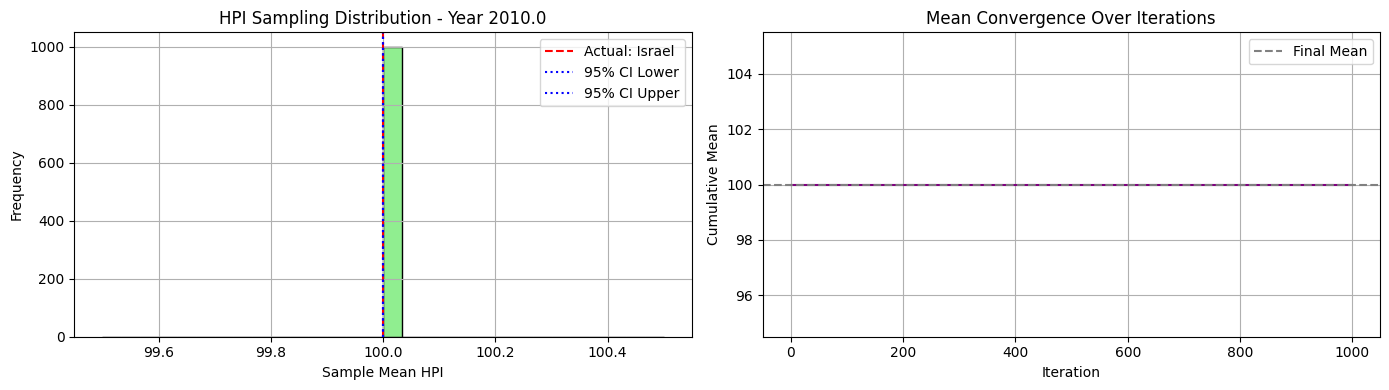


📅 Year 2011.0 - Available HPI values for sampling:
[ 97.84 110.52 105.75 100.02  98.29 105.69 102.42 105.5  101.36 109.83
 105.8   98.02 108.01 110.52 105.57 100.08  94.49  97.62 109.46 103.59
  94.49 102.58 107.51 104.26 108.8   98.54  97.24]


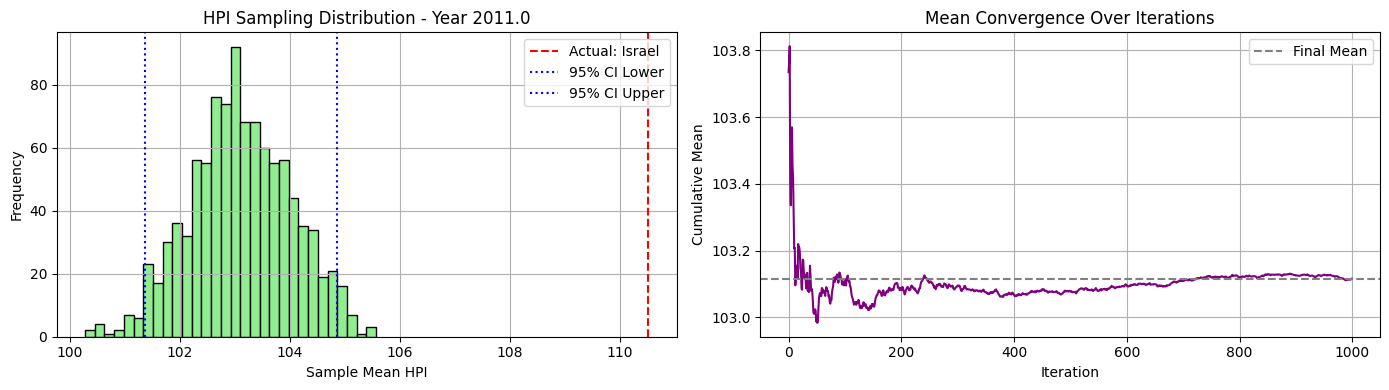


📅 Year 2012.0 - Available HPI values for sampling:
[ 97.53 124.02 110.62  98.56  95.67 105.11 105.48 112.38  98.77 124.02
 109.17  91.44 115.34 124.02 114.94  96.58  88.37  95.68 112.02 108.41
  88.37 103.86 113.72 107.63 120.68  98.92 101.82]


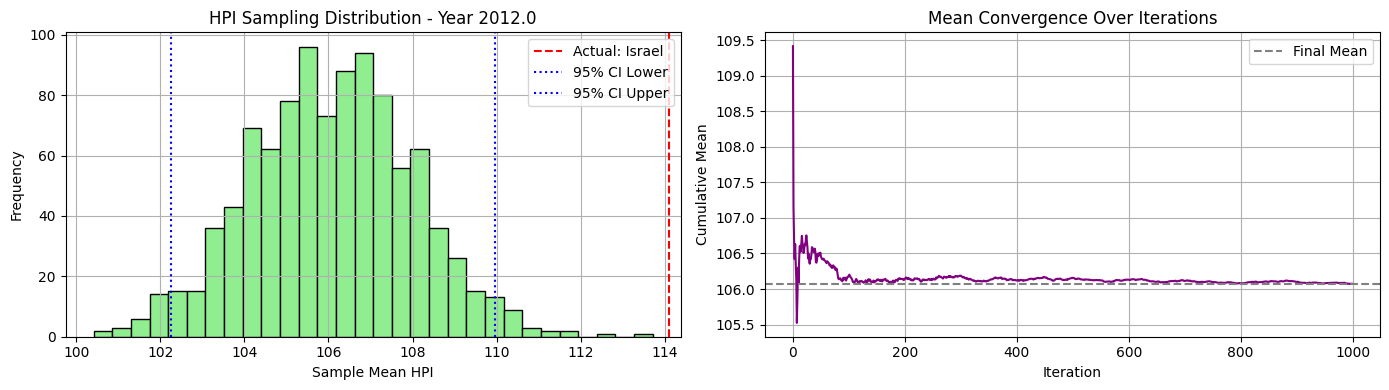


📅 Year 2013.0 - Available HPI values for sampling:
[103.99 136.52 112.76  98.58  99.37 103.13 108.68 119.18  92.38 136.52
 114.75  85.95 119.98 136.52 127.86  92.35  85.58  90.62 115.56 115.41
  85.58 109.22 118.3  115.99 134.46 101.46 111.83]


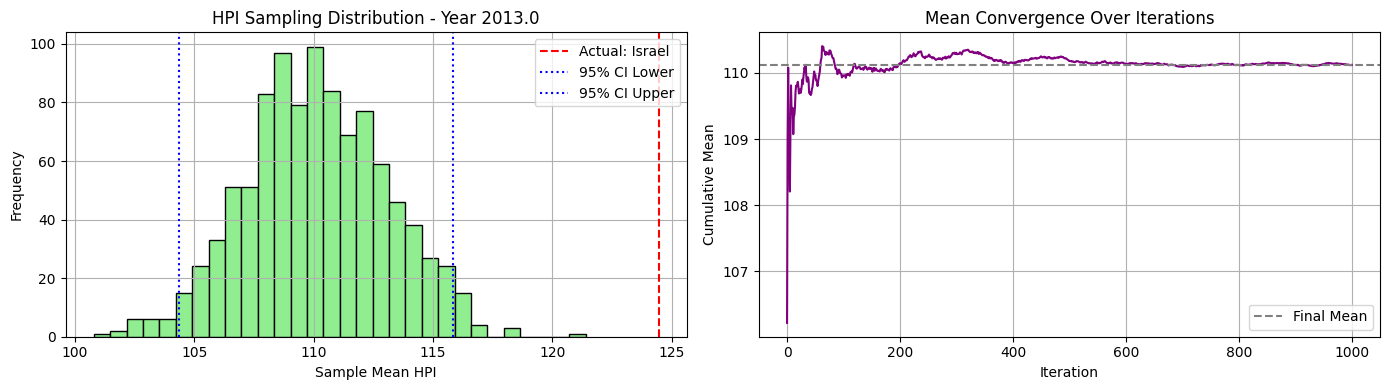


📅 Year 2014.0 - Available HPI values for sampling:
[113.41 151.67 118.86 101.   103.12 101.58 111.85 128.94  88.02 151.67
 119.64  86.66 123.24 151.67 142.76  93.27  84.64  95.77 112.25 123.99
  84.64 119.52 121.46 127.07 151.25 109.6  118.88]


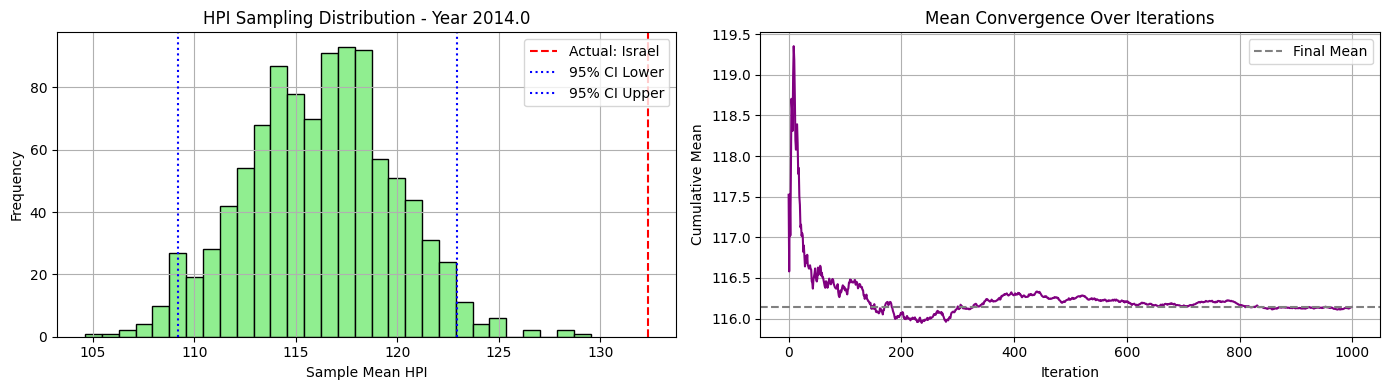


📅 Year 2015.0 - Available HPI values for sampling:
[123.65 156.16 128.43 105.01 110.29 100.22 117.12 139.74  84.67 162.89
 129.39  89.69 130.76 162.89 157.04  94.69  84.67  99.5  107.92 131.8
  84.67 135.2  124.08 136.   162.89 116.12 125.18]


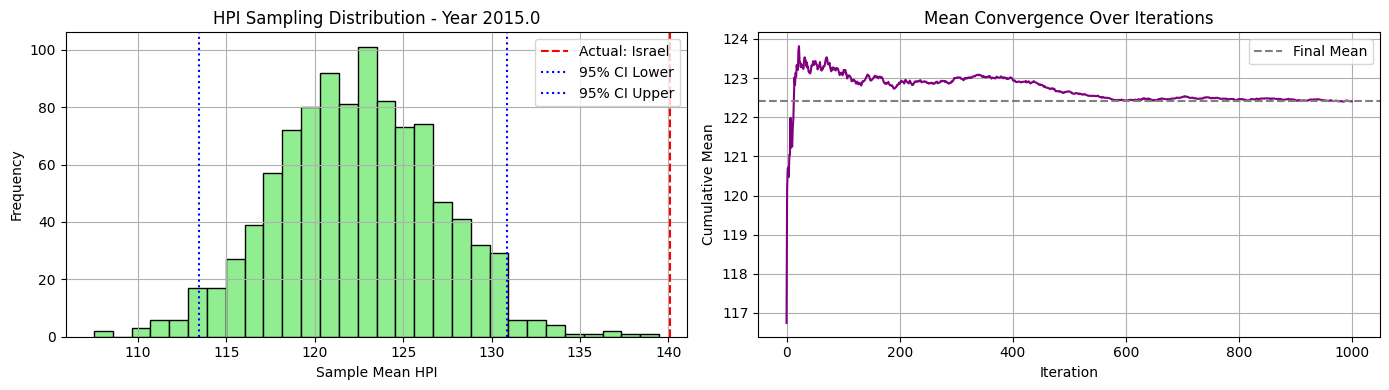


📅 Year 2016.0 - Available HPI values for sampling:
[130.44 151.94 148.66 112.52 115.5  101.25 125.93 154.59  88.1  172.75
 138.82  94.43 139.95 164.18 172.75  96.44  88.91 110.62 104.55 138.22
  88.1  146.34 124.32 142.4  172.75 124.27 131.88]


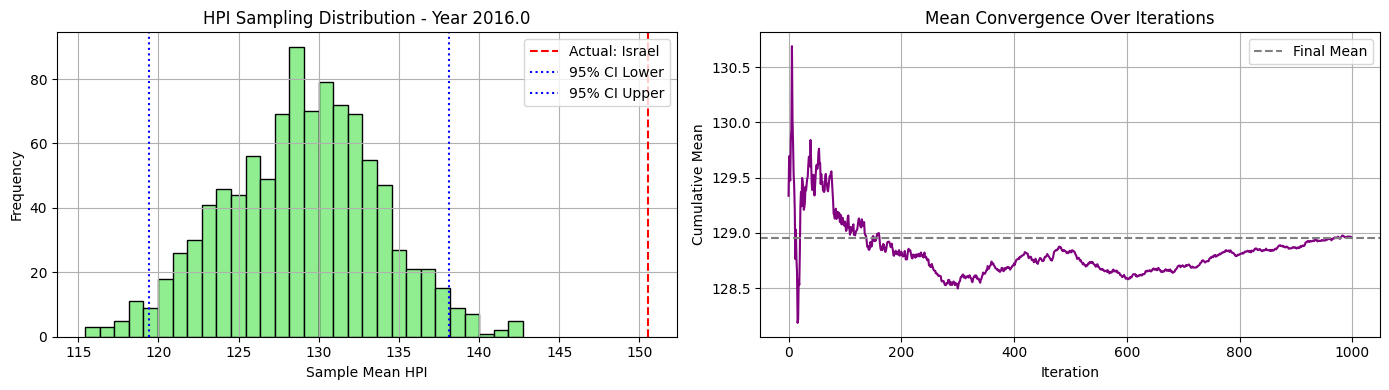


📅 Year 2017.0 - Available HPI values for sampling:
[141.34 149.02 172.3  125.7  120.63 104.46 133.62 183.99  88.54 183.99
 149.69 102.06 146.91 168.   178.82 100.16  93.93 115.3  103.4  143.94
  88.54 156.06 125.42 146.48 183.99 129.93 139.61]


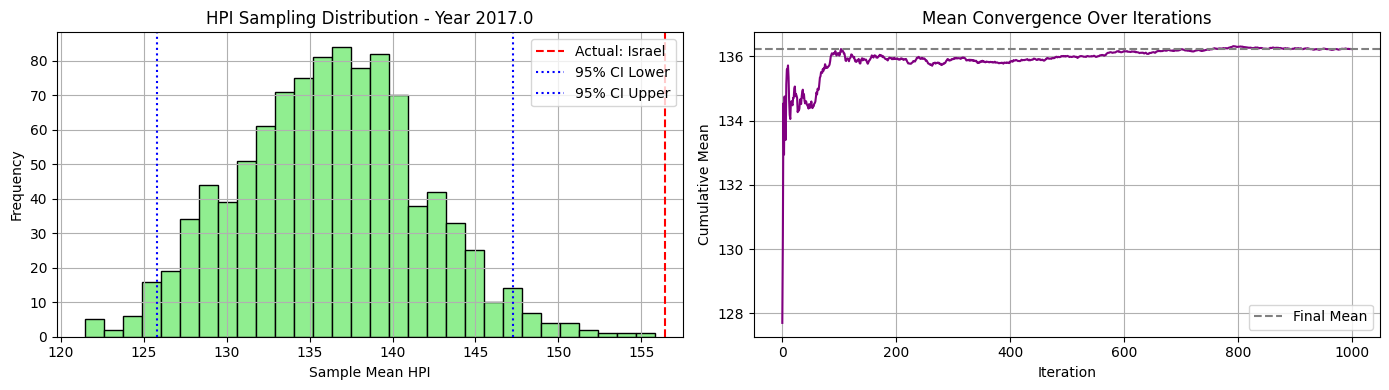


📅 Year 2018.0 - Available HPI values for sampling:
[139.3  149.81 178.24 136.52 126.31 107.52 142.52 191.85  90.72 191.85
 162.97 111.57 149.04 168.42 183.82 106.75  99.37 123.06 111.46 148.96
  90.72 154.6  129.16 153.9  191.85 134.04 147.35]


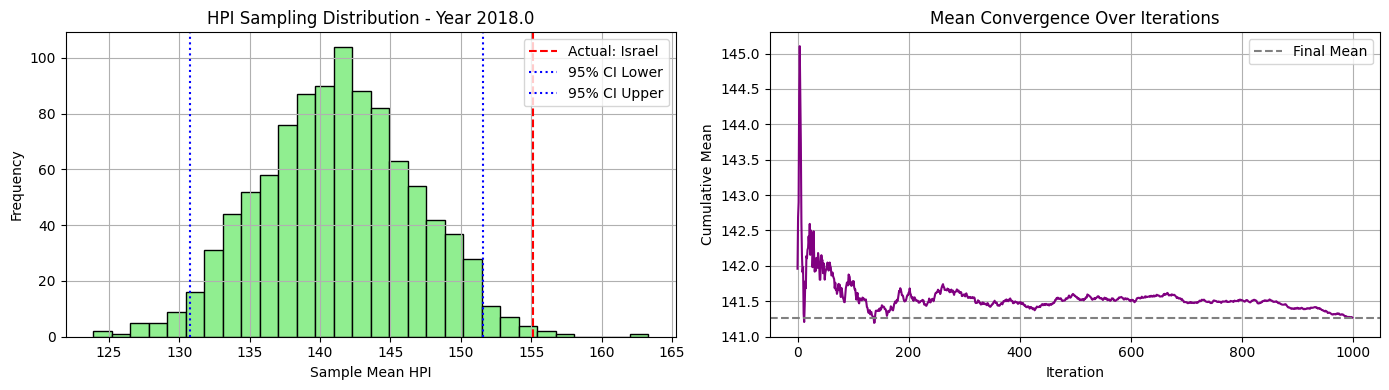


📅 Year 2019.0 - Available HPI values for sampling:
[133.64 155.06 179.4  149.02 129.62 111.1  150.75 198.37  97.25 196.06
 176.92 119.62 152.73 172.03 195.26 116.01 102.72 135.77 113.98 152.69
  97.25 158.44 133.99 155.1  198.37 135.37 153.14]


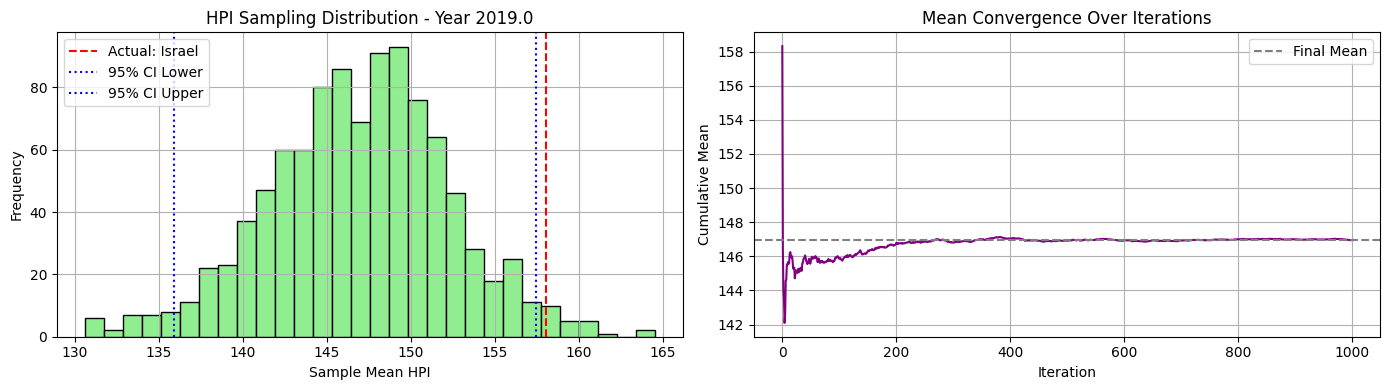


📅 Year 2020.0 - Available HPI values for sampling:
[140.85 166.92 190.73 161.56 136.24 116.89 162.48 213.74 106.71 198.37
 187.18 129.21 159.24 173.67 213.74 128.18 107.53 149.28 115.8  156.31
 106.71 165.09 137.31 160.6  213.74 139.24 163.52]


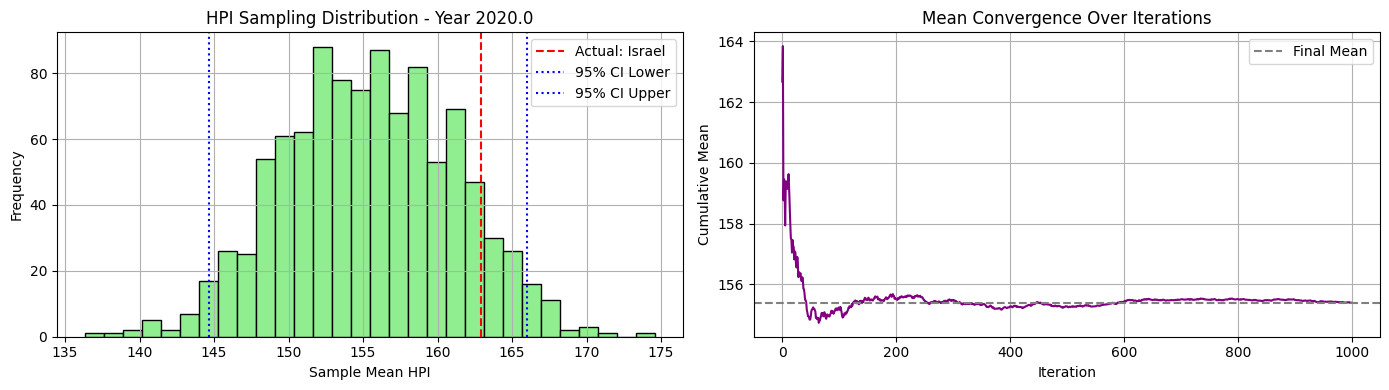


📅 Year 2021.0 - Available HPI values for sampling:
[165.39 180.02 214.88 193.46 152.2  124.38 181.28 248.26 112.34 200.69
 201.94 147.93 175.91 173.6  211.74 139.92 112.34 166.04 125.04 166.82
 112.34 181.79 145.16 164.23 248.26 150.58 188.56]


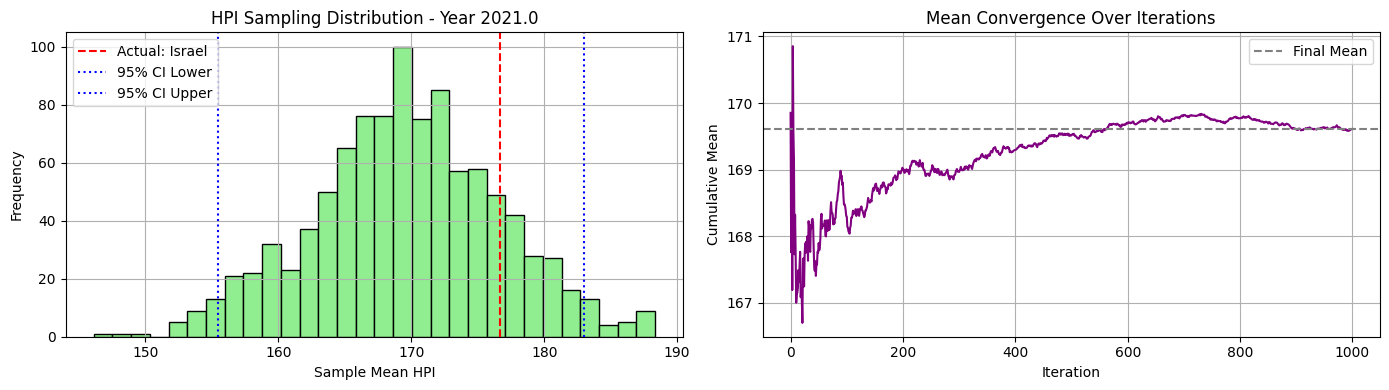


📅 Year 2022.0 - Available HPI values for sampling:
[179.02 185.16 235.32 226.15 151.49 132.1  190.42 292.18 118.98 207.75
 219.93 167.57 185.13 172.65 223.73 156.43 120.29 191.49 137.74 174.03
 118.98 188.27 154.42 169.16 292.18 164.55 213.  ]


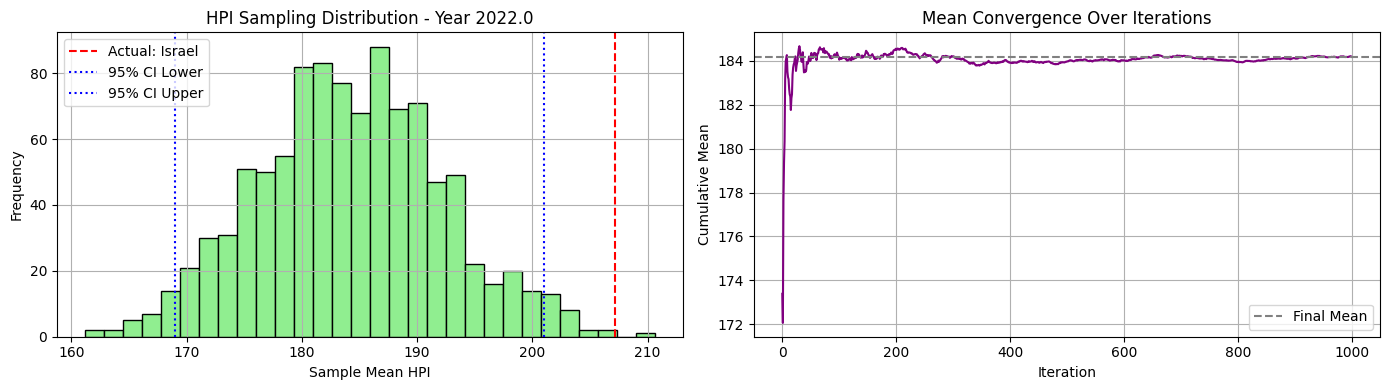


📅 Year 2023.0 - Available HPI values for sampling:
[178.65 191.27 221.05 222.4  151.24 131.52 174.25 309.37 112.27 216.19
 243.89 164.36 184.12 175.16 248.04 170.23 124.06 209.99 148.01 176.62
 112.27 178.36 157.81 174.79 309.37 165.   221.72]


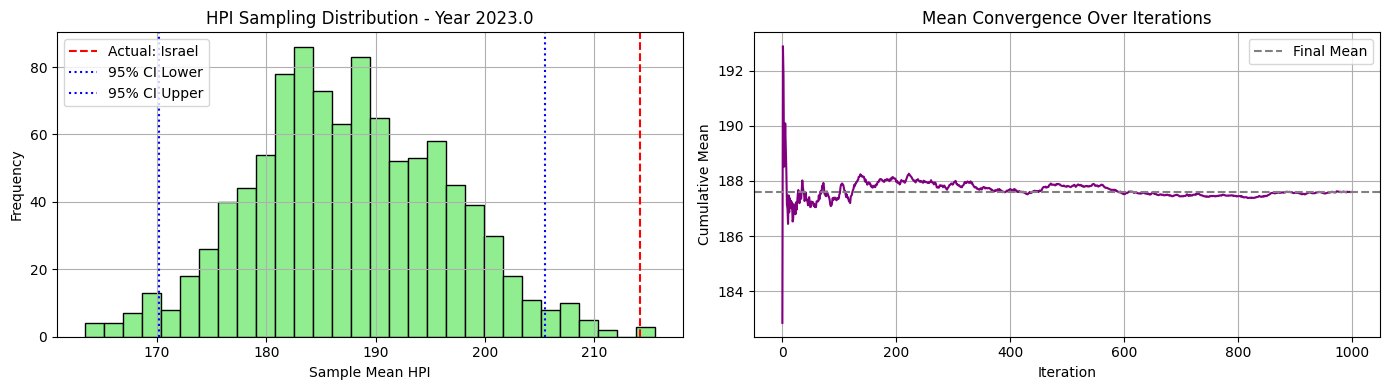


📅 Year 2024.0 - Available HPI values for sampling:
[192.53 203.78 217.35 233.42 156.73 126.68 171.5  328.24 119.1  225.06
 266.38 177.7  189.05 175.38 256.03 195.72 130.34 220.7  155.12 178.1
 119.1  178.49 160.56 178.06 328.24 166.38 231.23]


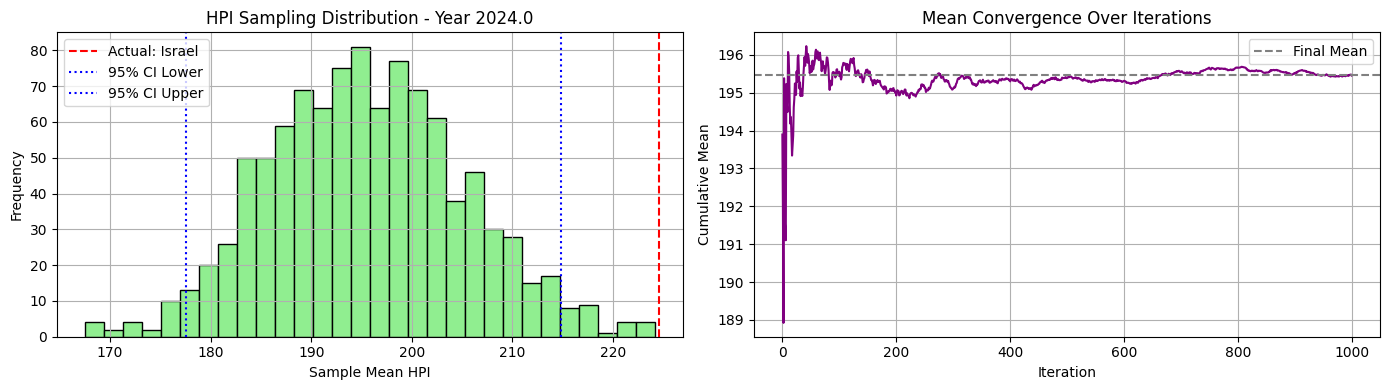

In [22]:
synthetic_02_52, excluded_02_52, actual_02_52 = estimate_hpi_by_cluster_sampling(hpi_winsorized, clusters_df, cluster_id=2, seed=52)

### Compute metrics
* Compute MSE from synthetic data versus the real one from the country excluded
* Compute MAE from synthetic data versus the real one from the country excluded

In [23]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [24]:
def compute_global_mse_mae(synthetic_dicts, actual_dicts):
    """
    Computes global MSE and MAE across multiple synthetic vs. actual HPI dictionaries.

    Parameters:
    - synthetic_dicts: list of dicts with synthetic HPI values per year
    - actual_dicts: list of dicts with actual HPI values per year

    Returns:
    - mse: Mean Squared Error
    - mae: Mean Absolute Error
    """

    y_true = []
    y_pred = []

    for synth, actual in zip(synthetic_dicts, actual_dicts):
        common_years = set(synth.keys()) & set(actual.keys())
        for year in common_years:
            s_val = synth[year]
            a_val = actual[year]
            if not (np.isnan(s_val) or np.isnan(a_val)):
                y_pred.append(s_val)
                y_true.append(a_val)

    mse = mean_squared_error(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)

    return mse, mae

In [25]:
import re

def evaluate_all_seeds(synthetic_groups, actual_groups):
    """
    Evaluates multiple sets of synthetic vs. actual HPI dictionaries,
    and stores error metrics in a dictionary keyed by seed number.

    Parameters:
    - synthetic_groups: dict with keys like 'synthetic_42' and values as lists of synthetic dicts
    - actual_groups: dict with keys like 'actual_42' and values as lists of actual dicts

    Returns:
    - metrics_by_seed: dict with seed as key and {'mse': ..., 'mae': ...} as value
    """
    metrics_by_seed = {}

    for synthetic_key in synthetic_groups:
        # Extract seed number from the synthetic key
        match = re.search(r'_(\d+)$', synthetic_key)
        if not match:
            raise ValueError(f"Could not extract seed from key: {synthetic_key}")
        
        seed = int(match.group(1))
        actual_key = f'actual_{seed}'  # construct matching key for actual_groups

        if actual_key not in actual_groups:
            raise KeyError(f"Missing key in actual_groups: {actual_key}")

        synthetic_dicts = synthetic_groups[synthetic_key]
        actual_dicts = actual_groups[actual_key]

        mse, mae = compute_global_mse_mae(synthetic_dicts, actual_dicts)
        metrics_by_seed[seed] = {'mse': mse, 'mae': mae}

    return metrics_by_seed

In [26]:
synthetic_32 = [synthetic_00_32, synthetic_01_32, synthetic_02_32]
actual_32 = [actual_00_32, actual_01_32, actual_02_32]

synthetic_43 = [synthetic_00_43, synthetic_01_43, synthetic_02_43]
actual_43 = [actual_00_43, actual_01_43, actual_02_43]

synthetic_52 = [synthetic_00_52, synthetic_01_52, synthetic_02_52]
actual_52 = [actual_00_52, actual_01_52, actual_02_52]

In [27]:
synthetic_groups = {
    'synthetic_32': synthetic_32,
    'synthetic_43': synthetic_43,
    'synthetic_52': synthetic_52
}

actual_groups = {
    'actual_32': actual_32,
    'actual_43': actual_43,
    'actual_52': actual_52
}

In [28]:
results = evaluate_all_seeds(synthetic_groups, actual_groups)

In [29]:
for seed, metrics in results.items():
    print(f"🔢 Seed {seed} → MSE: {metrics['mse']:.4f}, MAE: {metrics['mae']:.4f}")

🔢 Seed 32 → MSE: 1368.5416, MAE: 27.7277
🔢 Seed 43 → MSE: 1282.2566, MAE: 25.4674
🔢 Seed 52 → MSE: 758.6714, MAE: 20.8145


In [30]:
def summarize_error_metrics(metrics_by_seed):
    """
    Computes the mean and median of MSE and MAE values across multiple seeds.

    Parameters:
    - metrics_by_seed: dictionary with seed as key and {'mse': ..., 'mae': ...} as value

    Returns:
    - summary: dictionary with keys 'mse_mean', 'mse_median', 'mae_mean', 'mae_median'
    """
    mse_values = [metrics['mse'] for metrics in metrics_by_seed.values()]
    mae_values = [metrics['mae'] for metrics in metrics_by_seed.values()]

    summary = {
        'mse_mean': np.mean(mse_values),
        'mse_median': np.median(mse_values),
        'mae_mean': np.mean(mae_values),
        'mae_median': np.median(mae_values)
    }

    return summary

In [31]:
summary = summarize_error_metrics(results)

In [32]:
print("📈 Error Summary Across Seeds:")
print(f"Mean MSE: {summary['mse_mean']:.4f}")
print(f"Median MSE: {summary['mse_median']:.4f}")
print(f"Mean MAE: {summary['mae_mean']:.4f}")
print(f"Median MAE: {summary['mae_median']:.4f}")

📈 Error Summary Across Seeds:
Mean MSE: 1136.4899
Median MSE: 1282.2566
Mean MAE: 24.6699
Median MAE: 25.4674


### Log performance of the experiment
* Import dataframe for the logs
* Define the parameters for introduce the results
* Export the dataframe

In [39]:
from datetime import datetime

In [33]:
log_df = pd.read_parquet('../data/log_performance/log_performance_cluster_sampling.parquet')

In [41]:
new_entry = {
    'experiment_name': 'baseline_kmeans_plusplus_3_countries_exclude',
    'experiment_date': datetime.now().strftime('%Y-%m-%d %H:%M'),
    'clustering_model': 'KMeans',
    'n_clusters': 3,
    'init_method': 'k-means++',
    'n_init': 10,
    'max_iter': 100,
    'random_state': 42,
    'used_elbow_method': False,
    'used_silhouette_score': False,
    'used_2nd_derivate_for_inflection': False,
    'silhouette_score': None,
    'transformations_clustering': 'StandardScaler, log transformation',
    'transformations_sampling': 'Winsorization, rounding',
    'outliers_handling_clustering': None,
    'outliers_handling_sampling': 'Winsorization',
    'sampling_method': 'bootstrap',
    'mse_score': summary['mse_mean'],
    'mae_score': summary['mae_mean'],
    'sampling_seed': (32,43,52),
    'excluded_countries_count': 3,
    'used_all_variables_for_clustering': True,
    'used_pca_for_clustering': False
}

In [42]:
log_df = pd.concat([log_df, pd.DataFrame([new_entry])], ignore_index=True)

C:\Users\lucas\AppData\Local\Temp\ipykernel_18592\612794693.py:1: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  log_df = pd.concat([log_df, pd.DataFrame([new_entry])], ignore_index=True)


In [34]:
log_df

,experiment_name,experiment_date,clustering_model,n_clusters,init_method,n_init,max_iter,random_state,used_elbow_method,used_silhouette_score,...,outliers_handling_clustering,used_all_variables_for_clustering,used_pca_for_clustering,transformations_sampling,outliers_handling_sampling,sampling_method,sampling_seed,excluded_countries_count,mse_score,mae_score
0,baseline_kmeans_random,2025-09-07 18:52,KMeans,3,random,10.0,100.0,42,False,False,...,None,True,False,"Winsorization, rounding",Winsorization,boostrap,None,1.0,1280.833748,27.767857
1,baseline_continent_clusters,2025-09-07 22:44,continent based,4,None,NaN,NaN,42,None,None,...,None,True,False,"Winsorization, rounding",Winsorization,boostrap,None,1.0,1652.241439,27.672956
2,baseline_kmeans_plusplus,2025-09-09 20:56,KMeans,3,k-means++,10.0,100.0,42,False,False,...,None,True,False,"Winsorization, rounding",Winsorization,boostrap,None,1.0,1268.379506,25.588507
3,kmeans_plusplus_without_outliers,2025-09-10 16:20,KMeans,3,k-means++,10.0,100.0,42,False,False,...,Winsorization,True,False,"Winsorization, rounding",Winsorization,boostrap,None,1.0,566.926791,19.297330
4,kmeans_plusplus_elbow_silhouette_5,2025-09-10 19:38:00,KMeans,5,k-means++,10.0,100.0,42,False,False,...,None,True,False,"Winsorization, rounding",Winsorization,boostrap,None,1.0,1889.093940,29.773409
5,kmeans_plusplus_c2_ni10_maxi100,2025-09-11 17:54,KMeans,2,k-means++,10.0,100.0,42,True,True,...,None,True,False,"Winsorization, rounding",Winsorization,boostrap,None,1.0,253.672048,12.191757
6,kmeans_plusplus_c2_ni18_maxi300,2025-09-11 17:54,KMeans,2,k-means++,18.0,300.0,42,True,True,...,None,True,False,"Winsorization, rounding",Winsorization,boostrap,None,1.0,208.801705,10.990371
7,kmeans_plusplus_c2_ni20_maxi500,2025-09-11 17:54,KMeans,2,k-means++,20.0,500.0,42,True,True,...,None,True,False,"Winsorization, rounding",Winsorization,boostrap,None,1.0,208.801705,10.990371
8,kmeans_plusplus_c3_ni20_maxi500,2025-09-11 17:54,KMeans,3,k-means++,20.0,500.0,42,True,True,...,None,True,False,"Winsorization, rounding",Winsorization,boostrap,None,1.0,1268.379506,25.588507
9,kmeans_plusplus_c2_ni10_maxi100_no,2025-09-11 19:48,KMeans,2,k-means++,10.0,100.0,42,True,True,...,Winsorization,True,False,"Winsorization, rounding",Winsorization,boostrap,None,1.0,881.604066,24.848810


In [35]:
log_df.at[log_df.index[-1], 'mse_score'] = summary['mse_mean']
log_df.at[log_df.index[-1], 'mae_score'] = summary['mae_mean']

In [36]:
log_df

,experiment_name,experiment_date,clustering_model,n_clusters,init_method,n_init,max_iter,random_state,used_elbow_method,used_silhouette_score,...,outliers_handling_clustering,used_all_variables_for_clustering,used_pca_for_clustering,transformations_sampling,outliers_handling_sampling,sampling_method,sampling_seed,excluded_countries_count,mse_score,mae_score
0,baseline_kmeans_random,2025-09-07 18:52,KMeans,3,random,10.0,100.0,42,False,False,...,None,True,False,"Winsorization, rounding",Winsorization,boostrap,None,1.0,1280.833748,27.767857
1,baseline_continent_clusters,2025-09-07 22:44,continent based,4,None,NaN,NaN,42,None,None,...,None,True,False,"Winsorization, rounding",Winsorization,boostrap,None,1.0,1652.241439,27.672956
2,baseline_kmeans_plusplus,2025-09-09 20:56,KMeans,3,k-means++,10.0,100.0,42,False,False,...,None,True,False,"Winsorization, rounding",Winsorization,boostrap,None,1.0,1268.379506,25.588507
3,kmeans_plusplus_without_outliers,2025-09-10 16:20,KMeans,3,k-means++,10.0,100.0,42,False,False,...,Winsorization,True,False,"Winsorization, rounding",Winsorization,boostrap,None,1.0,566.926791,19.297330
4,kmeans_plusplus_elbow_silhouette_5,2025-09-10 19:38:00,KMeans,5,k-means++,10.0,100.0,42,False,False,...,None,True,False,"Winsorization, rounding",Winsorization,boostrap,None,1.0,1889.093940,29.773409
5,kmeans_plusplus_c2_ni10_maxi100,2025-09-11 17:54,KMeans,2,k-means++,10.0,100.0,42,True,True,...,None,True,False,"Winsorization, rounding",Winsorization,boostrap,None,1.0,253.672048,12.191757
6,kmeans_plusplus_c2_ni18_maxi300,2025-09-11 17:54,KMeans,2,k-means++,18.0,300.0,42,True,True,...,None,True,False,"Winsorization, rounding",Winsorization,boostrap,None,1.0,208.801705,10.990371
7,kmeans_plusplus_c2_ni20_maxi500,2025-09-11 17:54,KMeans,2,k-means++,20.0,500.0,42,True,True,...,None,True,False,"Winsorization, rounding",Winsorization,boostrap,None,1.0,208.801705,10.990371
8,kmeans_plusplus_c3_ni20_maxi500,2025-09-11 17:54,KMeans,3,k-means++,20.0,500.0,42,True,True,...,None,True,False,"Winsorization, rounding",Winsorization,boostrap,None,1.0,1268.379506,25.588507
9,kmeans_plusplus_c2_ni10_maxi100_no,2025-09-11 19:48,KMeans,2,k-means++,10.0,100.0,42,True,True,...,Winsorization,True,False,"Winsorization, rounding",Winsorization,boostrap,None,1.0,881.604066,24.848810


In [37]:
log_df.to_parquet('../data/log_performance/log_performance_cluster_sampling.parquet')